<div style="border:solid green 2px; padding: 20px">
    
<b>Алексей, привет!</b> Мы рады тебя видеть на территории код-ревьюеров. 😎 Ты проделал большую работу над проектом, но давай познакомимся и сделаем его еще лучше! У нас тут своя атмосфера и несколько правил:


1. Это снова Александр Матвеевский. Я работаю код-ревьюером, моя основная цель — не указать на совершенные тобою ошибки, а поделиться своим опытом и помочь тебе стать аналитиком данных.
2. Общаемся на ты.
3. Если хочешь написать, спросить - не нужно стесняться. Только выбери свой цвет для комментария.  
4. Это учебный проект, тут можно не бояться сделать ошибку.  
5. У нас с тобой 6 попыток для сдачи проекта   
6. Let's Go!

---

Я буду красить комментарии цветом, пожалуйста, не удаляй их:

<div class="alert alert-block alert-danger">✍
    

__Комментарий от ревьюера №1__

Такой комментарий нужно исправить обязательно, он критически влияет на удачное выполнение проекта.
</div>
    
---

<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__


Такой комментарий является рекомендацией или советом. Можешь использовать их на своё усмотрение.
</div>

---

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Такой комментарий  говорит о том, что было сделано что-то качественное и правильное =)
</div>
    
---
    
Предлагаю работать над проектом в диалоге: если ты что-то меняешь в проекте или отвечаешь на мои комментарии — пиши об этом. Мне будет легче отследить изменения, если ты выделишь свои комментарии:   
    
<div class="alert alert-info"> <b>Комментарии студента:</b> Например, вот так.</div>
    
Всё это поможет выполнить повторную проверку твоего проекта оперативнее. Если будут какие-нибудь вопросы по моим комментариям, пиши, будем разбираться вместе :)    
    
---

# Разработка модели для прогнозирования задержек доставки заказов по клиентам для логистической компании CargaPronto

- Автор: Федоров Алексей Анатольевич
- Дата: 06.10.2026

<a id='цели-и-задачи-проекта'></a>
## Цели и задачи проекта
Компания CargaPronto выполняет доставку заказов обслуживая Пуэрто-Рико и США. Клиенты находятся в достаточно разных уголках: как в населённых районах и городах, так и в удалённых районах. И в последнее время стала ощутимой проблема, что 55% заказов доставляются с задержкой. Это вероятно связано с разросшейся базой клиентов: их расположением и поведением. Есть клиенты, расположенные в удалённых районах, а есть клиенты, которые часть заказов часто возвращают. Эти два фактора снижают производительность работы курьеров и требуют внимания на стадии планирования доставки. Так как отсюда возникает дефицит свободных курьеров и задержки в доставках.

Поэтому, чтобы сразу выявлять заказы с высокой вероятностью задержки доставки, требуется создать модель, обученную на данных из ERP системы компании, которые описывают заказы, результат доставки, как цлевую переменную, и самих клиентов.
Модель должна на стадии оформления заказа предупреждать оператора-логиста, что по данному заказу вероятность задержки >70% и поэтому, рекомендуется сравнить штраф от возможной задержки со стоимостью приоритетной доставки, чтобы обоснованно поставить данный заказ приоритетным и избежать задержки и штрафа.

Нарушения SLA, если их много, так же влияют на репутацию компании, вызывают раздражение компаний-партнёров, но если заранее знать о риске по конкретным заказам, то есть способы избежать нарушения SLA путём увеличения приоритета или договорившись с клиентом и предупредив его.

**1.** **Тип задачи** - бинарная классфикация, обучение с учителем (на размеченных данных) с применением кластеризации на профилях клиентов.

**2.** **Задача** - на основе данных из ERP-системы по заказам (доставкам), их результатам и профилей клиентов, спрогнозировать задержку доставки по заказу.

**3.** **Цель** - на стадии оформления доставки выявить заказы с вероятностью задержки >= 70%, чтобы избежать нарушения SLA.

**4.** **Целевая переменная** - **`late_delivery_risk`**: 1 - заказ доставлен с задержкой, 0 - заказ доставлен вовремя.

**5.** **Модель** - логистическая регрессия и ансамбль деревьев на основе градиентного бустинга CatBoost.

**6.** **Метрики качества модели**
- **основная метрика:** - **ROC-AUC**;
 
- **вспомогательные:** - **Accuracy, F1-score, Precision, Recall**.

**7.** **Отбор лучшей модели:** - при обучении и отборе модели используем **ранжирующие** метрики (ROC-AUC), а остальные как фильтр.

**8.** **Требования к модели**:
- ROC-AUC > 0.75;
- порог > 0.7.

<a id='описание-данных'></a>
## Описание данных
Заказы клиентов даны в датасете `ds_s18_orders.csv`.

- `order_id` — уникальный номер заказа.  
- `customer_id` — идентификатор клиента. Служит ключом для связи с профилем из первой таблицы.  
- `order_date` — дата и время совершения покупки.  
- `category_name` — категория заказанного товара.  
- `item_price` — стоимость товара в заказе.  
- `shipping_mode` — выбранный режим доставки (`Standard Class`, `First Class`, `Second Class`, `Same Day`).  
- `late_delivery_risk` — результат доставки, целевая переменная:  
  - `1` — заказ доставлен с задержкой;  
  - `0` — заказ доставлен вовремя.  
  
Профили клиентов даны в `ds_s18_customers.csv`:
- `customer_id` — уникальный номер клиента в системе ERP. Служит ключом для связи с таблицей заказов.

**Географический профиль**
- `customer_lat` — широта местонахождения клиента.
- `customer_lon` — долгота местонахождения клиента.

**Поведенческие признаки**
- `recency` — количество дней, прошедших с момента последнего заказа до точки отсчёта. Соответствует показателю Recency.
- `total_orders` — общее количество совершённых заказов. Соответствует показателю Frequency.
- `total_sales` — суммарная выручка, которую клиент принёс компании за всё время. Соответствует показателю Monetary.
- `avg_discount` — средний размер скидки, которую получает клиент. Это маркер чувствительности к акциям.
- `return_rate` — доля проблемных заказов (возвратов или отмен). Ключевой показатель добропорядочности клиента, влияющий на нагрузку курьеров.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Хорошо, вводная часть описана

##  Импорт библиотек, выполнение базовых настроек

Загрузите все необходимые для выполнения проекта библиотеки и другие компоненты.



#### Обновляем pip, чтобы работал --dry-run.

In [1]:
%pip install --upgrade --user --disable-pip-version-check -i https://mirrors.tuna.tsinghua.edu.cn/pypi/web/simple pip

Looking in indexes: https://mirrors.tuna.tsinghua.edu.cn/pypi/web/simple
    matplotlib-inline (<0.2.0appnope,>=0.1.0) ; platform_system == "Darwin"
                      ~~~~~~~~^
Note: you may need to restart the kernel to use updated packages.


In [2]:
# .local/lib/python3.9/site-packages должен стоять до глобального окружения
import sys
for p in sys.path:
    print(p)

/home/jovyan/work
/opt/conda/lib/python39.zip
/opt/conda/lib/python3.9
/opt/conda/lib/python3.9/lib-dynload

/home/jovyan/.local/lib/python3.9/site-packages
/opt/conda/lib/python3.9/site-packages
/opt/conda/lib/python3.9/site-packages/IPython/extensions
/home/jovyan/.ipython


In [3]:
%pip -V

pip 26.0.1 from /home/jovyan/.local/lib/python3.9/site-packages/pip (python 3.9)
Note: you may need to restart the kernel to use updated packages.


#### Проверяем наличие scikit-learn нужной версии через --dry-run.

In [4]:
%pip install --dry-run --only-binary=:all: --disable-pip-version-check scikit-learn==1.5.2        

Note: you may need to restart the kernel to use updated packages.


Тут ставим зависимости. --user - ставит в домашнюю папку пользователя /home/xxx_user_name/.local/lib, а не в /opt/conda/lib. В sys.path прописана сначала папка пользователя, поэтому модули возьмутся оттуда.

--only-binary - не используется компиляция, а только Wheels - готовые бинарники.

In [5]:
%pip install --user --only-binary=:all: --disable-pip-version-check --no-warn-script-location \
    numpy==1.26.4 \
    scipy==1.13.1 \
    pandas==2.1.4 \
    scikit-learn==1.5.2 \
    matplotlib==3.8.2 \
    seaborn==0.13.0 \
    statsmodels==0.14.1 \
    phik==0.12.5 \
    jinja2==3.1.4 \
    numba==0.58.1 \
    llvmlite==0.41.1 \
    patsy==0.5.6 \
    joblib==1.4.2 \
    threadpoolctl==3.5.0 \
    optuna==3.6.1 \
    dill==0.3.8 \
    packaging==24.2 \
    ipywidgets==8.1.5 \
    catboost==1.2.7 \
    lightgbm==4.5.0 \
    "tqdm>=4.66" \
    shap==0.44.1

    matplotlib-inline (<0.2.0appnope,>=0.1.0) ; platform_system == "Darwin"
                      ~~~~~~~~^
Note: you may need to restart the kernel to use updated packages.


#### Проверяем, что встало

In [6]:
# Тест на ложную тревогу в логе pip по ipykernel 
import importlib.util, sys
spec = importlib.util.find_spec("ipykernel")
print("ipykernel найден:", spec is not None)
if spec:
    print("путь:", spec.origin)
import ipykernel
print("версия:", ipykernel.__version__)

ipykernel найден: True
путь: /opt/conda/lib/python3.9/site-packages/ipykernel/__init__.py
версия: 6.0.1


In [7]:
import sys, os
print(sys.version, '\n')
print(f"python      : {sys.version.split()[0]}\n")

import numpy, scipy, pandas, sklearn, optuna, dill, phik, numba, matplotlib, seaborn, statsmodels, tqdm

for m in (numpy, scipy, pandas, sklearn, optuna, dill, phik, numba, matplotlib, seaborn,
          statsmodels, tqdm):
    print(f"{m.__name__:18s} {m.__version__:12s} <- {m.__file__.split('site-packages')[0]}site-packages")

3.9.5 | packaged by conda-forge | (default, Jun 19 2021, 00:32:32) 
[GCC 9.3.0] 

python      : 3.9.5

numpy              1.26.4       <- /home/jovyan/.local/lib/python3.9/site-packages
scipy              1.13.1       <- /home/jovyan/.local/lib/python3.9/site-packages
pandas             2.1.4        <- /home/jovyan/.local/lib/python3.9/site-packages
sklearn            1.5.2        <- /home/jovyan/.local/lib/python3.9/site-packages
optuna             3.6.1        <- /home/jovyan/.local/lib/python3.9/site-packages
dill               0.3.8        <- /home/jovyan/.local/lib/python3.9/site-packages
phik               0.12.5       <- /home/jovyan/.local/lib/python3.9/site-packages
numba              0.58.1       <- /home/jovyan/.local/lib/python3.9/site-packages
matplotlib         3.8.2        <- /home/jovyan/.local/lib/python3.9/site-packages
seaborn            0.13.0       <- /home/jovyan/.local/lib/python3.9/site-packages
statsmodels        0.14.1       <- /home/jovyan/.local/lib/python3.

👉 Если тут ошибка, то **Нужен Restart Kernel !!!**

####  Удаление (очистка) установленных модулей
Этот код нужно раскомментить и выполнить после проверки работы или в случае проблем с установкой, если был непустой `/home/xxx_user_name/.local/lib/python3.9/site-packages/`

In [8]:
"""
import site, shutil, os, sys

user_site = site.getusersitepackages()
print("USER_SITE:", user_site)
print("Существует:", os.path.isdir(user_site))

if os.path.isdir(user_site):
    print("Содержимое (первые 40):")
    for name in sorted(os.listdir(user_site))[:40]:
        print("  ", name)
""";

In [9]:
"""
shutil.rmtree(user_site, ignore_errors=True)
print("Удалено. Перезапустите ядро: Kernel → Restart Kernel")
""";

<a id='импорты-библиотек'></a>
### Импорты библиотек

In [10]:
# ============================== Standard ==============================
import math
import os
import sys
import time
import warnings
from dataclasses import dataclass, field, fields
from itertools import combinations
from pathlib import Path
from typing import Callable, Optional, Protocol

# ============================== Third-party ==================================
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import phik
import seaborn as sns
from IPython.display import Markdown, display
from joblib import Memory
from scipy.stats import chi2_contingency, skew, spearmanr
from sklearn.manifold import TSNE
from statsmodels.stats.proportion import proportion_confint

# ============================== scikit-learn =================================
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    silhouette_score,
)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ============================== Boosting models ===============================
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

<a id='общие-функции'></a>
### Общие функции
<a id='базовые'></a>
#### Базовые

In [11]:
def normalize_text_cols(df, *col_names, to_lower=True):
    """
        Конвертирует колонки col_names в string, обрезает пробелы с концов и нормализует пробелы внутри строк.
        Если задано to_lower, то приводит к нижнему регистру.
    """
    for name in col_names:        
        df[name] = df[name].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
        if to_lower:
            df[name] = df[name].str.lower()
            
def downcast_columns_for_ml(data_frame, *, ints=None, floats=None, cats=None):
    """Приводит колонки к оптимальным NumPy-типам для ML с downcast.

    - Integer колонки: int64 -> int8/16/32/64 в зависимости от диапазона.
    - Float колонки: float64 -> float32.
    - Object/String колонки: object -> category (для экономии памяти и ML).

    ВАЖНО: В отличие от Extended-типов pandas, стандартные целочисленные типы
    NumPy (int8-int64) НЕ поддерживают NaN. Если в целочисленной колонке есть
    пропуски, pandas принудительно оставит её в типе float32/64.
    """

    ints_actual = (
        set(ints) if ints is not None
        else set(data_frame.select_dtypes(include="integer").columns)
    )
        
    floats_actual = (
        set(floats) if floats is not None
        else set(data_frame.select_dtypes(include="float").columns)
    ) - ints_actual    
    
    cats_actual = (
        set(cats) if cats is not None
        else set(data_frame.select_dtypes(include=["object", "string"]).columns)
    )

    for col in ints_actual:
        # Приводим к числовому типу NumPy
        data_frame[col] = pd.to_numeric(data_frame[col], errors="coerce")

        # Если в колонке есть NaN, NumPy int не сможет её сохранить.
        # В таком случае переводим её во float32, чтобы не ломать ML-алгоритмы.
        if data_frame[col].isnull().any():
            data_frame[col] = data_frame[col].astype(np.float32)
            continue

        col_min, col_max = data_frame[col].min(), data_frame[col].max()

        if col_min >= -128 and col_max <= 127:
            data_frame[col] = data_frame[col].astype(np.int8)
        elif col_min >= -32768 and col_max <= 32767:
            data_frame[col] = data_frame[col].astype(np.int16)
        elif col_min >= -2147483648 and col_max <= 2147483647:
            data_frame[col] = data_frame[col].astype(np.int32)
        else:
            data_frame[col] = data_frame[col].astype(np.int64)

    for col in floats_actual:
        data_frame[col] = pd.to_numeric(data_frame[col], errors="coerce")
        data_frame[col] = data_frame[col].astype(np.float32)

    # Для ML текстовые признаки переводим в категориальный тип, а не в string
    for col in cats_actual:
        data_frame[col] = data_frame[col].astype("category")

    return data_frame

<a id='базовый-eda'></a>
#### Базовый EDA

In [12]:
def get_missings(df, hide_zeros = False):
    missing_df = df.isna().sum().to_frame(name='missing_count')
    missing_df['missing_percent'] = (df.isna().mean() * 100).round(2)
    if hide_zeros:
        missing_df = missing_df.query('missing_percent > 0')
    
    return missing_df.sort_values(by='missing_percent', ascending=False)

def report_row_removing(before, after):
    print(f'✅ Из датасета в {before} строк удалено 🗑️ {before - after} строк,\n'
        f'\tосталось: {after} строк,\n'
        f'\tпроцент потерь: {round((before - after) / before * 100, 2)}%.')
            
def get_whiskers(values, coeff=1.5, left=None, right=None):
    """
        Возвращает усы ящика для серии values.
    """
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1
    
    w_left = Q1 - coeff * IQR
    w_right = Q3 + coeff * IQR
    
    if left is not None:
        w_left = max(left, w_left)
    if right is not None:
        w_right = min(right, w_right)
        
    return w_left, w_right            
            
def get_reference_info(df, name, numeric=False, limit = 50):
    """
        Выполняет проверку серии name из DataFrame df как категории. А именно:
            - выводит TOP 50 уникальных значений серии и общее число уникальных значений;
            - выводит счётчик встречаемости и % для каждого значения в серии name;
            - если серия числовая, то ещё выводит min и max значения.
        Таким образом, помогает оценить качество справочника или просто серии (колонки) и заметить неявные дубликаты.
    """
    values = df[name].drop_duplicates().sort_values()
    len_values = len(values)
    lst = values.head(limit).to_list()
    
    elipsis = ', ...' if len_values > limit else ''
    display(Markdown(f"**{name}:** `{lst}{elipsis}` = **{len_values}**\n\n"))
        
    counts_df = df[name].value_counts(dropna=False).astype('float64').to_frame('count')
    counts_df.index = counts_df.index.map(lambda x: '<NA>' if pd.isna(x) else x)
    counts_df['%'] = (counts_df['count'] / counts_df['count'].sum() * 100).round(2)        
    counts_df['count'] = counts_df['count'].astype('Int64')
             
    display(counts_df)
            
    print('\nПропущено:', df[name].isna().sum())
    
    if numeric:
        values_num = pd.to_numeric(df[name], errors='coerce')        
        min_val = values_num.min()
        max_val = values_num.max()
        print(f'min = {min_val}, mean = {round(values_num.mean(), 2)}, max = {max_val}, median = {values_num.median()}')
                
        whisker_left, whisker_right = get_whiskers(values_num, left=min_val, right=max_val)
        print(f'left_whisker = {whisker_left}, right_whisker = {whisker_right}')

        non_numeric = values[values_num.isna()].tolist()
        if non_numeric:
            print(f'Нецифровые значения: {non_numeric}')
    print('\n')
        
def str_to_binary(dataframe: pd.DataFrame, column: str, mapping: dict) -> None:
    """
    Преобразует бинарный текстовый признак в число на месте (inplace).
    mapping: {'holiday': 1, 'no holiday': 0}
    Значения вне mapping и пропуски -> NaN.
    dtype: int8, если пропусков нет, иначе float32 (совместимо с sklearn).
    """
    s = dataframe[column].map(mapping)
    dataframe[column] = s.astype('int8') if s.notna().all() else s.astype('float32')
    
def describe_date_column(series: pd.Series) -> pd.Series:
    return pd.Series({
        'count': series.count(),
        'missing': series.isna().sum(),
        'min': series.min(),
        'max': series.max(),
        'range_days': (series.max() - series.min()).days,
        'unique_periods': series.nunique(),
        'most_common': series.mode().iloc[0] if not series.mode().empty else None,
    })

#### Настройки библиотек

In [13]:
memory = Memory(location='./cache_pipeline', verbose=0)

sns.set_theme(style="whitegrid") # светлосерая сетка
# warnings.filterwarnings("ignore")

warnings.filterwarnings(
    'ignore', message='Bins whose width are too small',
    category=UserWarning, module='sklearn.preprocessing._discretization')
warnings.filterwarnings(
    "ignore",
    message="Persisting input arguments took.*",
    category=UserWarning,
    module="joblib"
)

optuna.logging.set_verbosity(optuna.logging.WARNING)

In [14]:
LOCAL_DATA_PATH = '/datasets/'
S3_DATA_PATH = 'https://code.s3.yandex.net/datasets/'
SEED = 42
TARGET = 'late_delivery_risk'

np.random.seed(SEED)

DS_ORDERS = 'ds_s18_orders.csv'
DS_CLIENTS = 'ds_s18_customers.csv'

#### Требования к качеству модели (из постановки)

In [15]:
# ============================== Model requirements / thresholds ==============================
ROC_AUC: float = 0.75
# ROC_AUC должен быть > 0.75

THRESHOLD: float = 0.7
# вероятность задержки доставки заказа, на которые надо обращать внимание и приоритизировать, должна быть > 0.7

## Загрузка данных, первичное знакомство

* Загрузите датасеты `ds_s18_customers.csv` и `ds_s18_orders.csv`.
  * Путь к первому файлу — `'/datasets/ds_s18_customers.csv'`.
  * Путь ко второму файлу — `'/datasets/ds_s18_orders.csv'`.
* Проведите технический аудит данных.
* Выявите и устраните полные дубликаты строк.
* Выполните проверку целостности данных (ID-Check).
* Подготовьте признаки, связанные с датой и временем.
* Создайте дополнительные колонки `order_month`, `order_weekday`, `order_hour`.




In [16]:
class FileProto(Protocol):
    name: str
    description: str
    df: Optional[pd.DataFrame]    


class CargaProntoFilesProto(Protocol):
    customers: FileProto
    orders: FileProto
        
@dataclass
class File(FileProto):
    name: str
    description: str
    df: Optional[pd.DataFrame] = None
        
@dataclass        
class CargaProntoFiles(CargaProntoFilesProto):
    customers: File = field(
        default_factory=lambda: File(
            name=DS_CLIENTS,
            description="Профили пользователей",
        )
    )

    orders: File = field(
        default_factory=lambda: File(
            name=DS_ORDERS,
            description="Заказы доставки",
        )
    )

In [17]:
def load_df(file_name):
    """
    1. Проверит есть ли CSV локально, и загрузит либо из локальной папки либо из S3.
    2. При загрузке сразу оптимизиует типы для дат и ID. ID будет преобразован в int32.
    """
    local_path = LOCAL_DATA_PATH + file_name
    s3_path = S3_DATA_PATH + file_name
    
    data_path = local_path if os.path.exists(local_path) else s3_path        
    
    df = pd.read_csv(
        data_path, 
        decimal='.', 
        sep=',', 
        skipinitialspace=True,
    )
    # помечаем датасет
    df.attrs['name'] = file_name    
    
    df_shape = df.shape
    print(f'✅ Датасет загружен с "{data_path}" содержит: {df_shape[0]} строк x {df_shape[1]} колонок')    
    
    return df

def pre_analyze_ds(df, id_name):
    n = len(df)

    print(f'{id_name} уникален: {df[id_name].is_unique}')
    display(df.dtypes.to_frame(name='type'))
    display(df.head())

    body_cols = [col for col in df.columns if col != id_name]

    full_dup = df.duplicated().sum()
    body_dup = df.duplicated(subset=body_cols).sum()

    print(f'Явные полные дубликаты: {full_dup} ({full_dup / n:.2%})')
    print(f'Дубликаты тела без {id_name}: {body_dup} ({body_dup / n:.2%})')

    display(get_missings(df))

### Загрузка

In [18]:
data = CargaProntoFiles()

for f in fields(data):
    file_object = getattr(data, f.name)     
    file_object.df = load_df(file_object.name)
    
empty_sum = sum(1 for f in fields(data) if getattr(data, f.name).df is None)
print('Загружены все файлы' if not empty_sum else f'Не загружено {empty_sum} файлов')

✅ Датасет загружен с "/datasets/ds_s18_customers.csv" содержит: 20652 строк x 8 колонок
✅ Датасет загружен с "/datasets/ds_s18_orders.csv" содержит: 180519 строк x 7 колонок
Загружены все файлы


In [19]:
ord_rows_count_old = data.orders.df.shape[0]
cust_rows_count_old = data.customers.df.shape[0]

In [20]:
data.orders.df.info(memory_usage="deep")
data.customers.df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   order_id            180519 non-null  int64  
 1   customer_id         180519 non-null  int64  
 2   late_delivery_risk  180519 non-null  int64  
 3   shipping_mode       180519 non-null  object 
 4   category_name       180519 non-null  object 
 5   order_date          180519 non-null  object 
 6   item_price          180519 non-null  float64
dtypes: float64(1), int64(3), object(3)
memory usage: 42.6 MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20652 entries, 0 to 20651
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   20652 non-null  int64  
 1   customer_lat  20652 non-null  float64
 2   customer_lon  20652 non-null  float64
 3   total_sales   20652 non-null  float64
 4   total_o

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

* order_id и customer_id проверены на уникальность
* Пропусков нет
* Полных дубликатов нет

<div class="alert alert-block alert-danger">✍
    

__Комментарий от ревьюера №1__

    
Удаление 20 806 заказов как дубликатов выполнено некорректно. В работе сначала правильно обнаружено, но затем дубликаты ищутся без order_id:
    
    
    cols = [c for c in data.orders.df.columns if c != "order_id"]data.orders.df.drop_duplicates(subset=cols, keep="first", inplace=True)


Из-за этого удаляется 20 806 строк и остается только 15к заказов.  Это разные заказы с разными order_id. Совпадение остальных полей не делает их дубликатами. По заданию нужно удалять именно полные дубликаты, а их здесь нет

<div class="alert alert-info"> <b>Комментарии студента:</b>
У заказа имеется order_date с точностью до секунды. Поэтому, много одинаковых ордеров за одну секунду одного и того же клиента похожи на дубликаты. Но точно сказать может только хозяин данных. Вот если бы дата была бы дана с точностью до наносекунд (timestamp), то тогда было бы ясно сразу, что дубликаты.
    
Отменил удаление.
</div>

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__

Учтено

## EDA

На этом этапе ваша цель — исследовать структуру данных и подтвердить гипотезы транспортного департамента о «неоднородности» базы. Кроме того, вам предстоит изучить и удалить географические аномалии.

1. Проверьте баланс классов.
2. Выполните географический аудит.
3. Удалите аномалии.
4. Проанализируйте зависимости между признаками.



## Базовый EDA

### Заказы клиентов (ds_s18_orders.csv)

In [21]:
pre_analyze_ds(data.orders.df, 'order_id')

order_id уникален: True


,type
order_id,int64
customer_id,int64
late_delivery_risk,int64
shipping_mode,object
category_name,object
order_date,object
item_price,float64


,order_id,customer_id,late_delivery_risk,shipping_mode,category_name,order_date,item_price
0,180517,20755,0,Standard Class,Sporting Goods,2018-01-31 22:56:00,327.75
1,179254,19492,1,Standard Class,Sporting Goods,2018-01-13 12:27:00,327.75
2,179253,19491,0,Standard Class,Sporting Goods,2018-01-13 12:06:00,327.75
3,179252,19490,0,Standard Class,Sporting Goods,2018-01-13 11:45:00,327.75
4,179251,19489,0,Standard Class,Sporting Goods,2018-01-13 11:24:00,327.75


Явные полные дубликаты: 0 (0.00%)
Дубликаты тела без order_id: 20806 (11.53%)


,missing_count,missing_percent
order_id,0,0.0
customer_id,0,0.0
late_delivery_risk,0,0.0
shipping_mode,0,0.0
category_name,0,0.0
order_date,0,0.0
item_price,0,0.0


#### Дубликаты

In [22]:
# cols = [c for c in data.orders.df.columns if c != "order_id"]
# data.orders.df.drop_duplicates(subset=cols, keep="first", inplace=True)

# report_row_removing(ord_rows_count_old, data.orders.df.shape[0])

✅ Хотя такие ордера и смахивают на дубликаты, но поскольку order_date усечена до секунд, с уверенностью сказать нельзя. Это ещё не timestamp. Поэтому, удалять не будем.

#### Даты

In [23]:
data.orders.df['order_date'] = pd.to_datetime(data.orders.df['order_date'])
describe_date_column(data.orders.df.order_date).to_frame('order_date')

,order_date
count,180519
missing,0
min,2015-01-01 00:00:00
max,2018-01-31 23:38:00
range_days,1126
unique_periods,65752
most_common,2015-01-01 01:24:00


In [24]:
data.orders.df = (
    data.orders.df.assign(
        order_month = data.orders.df['order_date'].dt.month,
        order_weekday = data.orders.df['order_date'].dt.dayofweek,
        order_hour = data.orders.df['order_date'].dt.hour,
    )
)

✅ Выполнено разложение даты на компоненты.

👉 Добавить в пайплайн.

#### Категории

In [25]:
normalize_text_cols(data.orders.df, 'shipping_mode')
normalize_text_cols(data.orders.df, 'category_name')

✅ Выполнили нормализацию категорий.

👉 Добавить в пайплайн.

In [26]:
get_reference_info(data.orders.df, 'shipping_mode')

**shipping_mode:** `['first class', 'same day', 'second class', 'standard class']` = **4**



,count,%
shipping_mode,,
standard class,107752,59.69
second class,35216,19.51
first class,27814,15.41
same day,9737,5.39



Пропущено: 0




In [27]:
get_reference_info(data.orders.df, 'category_name')

**category_name:** `['accessories', 'as seen on tv!', 'baby', 'baseball & softball', 'basketball', 'books', 'boxing & mma', 'cameras', 'camping & hiking', 'cardio equipment', 'cds', "children's clothing", 'cleats', 'computers', 'consumer electronics', 'crafts', 'dvds', 'electronics', 'fishing', 'fitness accessories', 'garden', "girls' apparel", 'golf apparel', 'golf bags & carts', 'golf balls', 'golf gloves', 'golf shoes', 'health and beauty', 'hockey', 'hunting & shooting', 'indoor/outdoor games', "kids' golf clubs", 'lacrosse', "men's clothing", "men's footwear", "men's golf clubs", 'music', 'pet supplies', 'shop by sport', 'soccer', 'sporting goods', 'strength training', 'tennis & racquet', 'toys', 'trade-in', 'video games', 'water sports', "women's apparel", "women's clothing", "women's golf clubs"]` = **50**



,count,%
category_name,,
cleats,24551,13.60
men's footwear,22246,12.32
women's apparel,21035,11.65
indoor/outdoor games,19298,10.69
fishing,17325,9.60
water sports,15540,8.61
camping & hiking,13729,7.61
cardio equipment,12487,6.92
shop by sport,10984,6.08



Пропущено: 0




In [28]:
merge_map = {
    "women's clothing":    "women's apparel",
    "consumer electronics": "electronics",
}
data.orders.df["category_name"] = data.orders.df["category_name"].replace(merge_map)

✅ Идентичные категории слили в одну категорию.

👉 Добавить в пайплайн.

#### Числовые значения

In [29]:
num_df = data.orders.df.select_dtypes(include=["number"])
cols = [c for c in num_df.columns if c != "order_id"]
display(num_df[cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
customer_id,180519.0,6691.379495,4162.918106,1.00,3258.5,6457.000000,9779.000000,20757.00000
late_delivery_risk,180519.0,0.548291,0.497664,0.00,0.0,1.000000,1.000000,1.00000
item_price,180519.0,141.232550,139.732492,9.99,50.0,59.990002,199.990005,1999.98999
order_month,180519.0,6.235449,3.403571,1.00,3.0,6.000000,9.000000,12.00000
order_weekday,180519.0,3.007622,2.001536,0.00,1.0,3.000000,5.000000,6.00000
order_hour,180519.0,11.483689,6.923006,0.00,5.0,11.000000,17.000000,23.00000


#### Проверка на соотвествие по customer_id

In [30]:
ids_ord = set(data.orders.df['customer_id'])
ids_cust = set(data.customers.df['customer_id'])

common = ids_ord & ids_cust

print(f"В заказах: {len(ids_ord)} уникальных customer_id")
print(f"В профилях пользователей: {len(ids_cust)} уникальных customer_id")
print(f"Общих customer_id: {len(common)}")

В заказах: 20652 уникальных customer_id
В профилях пользователей: 20652 уникальных customer_id
Общих customer_id: 20652


### Профили клиентов (ds_s18_customers.csv)

In [31]:
pre_analyze_ds(data.customers.df, 'customer_id')

customer_id уникален: True


,type
customer_id,int64
customer_lat,float64
customer_lon,float64
total_sales,float64
total_orders,int64
avg_discount,float64
return_rate,float64
recency,int64


,customer_id,customer_lat,customer_lon,total_sales,total_orders,avg_discount,return_rate,recency
0,1,25.953648,-97.507683,472.450012,1,0.060,0.0,793
1,2,38.375595,-104.726021,1618.660042,4,0.126,0.0,137
2,3,18.025375,-66.615082,3189.200037,5,0.105,0.0,230
3,4,33.670021,-112.247078,1480.709993,4,0.135,0.0,381
4,5,18.359104,-66.077911,1101.919998,3,0.140,0.0,458


Явные полные дубликаты: 0 (0.00%)
Дубликаты тела без customer_id: 5 (0.02%)


,missing_count,missing_percent
customer_id,0,0.0
customer_lat,0,0.0
customer_lon,0,0.0
total_sales,0,0.0
total_orders,0,0.0
avg_discount,0,0.0
return_rate,0,0.0
recency,0,0.0


Имеется 5 полностью совпавших клиентов. Но не будем спешить. Доля небольшая, вероятно это клиенты-соседи с полностью совпавшими данными. Главным критерием удаления профилей будет отсуствие заказов.

In [32]:
# проверим значения численных признаков
num_df = data.customers.df.select_dtypes(include=["number"])
cols = [c for c in num_df.columns if c != "customer_id"]
display(num_df[cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
customer_lat,20652.0,29.748733,9.824123,-33.937553,18.266061,33.216427,39.292240,48.781933
customer_lon,20652.0,-84.950080,21.253858,-158.025986,-98.469292,-76.759605,-66.370552,115.263077
total_sales,20652.0,1600.542436,1508.417956,8.470000,254.940002,1294.504997,2621.140007,9436.610088
total_orders,20652.0,3.183808,2.430699,1.000000,1.000000,3.000000,5.000000,15.000000
avg_discount,20652.0,0.101707,0.048256,0.000000,0.076250,0.100000,0.123000,0.250000
return_rate,20652.0,0.042966,0.156606,0.000000,0.000000,0.000000,0.000000,1.000000
recency,20652.0,221.089144,199.395441,1.000000,76.000000,160.000000,308.000000,1126.000000


#### Ошибки в широте и долготе

In [33]:
def plot_geo_before_after(df_before, df_after,
                          lon="customer_lon", lat="customer_lat",
                          lon_range=(-125, -20)):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # --- ДО ---
    ax = axes[0]
    ax.scatter(df_before[lon], df_before[lat],
               s=6, alpha=0.3, color="steelblue")
    ax.axvline(lon_range[0], color="red", ls="--", lw=1)
    ax.axvline(lon_range[1], color="red", ls="--", lw=1)
    ax.set_title(f"До фильтрации ({len(df_before)} клиентов)\n"
                 f"красным — границы lon {list(lon_range)}")

    # --- ПОСЛЕ ---
    ax = axes[1]
    ax.scatter(df_after[lon], df_after[lat],
               s=6, alpha=0.3, color="seagreen")
    ax.set_title(f"После фильтрации ({len(df_after)} клиентов)")

    for ax in axes:
        ax.set_xlabel(lon); ax.set_ylabel(lat); ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [34]:
cust_old = data.customers.df.copy()
cust   = data.customers.df
orders = data.orders.df

n_cust0, n_ord0 = len(cust), len(orders)

# Маска аномалий по долготе 
bad_mask = ~cust["customer_lon"].between(-125, -20)
bad_ids  = set(cust.loc[bad_mask, "customer_id"])

print(f"Аномальных клиентов по customer_lon: {bad_mask.sum()} ({bad_mask.mean():.2%})")
display(cust[bad_mask].sort_values("customer_lon"))   # посмотреть, что удаляем

# Сколько заказов уйдёт вместе с ними
ord_bad_mask = orders["customer_id"].isin(bad_ids)
print(f"Связанных заказов к удалению: {ord_bad_mask.sum()} ({ord_bad_mask.mean():.2%})")

# Удаляем клиентов и их заказы
cust   = cust[~bad_mask].copy()
orders = orders[~ord_bad_mask].copy()

# Проверка целостности
orphans = ~orders["customer_id"].isin(cust["customer_id"])
assert not orphans.any(), f"Остались заказы без клиента: {orphans.sum()}"

print(f"Клиенты: {n_cust0} -> {len(cust)}")
print(f"Заказы:  {n_ord0} -> {len(orders)}")

data.customers.df = cust
data.orders.df    = orders

Аномальных клиентов по customer_lon: 156 (0.76%)


,customer_id,customer_lat,customer_lon,total_sales,total_orders,avg_discount,return_rate,recency
5623,5674,21.337139,-158.025986,3798.740034,8,0.096538,0.461538,157
3946,3986,21.337139,-158.025986,3744.800068,7,0.093000,0.000000,164
5616,5667,21.337139,-158.025986,3090.720070,5,0.093750,0.000000,187
1457,1476,21.337139,-158.025986,128.690002,1,0.010000,0.000000,1040
13806,13912,21.337139,-158.025986,346.390015,1,0.030000,0.000000,100
...,...,...,...,...,...,...,...,...
689,697,38.911991,77.092094,5377.340069,10,0.107188,0.000000,126
430,436,28.007509,82.461998,4317.690048,5,0.108636,0.000000,404
958,971,33.728558,84.742676,1543.930019,4,0.070000,0.000000,312
900,912,36.163929,115.049789,3472.360012,4,0.117059,0.000000,178


Связанных заказов к удалению: 1430 (0.79%)
Клиенты: 20652 -> 20496
Заказы:  180519 -> 179089


In [35]:
print("lat вне [17, 50] после фильтра:",
      (~cust["customer_lat"].between(17, 50)).sum())

lat вне [17, 50] после фильтра: 0


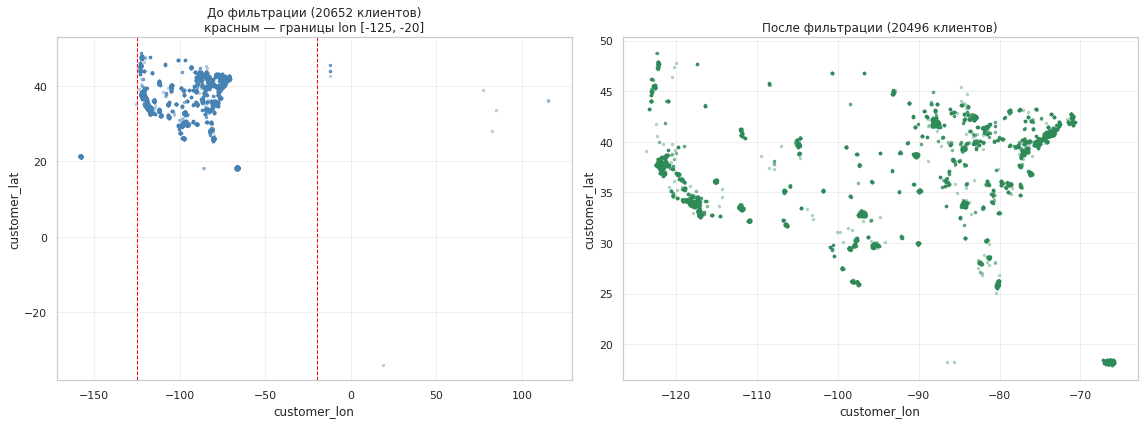

In [36]:
plot_geo_before_after(cust_old, data.customers.df)

In [37]:
del cust_old

✅ Удалены клиенты за пределами зоны обслуживания: 156 (0.76%) клиентов с их заказами 1430 (0.79%).

### Типы колонок

In [38]:
CUST_CONT_VARS = ('customer_lat', 'customer_lon', 'total_sales', 'avg_discount', 'return_rate',)
CUST_DISCRETE_VARS = ('total_orders', 'recency',)

ORDER_CAT_VARS = (
    'shipping_mode',       # 4 категории
    'category_name',       # 48 категорий 
)
ORDER_CONT_VARS = ('item_price', )

In [39]:
downcast_columns_for_ml(
    data.customers.df, 
    ints=CUST_DISCRETE_VARS + ('customer_id',),     
    floats=CUST_CONT_VARS
);

In [40]:
downcast_columns_for_ml(
    data.orders.df, 
    ints=('order_id', 'customer_id', TARGET),     
    cats=ORDER_CAT_VARS,
    floats=ORDER_CONT_VARS
);

In [41]:
data.customers.df.info(True, None, None, True)

<class 'pandas.core.frame.DataFrame'>
Index: 20496 entries, 0 to 20651
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   20496 non-null  int16  
 1   customer_lat  20496 non-null  float32
 2   customer_lon  20496 non-null  float32
 3   total_sales   20496 non-null  float32
 4   total_orders  20496 non-null  int8   
 5   avg_discount  20496 non-null  float32
 6   return_rate   20496 non-null  float32
 7   recency       20496 non-null  int16  
dtypes: float32(5), int16(2), int8(1)
memory usage: 660.5 KB


In [42]:
data.orders.df.info(True, None, None, True)

<class 'pandas.core.frame.DataFrame'>
Index: 179089 entries, 0 to 180518
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   order_id            179089 non-null  int32         
 1   customer_id         179089 non-null  int16         
 2   late_delivery_risk  179089 non-null  int8          
 3   shipping_mode       179089 non-null  category      
 4   category_name       179089 non-null  category      
 5   order_date          179089 non-null  datetime64[ns]
 6   item_price          179089 non-null  float32       
 7   order_month         179089 non-null  int32         
 8   order_weekday       179089 non-null  int32         
 9   order_hour          179089 non-null  int32         
dtypes: category(2), datetime64[ns](1), float32(1), int16(1), int32(4), int8(1)
memory usage: 7.0 MB


✅ Типы данных оптимизированы для ML. Потребление памяти: customers 1.3 MB → 660 KB, orders 42.6 MB → 7.0 MB (≈ 6 раз).

👉 Добавить в пайплайн.

### Фиксация BASELINE_RATE - баланса классов TARGET

In [43]:
n_total   = len(data.orders.df)
n_late  = int(data.orders.df[TARGET].sum())       # класс 1 — с нарушением SLA
n_success = n_total - n_late                      # класс 0 — без нарушения SLA

BASELINE_RATE = n_late / n_total                  
imbalance = n_success / n_late                    # соотношение 0:1

print(f'Всего заказов:       {n_total:>8,}')
print(f'Опоздания (класс 1): {n_late:>8,}  ({BASELINE_RATE:.4f} = {BASELINE_RATE:.2%})')
print(f'Успешные (класс 0):  {n_success:>8,}  ({1 - BASELINE_RATE:.2%})')
print(f'Дисбаланс 0:1:       {imbalance:>8.2f} : 1')

Всего заказов:        179,089
Опоздания (класс 1):   98,199  (0.5483 = 54.83%)
Успешные (класс 0):    80,890  (45.17%)
Дисбаланс 0:1:           0.82 : 1


### Промежуточный вывод
**Заказы (orders)**

Предоставлено **180 519 строк, 7 признаков**, order_id уникален, пропусков нет. Названия признаков в snake_case, данные соответствуют описанию.
Полных дубликатов нет. Обнаружено 20 806 строк (11.53%) с совпадающими признаками, кроме order_id. Поскольку order_date имеет точность до секунды (не timestamp), однозначно считать их дубликатами нельзя — это могут быть разные заказы одного клиента в одну секунду. Удаление отменено. Утечки они не создают: разбиение и кросс-валидация идут по customer_id, поэтому заказы одного клиента всегда попадают в одну выборку.
order_date приведён к datetime: данные покрывают период 2015-01-01 - 2018-01-31 (1126 дней), что согласуется с максимумом recency в профилях.

Категориальные признаки нормализованы (нижний регистр, пробелы). 

shipping_mode — 4 класса с заметным доминированием standard class (59.7%). 

category_name после нормализации содержал семантические дубликаты — слиты пары категорий women's clothing → women's apparel и consumer electronics → electronics (50 → 48 категорий). Категории сильно несбалансированы: топ-9 дают ~87% заказов, длинный «хвост» мелких категорий (<1%).

Добавлено разбиение order_date на месяц, день недели и час - признаки, пригодные для обучения модели и циклического кодирования.

**Профили клиентов (customers)**

Предоставлено **20 652 клиента, 8 признаков**, customer_id уникален, пропусков нет.
Полных дубликатов нет, 5 частичных (0.02%) — оставлены.
Множества customer_id в заказах и профилях полностью совпадают (20 652 общих).

**Географический аудит и аномалии**

В координатах обнаружены битые значения: customer_lon выходит за зону обслуживания (вплоть до +115°, Восточное полушарие), customer_lat — до -33.9° (Южное полушарие).
Отфильтрованы клиенты с customer_lon вне [-125, -20]: удалено 156 клиентов (0.76%) и связанных с ними 1 430 заказа (0.79%). 
После фильтра, аномалий по широте не осталось (lat вне [17, 50] = 0). Scatter подтверждает: остались два ожидаемых кластера — континентальные США и Пуэрто-Рико (~18°).


Итог: клиенты **20 652 → 20 496**, заказы **180 519 → 179 089**.


**Оптимизация типов**

Выполнена оптимизация типов данных: customers 1.3 MB → 660 KB, orders 42.6 MB → 7 MB (≈6× по заказам). Категориальные поля переведены в category, даты — в datetime64.


**Баланс целевого класса (TARGET = late_delivery_risk)**

Классы практически сбалансированы: опоздания 54.83% (класс 1) против 45.17% (класс 0), дисбаланс 0.82:1. Зафиксирован **BASELINE_RATE = 0.5483**.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Хорошо проведен подробный анализ shipping_mode, временных признаков и клиентских характеристи

##  Разделение на выборки

Разделите датафрейм с заказами на выборки. В этом проекте вам предстоит  использовать «классическое» разделение на три выборки: обучающую, валидационную и тестовую. Использовать для этого нужно не `train_test_split`, а `GroupShuffleSplit`. Он делит данные так, чтобы группы, то есть клиенты, не пересекались.

Ниже приведён пример того, как отделить часть данных для обучения, используя `customer_id` как ключ для группировки.

```python
from sklearn.model_selection import GroupShuffleSplit

# 1. Выбираем колонку, по которой будем группировать (наши "группы")
groups = df_orders['customer_id']

# 2. Инициализируем сплиттер (например, отделим 20% клиентов для теста)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)

# 3. Получаем индексы для разделения
# Метод split возвращает генератор, поэтому используем next()
train_idx, test_idx = next(gss.split(df_orders, groups=groups))

# 4. Формируем выборки
df_train = df_orders.iloc[train_idx]
df_test = df_orders.iloc[test_idx]

```


1. Разделите данные из датафрейма с заказами  на три выборки  в соотношении 60:20:20.


2. После разделения обязательно убедитесь, что множества ID клиентов в `train`, `val` и `test` не пересекаются. Если один и тот же клиент попал в разные выборки, то разделение выполнено неверно.

In [44]:
GROUP_COL = 'customer_id'                 # в модель не идёт

df = data.orders.df
groups = df[GROUP_COL]

gss1 = GroupShuffleSplit(n_splits=1, train_size=0.60, random_state=SEED)
train_idx, temp_idx = next(gss1.split(df, df[TARGET], groups))

df_train = df.iloc[train_idx]
df_temp  = df.iloc[temp_idx]

gss2 = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=SEED)
val_idx, test_idx = next(gss2.split(df_temp, df_temp[TARGET], groups=df_temp["customer_id"]))

df_val  = df_temp.iloc[val_idx]
df_test = df_temp.iloc[test_idx]

In [45]:
ids_train = set(df_train[GROUP_COL])
ids_val   = set(df_val[GROUP_COL])
ids_test  = set(df_test[GROUP_COL])

assert ids_train.isdisjoint(ids_val),  "Утечка клиентов train ↔ val!"
assert ids_train.isdisjoint(ids_test), "Утечка клиентов train ↔ test!"
assert ids_val.isdisjoint(ids_test),   "Утечка клиентов val ↔ test!"

n = len(df)
print("Разбиение по заказам:")
print(f"  train: {len(df_train):>7,} ({len(df_train)/n:.1%}) | клиентов: {len(ids_train):>6,}")
print(f"  val:   {len(df_val):>7,} ({len(df_val)/n:.1%}) | клиентов: {len(ids_val):>6,}")
print(f"  test:  {len(df_test):>7,} ({len(df_test)/n:.1%}) | клиентов: {len(ids_test):>6,}")

# баланс целевого класса в каждой выборке
print(f"\nДоля опозданий ({TARGET} = 1):")
for name, part in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"  {name:<5}: {part[TARGET].mean():.4f}")

Разбиение по заказам:
  train: 107,721 (60.1%) | клиентов: 12,297
  val:    35,355 (19.7%) | клиентов:  4,099
  test:   36,013 (20.1%) | клиентов:  4,100

Доля опозданий (late_delivery_risk = 1):
  train: 0.5478
  val  : 0.5502
  test : 0.5482


In [46]:
# --- клиенты по выборкам (split делали по customer_id) ---
customers = data.customers.df.set_index(GROUP_COL)
ids_train = df_train[GROUP_COL].unique()
ids_val   = df_val[GROUP_COL].unique()
ids_test  = df_test[GROUP_COL].unique()

cust_train = customers.loc[ids_train]
assert customers.index.is_unique
print(f'клиентов: train {len(ids_train):,} · val {len(ids_val):,} · test {len(ids_test):,}')

клиентов: train 12,297 · val 4,099 · test 4,100


## Финальный EDA

### Цели и методы

Нужно решить по каждому признаку orders:
- константа / квази-константа → удалить сразу;
- шум (IV < 0.02 и p-value χ² > 0.05) → в ablation;
- сильный одиночный сигнал и нет ли случайной утечки (AUC > 0.9);
- форма связи с TARGET — монотонная / U / ∩ / пила → допустимы ли monotone_constraints в CatBoost;
- взаимодействия пар → глубина деревьев (depth);
- дубли (phik > 0.9);
- как кодировать каждый признак для LogReg и для CatBoost;  

НЕ рассматриваем (обоснование — выбор моделей):
- выбросы, skew, масштаб для CatBoost: сплиты по порядковым статистикам инвариантны;
- импутацию: пропусков нет;
- OHE для CatBoost: категории нативны;
- VIF/мультиколлинеарность для деревьев: влияет только на дележ importance.
  Для LogReg — наоборот, масштаб/скошенность/OHE обязательны.

In [47]:
ORDER_CAT_VARS  = ['shipping_mode', 'category_name']     
ORDER_TIME_VARS = ['order_month', 'order_weekday', 'order_hour']  
ORDER_NUM_VARS  = ['item_price']

# кластерные метки появятся после. Анализируем их тем же профайлером:
# CLUSTER_VARS = ['geo_cluster', 'behavior_segment']

FEATURES = ORDER_CAT_VARS + ORDER_TIME_VARS + ORDER_NUM_VARS

# Все метрики считаем ТОЛЬКО на train, PSI — train↔val. Test не трогаем.
train = df_train.copy()
val   = df_val.copy()

BASE_LATE = train[TARGET].mean()   # базовая доля опозданий на train
print(f'base late rate (train): {BASE_LATE:.4f}')

base late rate (train): 0.5478


### Целевая переменная

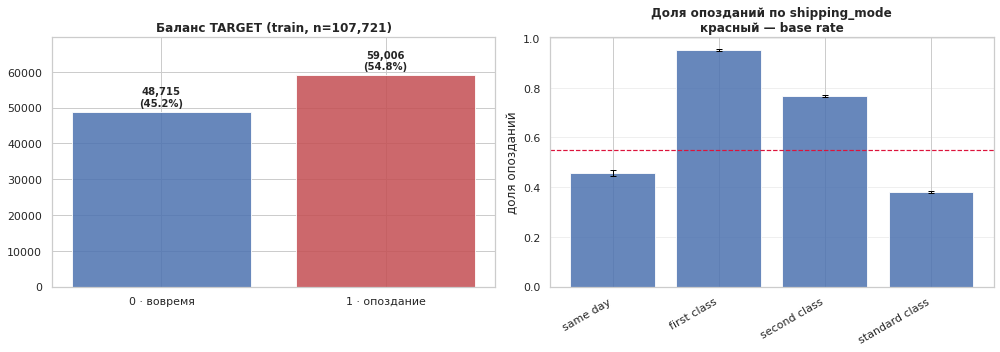

                    n    rate
shipping_mode                
same day         5851  0.4580
first class     16616  0.9517
second class    20795  0.7671
standard class  64459  0.3810


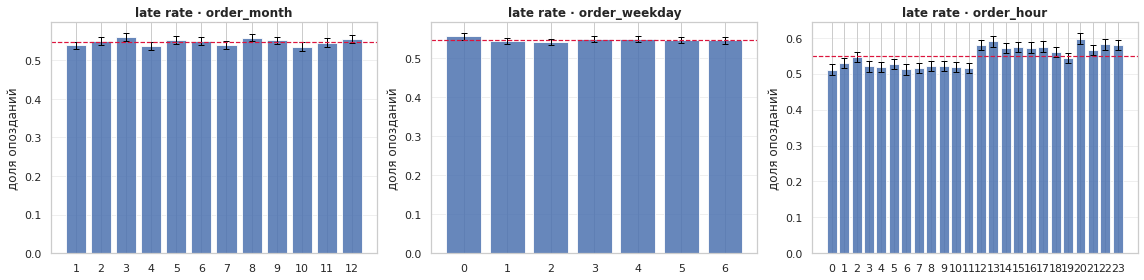

In [48]:
def plot_rate_by(ax, df, col, target=TARGET, order=None, rotate=0):
    """Доля опозданий по уровням признака + 95% Wilson CI + base line."""
    g = df.groupby(col, observed=True)[target].agg(n='size', rate='mean')
    if order is not None:
        g = g.reindex(order)
    lo, hi = proportion_confint((g.rate * g.n).round(), g.n, method='wilson')
    x = np.arange(len(g))
    ax.bar(x, g.rate, color='#4c72b0', alpha=.85)
    ax.errorbar(x, g.rate, yerr=[g.rate - lo, hi - g.rate],
                fmt='none', ecolor='black', capsize=3, lw=1)
    ax.axhline(BASE_LATE, ls='--', c='crimson', lw=1.2)
    ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=rotate, ha='right' if rotate else 'center')
    ax.set_ylabel('доля опозданий'); ax.grid(alpha=.3, axis='y')
    return g

# --- 1.1 баланс классов ---
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
vc = train[TARGET].value_counts().sort_index()
ax[0].bar(['0 · вовремя', '1 · опоздание'], vc.values,
          color=['#4c72b0', '#c44e52'], alpha=.85)
for i, v in enumerate(vc.values):
    ax[0].annotate(f'{v:,}\n({v/len(train):.1%})', (i, v),
                   textcoords='offset points', xytext=(0, 6),
                   ha='center', fontweight='bold')
ax[0].set_title(f'Баланс TARGET (train, n={len(train):,})', fontweight='bold')
ax[0].set_ylim(0, vc.max() * 1.18)

# --- 1.2 доля опозданий по режиму доставки — ключевая гипотеза SLA ---
order_sm = ['same day', 'first class', 'second class', 'standard class']
g_sm = plot_rate_by(ax[1], train, 'shipping_mode', order=order_sm, rotate=30)
ax[1].set_title('Доля опозданий по shipping_mode\nкрасный — base rate', fontweight='bold')
plt.tight_layout(); plt.show()
print(g_sm.assign(rate=g_sm.rate.round(4)))

# --- 1.3 доля опозданий по компонентам даты ---
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ORDER_TIME_VARS):
    plot_rate_by(a, train, col)
    a.set_title(f'late rate · {col}', fontweight='bold')
plt.tight_layout(); plt.show()

Ещё, посмотрим взвешенные доли опозданий по shipping_mode.

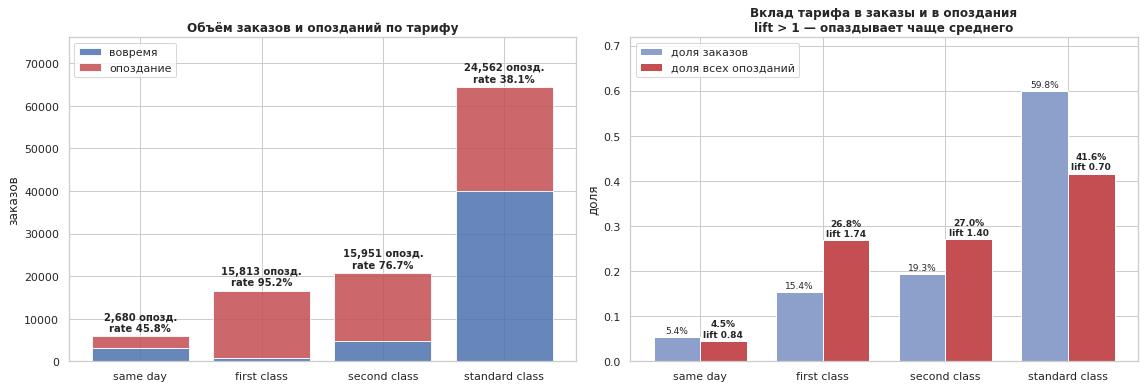

,n,late,on_time,rate,share_orders,share_late,lift
shipping_mode,,,,,,,
same day,5851,2680,3171,0.458,5.4%,4.5%,0.84
first class,16616,15813,803,0.952,15.4%,26.8%,1.74
second class,20795,15951,4844,0.767,19.3%,27.0%,1.40
standard class,64459,24562,39897,0.381,59.8%,41.6%,0.70


In [49]:
mode_order = ['same day', 'first class', 'second class', 'standard class']

sm = (train.groupby('shipping_mode', observed=True)[TARGET]
           .agg(n='size', late='sum')
           .reindex(mode_order))
sm['on_time']     = sm.n - sm.late
sm['rate']        = sm.late / sm.n
sm['share_orders'] = sm.n / sm.n.sum()
sm['share_late']   = sm.late / sm.late.sum()
sm['lift']         = sm.rate / BASE_LATE

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))

# --- 1. абсолютный объём: опоздания + вовремя (stacked) ---
x = np.arange(len(sm))
ax[0].bar(x, sm.on_time, color='#4c72b0', alpha=.85, label='вовремя')
ax[0].bar(x, sm.late, bottom=sm.on_time, color='#c44e52', alpha=.85, label='опоздание')
for i, r in enumerate(sm.itertuples()):
    ax[0].annotate(f'{r.late:,} опозд.\nrate {r.rate:.1%}', (i, r.n),
                   textcoords='offset points', xytext=(0, 5),
                   ha='center', fontsize=10, fontweight='bold')
ax[0].set_xticks(x); ax[0].set_xticklabels(sm.index)
ax[0].set_ylim(0, sm.n.max() * 1.18)
ax[0].set_ylabel('заказов'); ax[0].legend(loc='upper left')
ax[0].set_title('Объём заказов и опозданий по тарифу', fontweight='bold')

# --- 2. доля в заказах vs доля в опозданиях ---
w = .38
ax[1].bar(x - w/2, sm.share_orders, w, color='#8da0cb', label='доля заказов')
ax[1].bar(x + w/2, sm.share_late,   w, color='#c44e52', label='доля всех опозданий')
for i, r in enumerate(sm.itertuples()):
    ax[1].annotate(f'{r.share_orders:.1%}', (i - w/2, r.share_orders),
                   textcoords='offset points', xytext=(0, 4), ha='center', fontsize=9)
    ax[1].annotate(f'{r.share_late:.1%}\nlift {r.lift:.2f}', (i + w/2, r.share_late),
                   textcoords='offset points', xytext=(0, 4), ha='center',
                   fontsize=9, fontweight='bold')
ax[1].set_xticks(x); ax[1].set_xticklabels(sm.index)
ax[1].set_ylim(0, sm[['share_orders', 'share_late']].max().max() * 1.2)
ax[1].set_ylabel('доля'); ax[1].legend(loc='upper left')
ax[1].set_title('Вклад тарифа в заказы и в опоздания\nlift > 1 — опаздывает чаще среднего',
                fontweight='bold')

plt.tight_layout(); plt.show()

display(sm.style.format({'rate': '{:.3f}', 'share_orders': '{:.1%}',
                         'share_late': '{:.1%}', 'lift': '{:.2f}'}))

#### Промежуточный вывод

Классы почти сбалансированы: на train 54.8% опозданий и 45.2% доставок вовремя (base rate = 0.548),
так же, как во всём датасете (0.548). SMOTE и oversampling не нужны, веса классов ≈ 1, baseline ROC-AUC = 0.5.

Тариф нужно оценивать по двум показателям: доле опозданий внутри тарифа (rate)
и вкладу тарифа в общее число опозданий (share_late).

| тариф | заказов | опозданий | вовремя | rate | доля заказов | доля опозданий | lift |
|---|---|---|---|---|---|---|---|
| same day | 5 851 | 2 680 | 3 171 | 0.458 | 5.4% | 4.5% | 0.84 |
| first class | 16 616 | 15 813 | 803 | 0.952 | 15.4% | 26.8% | 1.74 |
| second class | 20 795 | 15 951 | 4 844 | 0.767 | 19.3% | 27.0% | 1.40 |
| standard class | 64 459 | 24 562 | 39 897 | 0.381 | 59.8% | 41.6% | 0.70 |

- **Больше всего опозданий по объёму даёт standard class:** 24.6 тыс., или 41.6% всех задержек,
  хотя его rate ниже среднего.
- **Чаще всего опаздывают first и second class** (rate 0.95 и 0.77): у них 35% заказов и 54% опозданий.
  У first class вовремя доставлено всего 803 заказа из 16 616: при таком нормативе SLA почти всегда нарушается.
- **same day** — небольшой сегмент, rate ниже среднего.

Что это значит для модели: по first class результат почти определён одним тарифом.
Основная задача модели — отделить опоздания от своевременных доставок внутри standard class
(38% против 62%). Тариф здесь не помогает, нужны признаки клиента: геозона и поведение
(будущие geo_cluster и behavior_segment).

По времени: order_month и order_weekday держатся около base rate (±1–2 п.п.), сезонности нет.
По order_hour есть ступенька в 12:00: до полудня ≈ 0.52, после ≈ 0.57–0.59.
Вероятная причина — отсечка отгрузки текущего дня.

### Сравниваем показатели признаков (профиль) на train, validation

In [50]:
def _as_groups(s: pd.Series, bins: int = 10) -> pd.Series:
    """
    Приводит признак к строковым группам для таблиц сопряжённости.
    Категориальные и малокардинальные — как есть, числовые — по квантилям.
    NaN становится отдельной группой '__NaN__'.
    """
    if s.dtype.name in ('category', 'object') or s.nunique(dropna=True) <= bins:
        g = s.astype('object')
    else:
        g = pd.qcut(s, bins, duplicates='drop').astype('object')
    return g.where(g.notna(), '__NaN__')

def compute_iv(s: pd.Series, y: pd.Series, bins: int = 10) -> float:
    """
    Information Value — разделяющая сила признака.
    <0.02 нет | 0.02-0.1 слабый | 0.1-0.3 средний | 0.3-0.5 сильный
    | >0.5 подозрение на утечку.
    """
    g = _as_groups(s, bins)
    t = (pd.DataFrame({'g': g, 'y': y})
           .groupby('g', observed=True)['y'].agg(['sum', 'count']))
    bad  = t['sum'].clip(lower=.5) / y.sum()
    good = (t['count'] - t['sum']).clip(lower=.5) / (len(y) - y.sum())
    return float(((bad - good) * np.log(bad / good)).sum())

def compute_psi(base: pd.Series, cur: pd.Series, bins: int = 10) -> float:
    """PSI. <0.1 стабилен | 0.1-0.25 умеренный дрейф | >0.25 нестабилен."""
    if base.dtype.name in ('category', 'object'):
        b = base.astype('object').value_counts(normalize=True)
        c = (cur.astype('object').value_counts(normalize=True)
                .reindex(b.index).fillna(0))
    else:
        e = np.unique(np.nanquantile(base.dropna(), np.linspace(0, 1, bins + 1)))
        if len(e) < 3:
            return 0.0
        b = pd.Series(np.histogram(base.dropna(), bins=e)[0]
                      / max(base.notna().sum(), 1))
        c = pd.Series(np.histogram(cur.dropna(), bins=e)[0]
                      / max(cur.notna().sum(), 1))
    b, c = b.clip(1e-6), c.clip(1e-6)
    return float(((c - b) * np.log(c / b)).sum())


def cramers_v(x: pd.Series, y: pd.Series) -> float:
    """Сила связи категориального признака с бинарным таргетом. 0 = нет связи."""
    t = pd.crosstab(_as_groups(x), y)
    if t.shape[0] < 2 or t.shape[1] < 2:
        return 0.0
    chi2 = chi2_contingency(t)[0]
    return float(np.sqrt(chi2 / (t.to_numpy().sum() * (min(t.shape) - 1))))

def chi2_pvalue(s: pd.Series, y: pd.Series, bins: int = 10) -> float:
    """Значимость связи — отделяет слабый сигнал от шума."""
    t = pd.crosstab(_as_groups(s, bins), y)
    if t.shape[0] < 2 or t.shape[1] < 2:
        return 1.0
    return float(chi2_contingency(t)[1])

def monotone_spearman(s: pd.Series, y: pd.Series, bins: int = 10) -> float:
    """Spearman между номером квантильного бина и CR внутри бина.
       |rho| > 0.9 → кандидат на monotone_constraint."""
    if s.nunique(dropna=True) <= 2:
        return np.nan
    try:
        g = pd.qcut(s, bins, duplicates='drop', labels=False)
    except Exception:
        return np.nan
    cr = pd.DataFrame({'g': g, 'y': y}).dropna().groupby('g')['y'].mean()
    if len(cr) < 3:
        return np.nan
    return float(cr.index.to_series().corr(cr, method='spearman'))

def single_auc(s: pd.Series, y: pd.Series) -> float:
    """ROC-AUC по одному признаку. >0.9 → сильное подозрение на утечку."""    

    if not pd.api.types.is_numeric_dtype(s):
        g = _as_groups(s)
        enc = pd.DataFrame({'g': g, 'y': y}).groupby('g', observed=True)['y'].mean()
        v = g.map(enc).astype('float64')
    else:
        v = s.astype('float64')

    m = v.notna()
    if m.sum() < 100 or y[m].nunique() < 2:
        return np.nan
    a = roc_auc_score(y[m], v[m])
    return float(max(a, 1 - a))

In [51]:
def profile_features(tr: pd.DataFrame, te: pd.DataFrame,
                     features: list, target: str = TARGET) -> pd.DataFrame:
    """Сводная диагностика признаков за один проход."""
    y = tr[target]
    rows = []

    for c in features:
        s = tr[c]
        is_num = pd.api.types.is_numeric_dtype(s)
        vc = s.value_counts(normalize=True, dropna=False)
        auc = single_auc(s, y)

        r = {
            'признак': c,
            'тип': 'num' if is_num else 'cat',
            'n_uniq': int(s.nunique(dropna=True)),
            'мода_%': round(vc.iloc[0] * 100, 1),
            'nan_%': round(s.isna().mean() * 100, 2),
            'IV': round(compute_iv(s, y), 4),
            'p_chi2': chi2_pvalue(s, y),
            'AUC': round(auc, 4) if pd.notna(auc) else np.nan,
            'PSI': round(compute_psi(s, te[c]), 3),
        }

        if is_num:
            q = s.quantile([.001, .5, .999])
            mono = monotone_spearman(s, y)
            cy = s.corr(y, method='spearman')
            r |= {
                'median': round(q.iloc[1], 2),
                'p001': round(q.iloc[0], 2),
                'p999': round(q.iloc[2], 2),
                'corr_y': round(cy, 4) if pd.notna(cy) else np.nan,
                'monotone': round(mono, 3) if pd.notna(mono) else np.nan,
            }
        else:
            r['cramers_v'] = round(cramers_v(s, y), 4)

        rows.append(r)

    out = pd.DataFrame(rows)
    out['сила'] = pd.cut(out.IV, [-1, .02, .1, .3, .5, 99],
                         labels=['нет', 'слабый', 'средний', 'сильный', '⚠утечка?'])
    out['значим'] = np.where(out.p_chi2 < .05, '✓', '')
    out['p_chi2'] = out.p_chi2.map(lambda v: f'{v:.1e}')
    return out.sort_values('IV', ascending=False).reset_index(drop=True)

In [52]:
# PSI считаем train↔val (стабильность бинов внутри одного распределения)
prof = profile_features(train, val, FEATURES)
display(prof.style.hide(axis='index'))

# автоматические вердикты
prof_num = prof.assign(p=prof.p_chi2.astype(float))
const = prof[(prof.n_uniq <= 1) | (prof['мода_%'] > 99)]['признак'].tolist()
noise = prof_num[(prof_num.IV < .02) & (prof_num.p > .05)]['признак'].tolist()
leak  = prof[(prof.IV > .5) | (prof.AUC.fillna(0) > .9)]['признак'].tolist()
drift = prof[prof.PSI > .25]['признак'].tolist()
mono  = prof[prof['monotone'].abs() > .9].set_index('признак')['monotone'].dropna().to_dict()

for nm, lst in [('КОНСТАНТЫ', const), ('ШУМ (ablation)', noise),
                ('⚠ AUC>0.9 / IV>0.5', leak), ('ДРЕЙФ PSI>0.25', drift)]:
    print(f'{nm}: {lst}')
print(f'МОНОТОННЫЕ |rho|>0.9: {mono}')

признак,тип,n_uniq,мода_%,nan_%,IV,p_chi2,AUC,PSI,cramers_v,median,p001,p999,corr_y,monotone,сила,значим
shipping_mode,cat,4,59.800000,0.000000,1.151900,0.0e+00,0.727300,0.000000,0.456000,nan,nan,nan,nan,nan,⚠утечка?,✓
order_hour,num,24,4.300000,0.000000,0.012200,8.5e-65,0.525500,0.001000,nan,11.000000,0.000000,23.000000,0.044000,0.685000,нет,✓
category_name,cat,48,13.700000,0.000000,0.001500,7.6e-01,0.507800,0.002000,0.019200,nan,nan,nan,nan,nan,нет,
order_month,num,12,9.800000,0.000000,0.000800,1.2e-02,0.500700,0.001000,nan,6.000000,1.000000,12.000000,0.001300,0.079000,нет,✓
order_weekday,num,7,14.500000,0.000000,0.000300,2.4e-01,0.501700,0.000000,nan,3.000000,0.000000,6.000000,-0.003000,-0.371000,нет,
item_price,num,75,13.800000,0.000000,0.000200,6.1e-01,0.500200,0.001000,nan,59.990000,9.990000,1500.000000,-0.000300,0.214000,нет,


КОНСТАНТЫ: []
ШУМ (ablation): ['category_name', 'order_weekday', 'item_price']
⚠ AUC>0.9 / IV>0.5: ['shipping_mode']
ДРЕЙФ PSI>0.25: []
МОНОТОННЫЕ |rho|>0.9: {}


#### Промежуточный вывод

- **Констант нет** (максимальная доля моды — 59.8%). **Дрейфа нет**: PSI ≤ 0.002, групповое разбиение дало однородные выборки.
- **Утечки нет.** shipping_mode попал под фильтр (IV = 1.152), но AUC = 0.727 < 0.9, а тариф известен
  при оформлении заказа. Высокий IV дают крайние тарифы (first class 0.95 и standard class 0.38).
  Внутри standard class, а это 60% заказов, признак ничего не разделяет. Отсюда потолок AUC ≈ 0.73 по одному тарифу.
- **Слабый, но значимый сигнал:** order_hour (IV = 0.0122, p = 8.5e-65), оставляем.
- **Шум → DROP_SOFT (решение по ablation):** category_name, order_weekday, item_price (IV < 0.02, p > 0.05);
  order_month (p = 1.2e-02, но IV = 0.0008, размах 2.2 п.п.). У category_name значимо отличается
  1 уровень из 48 при ≈ 2.4 случайно ожидаемых.
- **Монотонных признаков нет.**

### Коллинеарность, дублирующиеся признаки и взаимодействия на train

In [53]:
DUP_PHIK    = 0.90    # дубль → удалить один из пары
STRONG_PHIK = 0.70    # сильная связь → следить за importance

In [54]:
# ----------------------------- взаимодействия -----------------------------
def cv_auc(df: pd.DataFrame, cols: list, target: str = TARGET) -> tuple:
    """CV ROC-AUC контрольного LGBM на заданном наборе признаков."""
    X = df[list(cols)].copy()
    for c in X.select_dtypes(['object', 'category']):
        X[c] = X[c].astype('category')
    s = cross_val_score(LGBMClassifier(n_estimators=150, verbose=-1, random_state=SEED),
                        X, df[target], cv=3, scoring='roc_auc')
    return s.mean(), s.std()


solo = {c: cv_auc(train, [c])[0] for c in FEATURES}

inter_rows = {}
for a, b in combinations(FEATURES, 2):
    auc_pair, sd = cv_auc(train, [a, b])
    best = max(solo[a], solo[b])
    inter_rows[(a, b)] = dict(auc_pair=auc_pair, best_solo=best,
                              прирост=auc_pair - best, std=sd)

inter = pd.DataFrame.from_dict(inter_rows, orient='index')
inter['значим'] = np.where(inter['прирост'] > inter['std'], '✓', '')

In [55]:
# ----------------------------- phik -----------------------------
num_feats     = [c for c in FEATURES if pd.api.types.is_numeric_dtype(train[c])]
interval_cols = [c for c in num_feats if train[c].nunique() > 20]

pm = train[FEATURES].phik_matrix(interval_cols=interval_cols)

# пары в том же порядке, что и combinations(FEATURES, 2) → ключи совпадут с inter
pairs = pd.DataFrame(
    {'phik': [pm.loc[a, b] for a, b in combinations(FEATURES, 2)]},
    index=pd.MultiIndex.from_tuples(list(combinations(FEATURES, 2)),
                                    names=['признак_1', 'признак_2']),
)

pairs['вывод'] = np.select(
    [pairs.phik > DUP_PHIK, pairs.phik > STRONG_PHIK],
    ['ДУБЛЬ → drop одного', 'сильная связь → следить за importance'],
    default='норма',
)

_iv = prof.set_index('признак')['IV']
p1 = pairs.index.get_level_values(0)
p2 = pairs.index.get_level_values(1)
pairs['IV_1'] = p1.map(_iv).to_numpy()
pairs['IV_2'] = p2.map(_iv).to_numpy()
pairs['оставить'] = np.where(pairs.phik > DUP_PHIK,
                             np.where(pairs.IV_1 >= pairs.IV_2, p1, p2), '—')

# объединяем phik и взаимодействия в одну таблицу
inter.index = pairs.index
pairs = pairs.join(inter).sort_values(['phik', 'прирост'], ascending=False)


# ----------------------------- вывод -----------------------------
print(f'пар всего: {len(pairs)}   '
      f'дублей: {(pairs.phik > DUP_PHIK).sum()}   '
      f'сильных: {((pairs.phik > STRONG_PHIK) & (pairs.phik <= DUP_PHIK)).sum()}   '
      f'значимых взаимодействий: {(pairs["значим"] == "✓").sum()}')

display(
    pairs.style
         .background_gradient(subset=['phik'], cmap='coolwarm', vmin=0, vmax=1)
         .background_gradient(subset=['IV_1', 'IV_2'], cmap='Greens', vmin=0, vmax=.5)
         .background_gradient(subset=['прирост'], cmap='RdYlGn', vmin=-.04, vmax=.04)
         .format({'phik': '{:.3f}', 'IV_1': '{:.4f}', 'IV_2': '{:.4f}',
                  'auc_pair': '{:.4f}', 'best_solo': '{:.4f}',
                  'прирост': '{:+.4f}', 'std': '{:.4f}'})
)

dups = pairs[pairs.phik > DUP_PHIK]
DROP_CORR = sorted({b if keep == a else a for (a, b), keep in dups['оставить'].items()})
print(f'\nкандидаты на удаление по phik-дублям: {DROP_CORR or "нет"}')

n_sig = int((pairs['значим'] == '✓').sum())
print(f'значимых взаимодействий: {n_sig} → depth для CatBoost: {"6" if n_sig >= 3 else "4"} '
      f'(тюнинг {"6–8" if n_sig >= 3 else "4–6"})')

пар всего: 15   дублей: 1   сильных: 0   значимых взаимодействий: 1



кандидаты на удаление по phik-дублям: ['item_price']
значимых взаимодействий: 1 → depth для CatBoost: 4 (тюнинг 4–6)


#### Промежуточный вывод

- **Дубль:** category_name ↔ item_price (phik = 0.973), цену задаёт прайс-лист. item_price удаляем.
  Сильных связей (0.7–0.9) нет.
- **Взаимодействие:** значимое одно — shipping_mode × order_hour: +0.034 CV-AUC (0.728 → 0.762)
  при std 0.023. Запас над std небольшой, нужно подтвердить на validation.
- У пар из шумовых признаков CV-AUC < 0.5 (единственное исключение — order_month × order_weekday, 0.5004). Это переобучение на шуме и ещё одно подтверждение, что сигнала в них нет.
- **CatBoost:** depth = 4 (тюнинг 4–6). **LogReg:** взаимодействие задаём явным признаком.

### Проверяем форму зависимости TARGET от признаков

In [56]:
def shape_label(rate: pd.Series) -> str:
    """Классифицирует форму связи по знакам приращений."""
    if len(rate) < 3:
        return 'мало точек'
    d = np.sign(np.diff(rate.values))
    d = d[d != 0]
    if len(d) == 0:
        return 'плоская'
    flips = int((np.diff(d) != 0).sum())
    rho = spearmanr(range(len(rate)), rate.values).correlation
    if flips == 0:
        return f'монотонная ({"↑" if rho > 0 else "↓"})'
    if flips == 1:
        return 'U-образная' if rate.values[0] > rate.values.mean() else '∩-образная'
    return f'пилообразная ({flips} перегибов)'


def plot_target_rate(df: pd.DataFrame, features: list,
                     bins: int = 10, ncols: int = 4,
                     min_bin: int = 50) -> pd.DataFrame:
    """
    Доля отмен по децилям каждого признака.

    Монотонный тренд     -> кандидат на monotone_constraint
    U- или ∩-образный    -> дерево обязательно, LogReg потребует биннинга
    Пилообразный         -> вероятен шум, проверить размер бинов
    """
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(14, 2.9 * nrows))
    axes = np.atleast_1d(axes).ravel()
    base = df[TARGET].mean()
    _iv = prof.set_index('признак')['IV']
    out = []

    for ax, col in zip(axes, features):
        s = df[col]
        if s.dtype.name in ('category', 'object') or s.nunique() <= bins:
            grp = s.astype('object')
        else:
            grp = pd.qcut(s, bins, duplicates='drop')

        g = df.groupby(grp, observed=True)[TARGET]
        rate, n = g.mean(), g.size()
        se = np.sqrt(rate * (1 - rate) / n.clip(lower=1))
        x = np.arange(len(rate))

        ax.fill_between(x, rate - 1.96 * se, rate + 1.96 * se,
                        alpha=.18, color='tab:blue')
        ax.plot(x, rate.values, marker='o', ms=4, color='tab:blue')
        ax.axhline(base, color='gray', ls='--', lw=1)

        thin = n < min_bin
        if thin.any():
            ax.plot(x[thin], rate.values[thin], 'x', color='tab:red', ms=8)

        lab = shape_label(rate)
        ax.set_title(f'{col}\nIV={_iv.get(col, np.nan):.3f} · {lab}', fontsize=9)
        
        # ax.set_xticks([])
        if isinstance(rate.index, pd.CategoricalIndex) and hasattr(rate.index.categories, 'right'):
            labels = [f'{iv.right:.0f}' for iv in rate.index]     # правая граница интервала
        else:
            labels = [str(v)[:8] for v in rate.index]             # значение / уровень

        ax.set_xticks(x)
        ax.set_xticklabels(labels, fontsize=10, rotation=45, ha='right')
        
        ax.grid(alpha=.3)

        out.append(dict(
            признак=col, форма=lab, IV=round(_iv.get(col, np.nan), 4),
            размах_пп=round((rate.max() - rate.min()) * 100, 2),
            rho=round(spearmanr(x, rate.values).correlation, 3),
            мелких_бинов=int(thin.sum()),
        ))

    for ax in axes[len(features):]:
        ax.set_visible(False)

    fig.suptitle(f'Доля опозданий по квантилям  ·  пунктир — base rate {base:.3f}  ·  '
                 f'× — бин < {min_bin} набл.', y=1.0, fontsize=11)
    plt.tight_layout()
    plt.show()

    return (pd.DataFrame(out).sort_values('IV', ascending=False)
            .reset_index(drop=True))

In [57]:
def plot_target_rate_wide(df: pd.DataFrame, col: str,
                          target: str = TARGET, min_bin: int = 50,
                          sort_by_rate: bool = True) -> pd.DataFrame:
    """
    Доля TARGET по уровням высококардинального категориального признака.
    График на всю ширину, 95% Wilson CI, мелкие уровни отмечены красным.
    """
    g = df.groupby(col, observed=True)[target].agg(n='size', rate='mean')
    if sort_by_rate:
        g = g.sort_values('rate', ascending=False)
    lo, hi = proportion_confint((g.rate * g.n).round(), g.n,
                                alpha=.05, method='wilson')
    base = df[target].mean()
    thin = (g.n < min_bin).to_numpy()
    x = np.arange(len(g))

    fig, ax = plt.subplots(figsize=(20, 6))
    ax.bar(x, g.rate, color=np.where(thin, '#c44e52', '#4c72b0'), alpha=.85)
    ax.errorbar(x, g.rate, yerr=[g.rate - lo, hi - g.rate],
                fmt='none', ecolor='black', capsize=2, lw=.8)
    ax.axhline(base, ls='--', c='gray', lw=1.2)
    ax.text(len(g) - .5, base + .01, f'base rate {base:.3f}',
            ha='right', color='gray', fontsize=10)

    ax.set_xticks(x)
    ax.set_xticklabels(g.index, rotation=60, ha='right', fontsize=12)
    ax.set_xlim(-.7, len(g) - .3)
    ax.set_ylabel('доля опозданий')
    ax.grid(alpha=.3, axis='y')

    _iv = prof.set_index('признак')['IV']
    ax.set_title(f'Доля опозданий по {col}  ·  IV={_iv.get(col, np.nan):.4f}  ·  '
                 f'{len(g)} уровней\nкрасный — уровень < {min_bin} набл. '
                 f'(широкий CI, ненадёжно)', fontsize=12, fontweight='bold', pad=12)
    plt.tight_layout(); plt.show()

    # Сколько уровней статистически отличается от base rate (CI не накрывает base)
    n_diff = int(((lo > base) | (hi < base)).sum())
    print(f'уровней, значимо отличающихся от base rate: {n_diff} из {len(g)}')
    return g.assign(lo=lo, hi=hi)


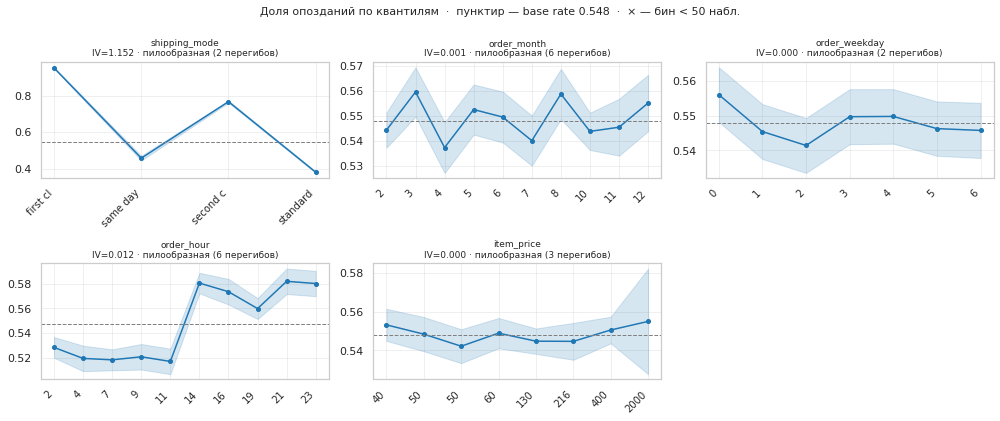

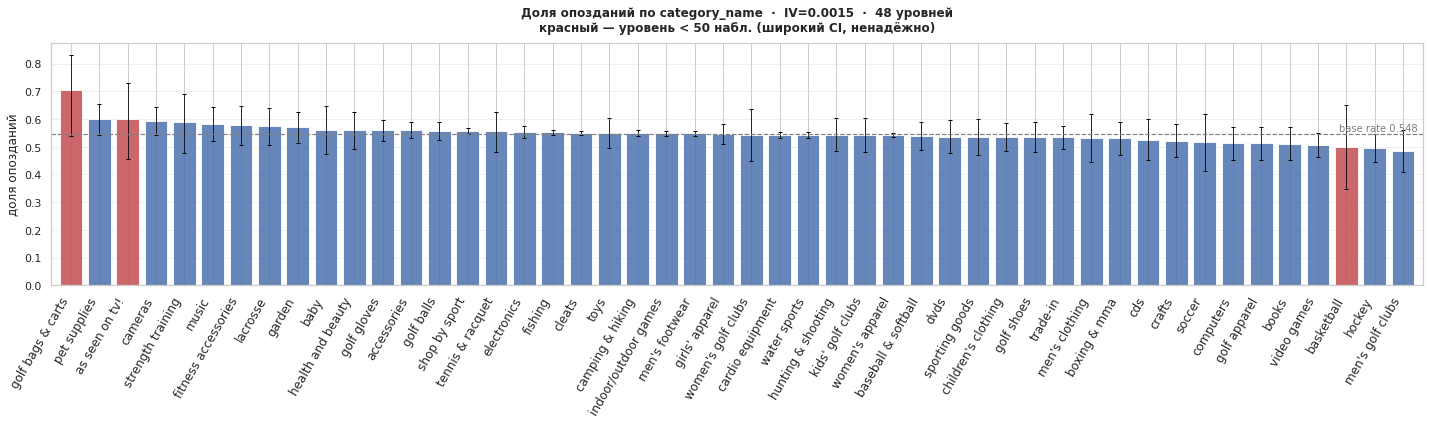

уровней, значимо отличающихся от base rate: 1 из 48


признак,форма,IV,размах_пп,rho,мелких_бинов
shipping_mode,пилообразная (2 перегибов),1.1519,57.06,-0.800,0
order_hour,пилообразная (6 перегибов),0.0122,6.47,+0.685,0
order_month,пилообразная (6 перегибов),0.0008,2.23,+0.079,0
order_weekday,пилообразная (2 перегибов),0.0003,1.46,-0.107,0
item_price,пилообразная (3 перегибов),0.0002,1.28,+0.214,0


In [58]:
WIDE_FEATURES = ['category_name']                       # признаки с длинной осью X
GRID_FEATURES = [c for c in FEATURES if c not in WIDE_FEATURES]

shapes = plot_target_rate(train, GRID_FEATURES, bins=10, ncols=3)

for col in WIDE_FEATURES:
    cat_rate = plot_target_rate_wide(train, col)

display(shapes.style.background_gradient(subset=['IV'], cmap='Greens')
        .format({'IV': '{:.4f}', 'размах_пп': '{:.2f}', 'rho': '{:+.3f}'})
        .hide(axis='index'))

#### Промежуточный вывод

- shipping_mode — номинальная категория, риск не упорядочен по «скорости» тарифа. Порядковое кодирование не подходит.
  Разделяющая сила неравномерна: высокая на 35% заказов (first/second) и почти нулевая на 60% (standard).
- order_hour — ступенька с двумя плато (0–11 ч и 12–23 ч), а не волна. sin/cos не нужен,
  достаточно флага **is_pm = order_hour ≥ 12**.
- order_month, order_weekday, item_price — колебания внутри CI, это шум.
- monotone_constraints не применяем.

### Оценка теоретически-достижимых метрик

Лучшая пара shipping_mode × order_hour даёт CV-AUC ≈ 0.762, остальные признаки — шум. Признаки заказа выводят модель за порог 0.75 с запасом всего около 0.012, а это меньше std CV (0.023). Требование ROC-AUC > 0.75 на признаках заказа выполняется ненадёжно.

In [59]:
pairs_total = sm.late.sum() * sm.on_time.sum()
w_mode = sm.late * sm.on_time / pairs_total          # доля внутритарифных пар
AUC_TARIFF = single_auc(train['shipping_mode'], train[TARGET])

scen = pd.DataFrame({'AUC_внутри': [.50, .55, .60, .65, .70, .75, .80]})
scen['AUC_все_тарифы']    = AUC_TARIFF + w_mode.sum() * (scen['AUC_внутри'] - .5)
scen['AUC_только_standard'] = AUC_TARIFF + w_mode['standard class'] * (scen['AUC_внутри'] - .5)
display(scen.round(4).style.hide(axis='index')
        .background_gradient(subset=['AUC_все_тарифы', 'AUC_только_standard'], cmap='Greens'))

AUC_внутри,AUC_все_тарифы,AUC_только_standard
0.500000,0.727300,0.727300
0.550000,0.746100,0.744400
0.600000,0.764900,0.761400
0.650000,0.783600,0.778500
0.700000,0.802400,0.795500
0.750000,0.821100,0.812600
0.800000,0.839900,0.829600


#### Промежуточный вывод

ROC-AUC раскладывается на пары «опоздание – вовремя».
Тариф упорядочивает 62.4% пар и даёт AUC = 0.727. Остальные 37.6% пар лежат внутри
одного тарифа (34.2% — внутри standard class), и для них сейчас AUC = 0.5.
Общий AUC ≈ 0.727 + 0.376 · (AUC_внутри − 0.5): каждые +0.05 разделения внутри
тарифов дают ≈ +0.019 к общему ROC-AUC.

| уровень | ROC-AUC | Recall @0.7 | Precision @0.7 |
|---|---|---|---|
| константа | 0.500 | — | — |
| правило по тарифу | 0.727 | 0.538 | 0.850 |
| признаки заказа (тариф × час) | ≈ 0.762 (CV) | ≈ 0.54–0.56 | ≈ 0.85 |
| цель с признаками клиента | 0.78–0.80 | 0.60–0.65 | ≥ 0.80 |
| требование | > 0.75 | — | порог 0.7 |

- Для ROC-AUC > 0.75 достаточно AUC ≈ 0.57 внутри standard class. Признаки заказа
  дают 0.762 и формально проходят порог, но запас (0.012) меньше std CV (0.023).
- Для устойчивых 0.78–0.80 нужен AUC ≈ 0.64–0.69 внутри тарифов. Такой сигнал
  должны дать геокластеры и поведенческие сегменты: они различают клиентов внутри
  standard class, где сосредоточено 41.6% всех задержек.

### Кодирование признаков для пайплайнов

| Признак | Статус после EDA | Logistic Regression | CatBoost |
|---|---|---|---|
| `shipping_mode` (4) | CORE, IV 1.152 | Отдельно не подаём: входит в `mode_pm`. Номинальная категория, порядковый код не подходит. | `cat_features`, без изменений |
| `order_hour` (24) | CORE, ступенька в 12:00 | Флаг `is_pm = hour >= 12`; отдельно не подаём, входит в `mode_pm`. `sin/cos` не нужен. | Числовой, без изменений: ступеньку дерево возьмёт одним сплитом |
| `mode_pm` = `shipping_mode × is_pm` | CORE, взаимодействие +0.034 | OHE, 8 уровней, без `drop`. Насыщенная модель: заменяет `shipping_mode` и `is_pm`. | Не нужен: взаимодействие учтётся при `depth=4` |
| `order_month` (12) | DROP_SOFT, шум | Для ablation: `sin/cos(2π·(m−1)/12)`. | Для ablation: числовой |
| `order_weekday` (7) | DROP_SOFT, шум | Для ablation: OHE. | Для ablation: числовой |
| `category_name` (48) | DROP_SOFT, шум | Для ablation: OHE, категории реже 1% → одна `infrequent`. | Для ablation: `cat_features` (встроенные target statistics без утечки) |
| `item_price` | DROP_CORR, дубль `category_name` | Удалить. | Удалить. |
| `geo_cluster` (k = 12) | Добавлен после кластеризации | OHE. | `cat_features` |
| `behavior_segment` (k = 6) | Добавлен после кластеризации | OHE. | `cat_features` |
| `order_id` | DROP_TECH, ключ | Удалить. | Удалить. |
| `customer_id` | DROP_TECH, ключ | В модель не идёт: используется для `GroupKFold` и подстановки кластеров. | То же. |
| `order_date` | Вход пайплайна | `OrderCleaner` → месяц, день недели, час; сама дата в модель не идёт. | То же. |

**Общие настройки**

| Модель | Настройки |
|---|---|
| Logistic Regression | `penalty='l2'`, `C=1.0`, `solver='lbfgs'`, `max_iter=1000`, `class_weight=None`. OHE без `drop`: дамми-ловушку снимает L2. Признаки 0/1 (в ablation `month_sin/cos` ∈ [-1, 1]), поэтому `StandardScaler` не нужен. |
| CatBoost | `depth=4`, `iterations=500`, `learning_rate=0.05`, `eval_metric='AUC'`, без весов классов и без early stopping (в ablation `iterations=200`). |

## Финальный EDA для customers

,n_uniq,zero_pct,skew_raw,skew_log,skew_sqrt,p01,median,p99,max,tail,рекомендация
признак,,,,,,,,,,,
recency,940,0.0%,+1.49,-0.86,+0.49,4,159,906,1.12e+03,1.24,sqrt
total_orders,15,0.0%,+0.92,+0.30,+0.47,1,3,10,15,1.50,как есть
total_sales,7604,0.0%,+0.92,-0.90,+0.15,9.58,1.29e+03,5.82e+03,9.44e+03,1.62,как есть
return_rate,149,87.1%,+4.82,+4.26,+3.13,0,0,1,1,1.00,нулевая масса → флаг has_* + доля
avg_discount,1869,2.2%,+0.47,+0.29,-1.01,0,0.1,0.25,0.25,1.00,как есть


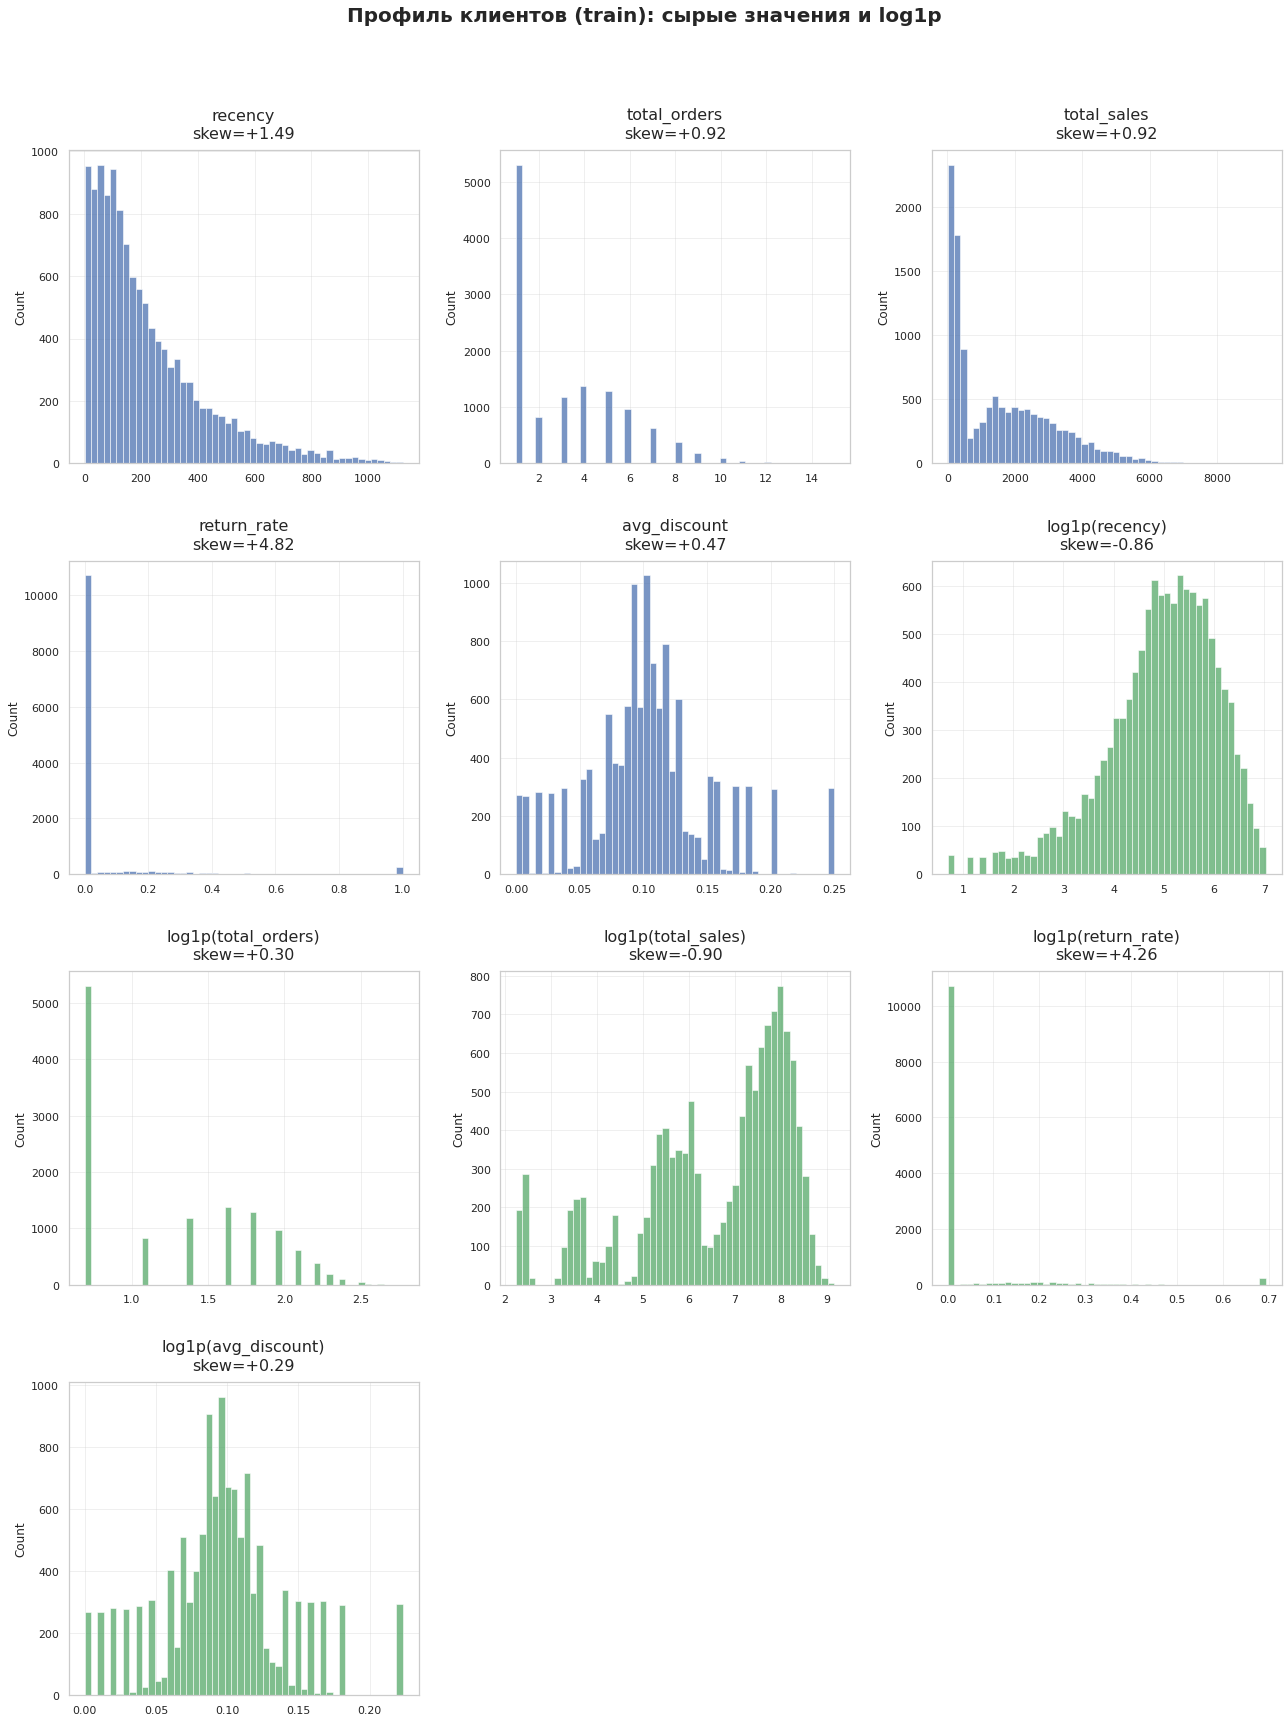

In [60]:
RFM_COLS = ['recency', 'total_orders', 'total_sales', 'return_rate', 'avg_discount']
SKEW_LIM = 1.0          # |skew| > 1 → сильный перекос
ZERO_LIM = 0.5          # доля нулей > 50% → нулевая масса
TAIL_LIM = 3.0          # max / p99 > 3 → экстремальный хвост


def profile_customer_features(df: pd.DataFrame, cols: list) -> pd.DataFrame:
    """Перекос сырых и преобразованных значений, нули, хвосты → рекомендация."""
    rows = []
    for c in cols:
        s = df[c].astype('float64')
        p01, p99 = s.quantile([.01, .99])
        r = dict(
            признак=c, n_uniq=s.nunique(),
            zero_pct=(s == 0).mean() * 100,
            skew_raw=skew(s), skew_log=skew(np.log1p(s)), skew_sqrt=skew(np.sqrt(s)),
            p01=p01, median=s.median(), p99=p99, max=s.max(),
            tail=s.max() / p99 if p99 else np.nan,
        )
        if r['zero_pct'] > ZERO_LIM * 100:
            r['рекомендация'] = 'нулевая масса → флаг has_* + доля'
        elif abs(r['skew_raw']) <= SKEW_LIM:
            r['рекомендация'] = 'как есть'
        elif abs(r['skew_log']) <= abs(r['skew_sqrt']):
            r['рекомендация'] = 'log1p'
        else:
            r['рекомендация'] = 'sqrt'
        if r['tail'] > TAIL_LIM:
            r['рекомендация'] += ' + clip p99'
        rows.append(r)
    return pd.DataFrame(rows).set_index('признак')


cust_prof = profile_customer_features(cust_train, RFM_COLS)
display(cust_prof.style
        .format({'zero_pct': '{:.1f}%', 'skew_raw': '{:+.2f}', 'skew_log': '{:+.2f}',
                 'skew_sqrt': '{:+.2f}', 'p01': '{:.3g}', 'median': '{:.3g}',
                 'p99': '{:.3g}', 'max': '{:.3g}', 'tail': '{:.2f}'})
        .background_gradient(subset=['skew_raw', 'skew_log', 'skew_sqrt'],
                             cmap='RdBu_r', vmin=-3, vmax=3))


ncols = 3
n_features = len(RFM_COLS)
n_plots = 2 * n_features
nrows = math.ceil(n_plots / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(18, 6 * nrows),
    squeeze=False
)

axes = axes.ravel()

# Сырые распределения
for i, c in enumerate(RFM_COLS):
    s = cust_train[c]

    sns.histplot(
        s,
        bins=50,
        ax=axes[i],
        color="#4c72b0"
    )

    axes[i].set_title(
        f"{c}\nskew={skew(s):+.2f}",
        fontsize=16,
        pad=12
    )

# Распределения после log1p
for i, c in enumerate(RFM_COLS):
    s_log = np.log1p(cust_train[c])
    pos = n_features + i

    sns.histplot(
        s_log,
        bins=50,
        ax=axes[pos],
        color="#55a868"
    )

    axes[pos].set_title(
        f"log1p({c})\nskew={skew(s_log):+.2f}",
        fontsize=16,
        pad=12
    )

# Скрываем пустые оси
for ax in axes[n_plots:]:
    ax.set_visible(False)

for ax in axes:
    ax.set_xlabel("")
    ax.grid(alpha=0.3)

fig.suptitle(
    "Профиль клиентов (train): сырые значения и log1p",
    fontsize=20,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96],
    h_pad=3.5,
    w_pad=2.0
)

plt.show()

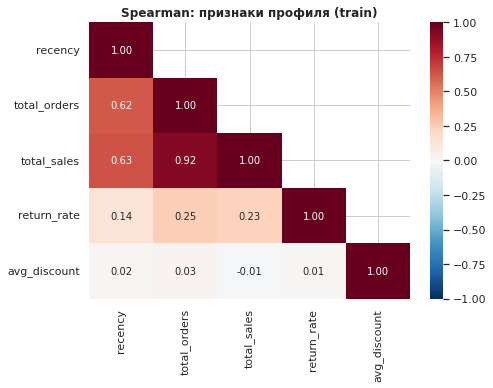

In [61]:
corr = cust_train[RFM_COLS].corr(method='spearman')

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, bool), 1), ax=ax)
ax.set_title('Spearman: признаки профиля (train)', fontweight='bold')
plt.tight_layout(); plt.show()

In [62]:
# средний чек: total_sales дублирует total_orders, поэтому заменяем
cust_train_avg_check = cust_train.total_sales / cust_train.total_orders
print(f'Spearman(total_orders, total_sales)  = {corr.loc["total_orders", "total_sales"]:.3f}')
print(f'Spearman(total_orders, avg_check)    = '
      f'{cust_train.total_orders.corr(cust_train_avg_check, method="spearman"):.3f}')

Spearman(total_orders, total_sales)  = 0.919
Spearman(total_orders, avg_check)    = 0.569


,IV,p_chi2,AUC,IV_standard,AUC_standard,monotone
признак,,,,,,
recency,0.0002,6.9e-01,0.5015,0.0010,0.5002,-0.406
total_orders,0.0010,5.7e-04,0.5022,0.0012,0.5042,+0.405
total_sales,0.0016,1.5e-06,0.5014,0.0037,0.5025,+0.079
return_rate,0.0480,2.6e-278,0.5419,0.0349,0.5339,-1.000
avg_discount,0.0003,4.4e-01,0.5001,0.0008,0.5021,+0.030


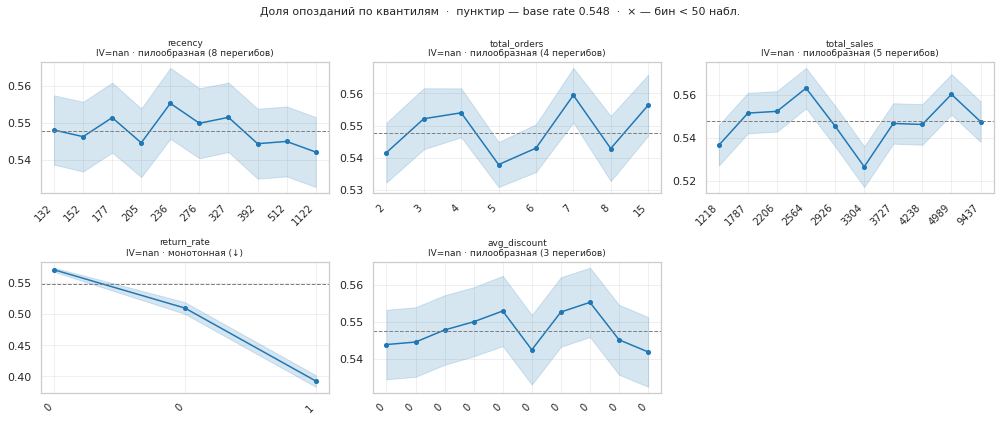

In [63]:
orders_cust = df_train[[GROUP_COL, 'shipping_mode', TARGET]].join(cust_train[RFM_COLS], on=GROUP_COL)

rows = []
for c in RFM_COLS:
    s = orders_cust[c]
    # общий сигнал + сигнал внутри standard class — там 41.6% опозданий
    std_mask = orders_cust.shipping_mode == 'standard class'
    rows.append(dict(
        признак=c,
        IV=compute_iv(s, orders_cust[TARGET]),
        p_chi2=chi2_pvalue(s, orders_cust[TARGET]),
        AUC=single_auc(s, orders_cust[TARGET]),
        IV_standard=compute_iv(s[std_mask], orders_cust.loc[std_mask, TARGET]),
        AUC_standard=single_auc(s[std_mask], orders_cust.loc[std_mask, TARGET]),
        monotone=monotone_spearman(s, orders_cust[TARGET]),
    ))
display(pd.DataFrame(rows).set_index('признак').style
        .format({'IV': '{:.4f}', 'p_chi2': '{:.1e}', 'AUC': '{:.4f}',
                 'IV_standard': '{:.4f}', 'AUC_standard': '{:.4f}', 'monotone': '{:+.3f}'})
        .background_gradient(subset=['IV', 'IV_standard'], cmap='Greens', vmin=0, vmax=.1))

# форма связи — тем же инструментом, что в финальном EDA заказов
_ = plot_target_rate(orders_cust, RFM_COLS, bins=10, ncols=3)

#### Кодирование признаков customers для KMeans

| Исходный признак | Что показал EDA (train) | Преобразование | Признак для KMeans | Обоснование |
|---|---|---|---|---|
| `recency` | `skew = +1.49`; `log1p` даёт `−0.86`, `sqrt` — `+0.49` | `sqrt` | `recency_sqrt` | `sqrt` ближе к симметрии, а `log1p` перекашивает распределение в обратную сторону |
| `total_orders` | Дискретный признак: 15 значений, пик в 1 заказе, `skew = +0.92` | `log1p` | `orders_log` | `skew` снижается до `+0.30`. Пик «разовых» клиентов сохраняется, поэтому KMeans сможет выделить их в отдельный сегмент |
| `total_sales` | Spearman с `total_orders` = `0.919`, то есть почти дубль | `log1p(total_sales / total_orders)` | `avg_check_log` | Средний чек сохраняет Monetary-компонент, но связь с Frequency снижается до `0.569`; частота заказов не учитывается в расстоянии дважды |
| `return_rate` | 87.1% нулей, пик в `1.0`; преобразования не исправляют перекос (`skew ≥ 3.1`) | Без преобразования, доля `0–1` | `return_rate` | После масштабирования клиенты с возвратами окажутся далеко от остальных, поэтому KMeans сможет сам выделить их в отдельный сегмент |
| `avg_discount` | `skew = +0.47`, выраженных хвостов нет, связи с другими признаками примерно равны `0` | Без преобразования | `avg_discount` | Преобразование не требуется |
| Все пять признаков | Разные масштабы; отношение `max / p99 ≤ 1.62` | `StandardScaler`, обученный только на train | — | KMeans чувствителен к масштабу признаков; хвосты небольшие, поэтому `clip` не нужен |

#### Промежуточный вывод

**Распределения.** recency скошен вправо (skew +1.49), лучший вариант — sqrt (+0.49):
log1p перекашивает его влево (−0.86). total_orders дискретный, у ~43% клиентов один заказ;
log1p снижает перекос до +0.30. return_rate — нулевая масса: 87.1% клиентов без возвратов
и отдельный пик в 1.0, никакое монотонное преобразование это не исправляет, поэтому признак
оставлен как доля. avg_discount почти симметричен. Экстремальных хвостов нет (max/p99 ≤ 1.62),
обрезка не нужна.

**Избыточность.** total_sales дублирует total_orders (Spearman 0.919): выручка в основном
определяется числом заказов. Без замены Frequency вошла бы в евклидово расстояние дважды
и подавила бы остальные оси. total_sales заменён на средний чек
avg_check = total_sales / total_orders. Его корреляция с total_orders 0.569, при этом
показатель Monetary сохранён.

**Сигнал по TARGET.** recency, total_orders, total_sales и avg_discount практически без сигнала (IV ≤ 0.0016, AUC ≈ 0.50 и в целом, и внутри standard class; у total_orders и total_sales p < 0.001 из-за большой выборки).
**Сигнал есть только у return_rate:** IV = 0.048, p = 3e-278, связь строго монотонная ↓.
Он сохраняется и внутри standard class (IV = 0.035, AUC = 0.534).
Направление **обратное гипотезе бизнеса**: клиенты с возвратами и отменами опаздывают
реже (0.57 → 0.39). Вероятная причина — отменённый заказ не доставляется и поэтому не может
опоздать. return_rate посчитан по всем заказам клиента, включая оцениваемый, поэтому
возможна частичная утечка. Сила эффекта умеренная. Это как ограничение данных.

**Решение.** Пять признаков для KMeans: recency_sqrt, orders_log, avg_check_log,
return_rate, avg_discount, затем StandardScaler. Скейлер и KMeans обучаются только
на клиентах train. Ожидаем, что прирост ROC-AUC от поведенческих сегментов даст в основном
сегмент возвратчиков.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

* пропорции около 60/20/20
* группировка идет по customer_id
* пересечения клиентов отсутствую

## Обучение базовой модели

Прежде чем проверять гипотезу о сегментации и создавать при помощи кластеризации новые признаки, необходимо зафиксировать точку отсчёта. Вам нужно понять, какое качество прогноза задержек обеспечивают стандартные модели, используя только базовую информацию о самом заказе.

1. Выберите нужные признаки — используйте колонки таблицы `orders` (`shipping_mode`, `category_name`, `item_price`, `order_hour`,  `order_weekday` и `order_month`).

2. Обучите логистическую регрессию и `CatBoostClassifier` и оцените их качество.

3. Оцените качество обеих моделей на валидационной выборке.

Напоминаем, что на этапе построения базовой модели глубокий подбор гиперпараметров необязателен.

**Дополнительное задание.** Если вы чувствуете в себе силы, вы можете попробовать базовую оптимизацию, но помните: главная прибавка к качеству ожидается от новых признаков, которые вы создадите в следующих разделах.






### Конфигурация и отделение TARGET

In [64]:
# --- сырой вход пайплайна: то, что приходит из ERP при оформлении заказа ---
RAW_ORDER_COLS = ['order_date', 'shipping_mode', 'category_name']

# --- в X не подаём никогда ---
DROP_TECH = ['order_id', 'customer_id']      # ключи; order_date теперь вход пайплайна
DROP_CORR = ['item_price']                   # дубль category_name (phik 0.973)

# --- признаки МОДЕЛИ (после пайплайна) — результат финального EDA ---
# Используются препроцессорами (use_soft), а не при сборке X.
CORE_FEATURES = ['shipping_mode', 'order_hour']                       # сигнал
SOFT_FEATURES = ['order_month', 'order_weekday', 'category_name']     # шум → ablation

# Части даты строит пайплайн — в сыром X их быть не должно
ENGINEERED_IN_PIPELINE = ['order_month', 'order_weekday', 'order_hour']


def make_xy(df: pd.DataFrame, features: list[str]) -> tuple[pd.DataFrame, pd.Series]:
    """Отбирает колонки и целевую переменную. Исходный df не изменяет."""
    missing = set(features) - set(df.columns)
    assert not missing, f'нет колонок: {missing}'
    return df[features].copy(), df[TARGET].astype('int8').copy()


ALL_RAW = RAW_ORDER_COLS  # сырой вход; отбор делают препроцессоры

X_train, y_train = make_xy(df_train, ALL_RAW)
X_val,   y_val   = make_xy(df_val,   ALL_RAW)
X_test,  y_test  = make_xy(df_test,  ALL_RAW)      # test не трогаем до финала
groups_train     = df_train[GROUP_COL]

# --- sanity-проверки ---
assert set(df_train[GROUP_COL]).isdisjoint(df_val[GROUP_COL])
assert set(df_train[GROUP_COL]).isdisjoint(df_test[GROUP_COL])
assert set(df_val[GROUP_COL]).isdisjoint(df_test[GROUP_COL])

for name, X in [('train', X_train), ('val', X_val), ('test', X_test)]:
    assert list(X.columns) == ALL_RAW, f'{name}: {list(X.columns)} ≠ {ALL_RAW}'
    assert not set(DROP_TECH + DROP_CORR) & set(X.columns), f'{name}: служебные колонки в X'
    assert not set(ENGINEERED_IN_PIPELINE) & set(X.columns), f'{name}: части даты строит пайплайн'

for name, y in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(f'{name:<5}: n={len(y):>6,}  late rate={y.mean():.4f}')
print(f'\nВход пайплайна (X): {ALL_RAW}')
print(f'ALL_RAW:      {ALL_RAW}')
print(f'SOFT_FEATURES:      {SOFT_FEATURES}  (ablation)')

train: n=107,721  late rate=0.5478
val  : n=35,355  late rate=0.5502
test : n=36,013  late rate=0.5482

Вход пайплайна (X): ['order_date', 'shipping_mode', 'category_name']
ALL_RAW:      ['order_date', 'shipping_mode', 'category_name']
SOFT_FEATURES:      ['order_month', 'order_weekday', 'category_name']  (ablation)


### Трансформеры

In [65]:
TEXT_COLS = ('shipping_mode', 'category_name')
CATEGORY_MERGE_MAP = {                       # семантические дубли категорий
    "women's clothing":     "women's apparel",
    "consumer electronics": "electronics",
}
DATE_PARTS = ('order_month', 'order_weekday', 'order_hour')

In [66]:
class OrderCleaner(BaseEstimator, TransformerMixin):
    """
    Stateless-шаги базового EDA, применимые к одному сырому заказу:
      1. normalize_text_cols — strip, схлопывание пробелов, lower;
      2. слияние семантических дублей category_name;
      3. order_date → order_month / order_weekday / order_hour;
      4. downcast типов (int8 для частей даты, category для текста).
    Идемпотентен: повторное применение к очищенным данным ничего не меняет.
    """
    def __init__(self, text_cols=TEXT_COLS, merge_map=None):
        self.text_cols = text_cols
        self.merge_map = merge_map           # None → CATEGORY_MERGE_MAP (clone-safe)

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        X = X.copy()

        normalize_text_cols(X, *self.text_cols)

        merge_map = CATEGORY_MERGE_MAP if self.merge_map is None else self.merge_map
        X['category_name'] = X['category_name'].replace(merge_map)

        dt = pd.to_datetime(X['order_date'], errors='coerce')
        if dt.isna().any():
            raise ValueError(f'нераспознанная order_date: {int(dt.isna().sum())} строк')
        X = X.assign(order_month=dt.dt.month,
                     order_weekday=dt.dt.dayofweek,
                     order_hour=dt.dt.hour)

        downcast_columns_for_ml(X, ints=DATE_PARTS, floats=(), cats=self.text_cols)
        return X

    def get_feature_names_out(self, input_features=None):
        base = list(self.feature_names_in_ if input_features is None else input_features)
        return np.asarray(base + [c for c in DATE_PARTS if c not in base], dtype=object)


In [67]:
class OrderFeatureBuilder(BaseEstimator, TransformerMixin):
    """
    Производные признаки по итогам финального EDA:
      is_pm         — заказ после 12:00 (ступенька доли опозданий);
      mode_pm       — взаимодействие shipping_mode × is_pm (8 уровней);
      month_sin/cos — циклика месяца (для LogReg в ablation).
    """
    PM_HOUR = 12 # найдено по графику
    NEW_COLS = ('is_pm', 'mode_pm', 'month_sin', 'month_cos')

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        X = X.copy()
        X['is_pm'] = (X['order_hour'] >= self.PM_HOUR).astype('int8')
        X['mode_pm'] = (X['shipping_mode'].astype(str) + '_'
                        + np.where(X['is_pm'] == 1, 'pm', 'am'))
        X['mode_pm'] = X['mode_pm'].astype('category')
        
        angle = 2 * np.pi * (X['order_month'] - 1) / 12
        X['month_sin'] = np.sin(angle).astype('float32')
        X['month_cos'] = np.cos(angle).astype('float32')
        
        return X

    def get_feature_names_out(self, input_features=None):
        base = list(self.feature_names_in_ if input_features is None else input_features)
        return np.asarray(base + [c for c in self.NEW_COLS if c not in base], dtype=object)

In [68]:
def make_order_prep() -> Pipeline:
    """Общая часть для всех моделей: сырой заказ → очищенные признаки."""
    return Pipeline([
        ('clean',    OrderCleaner()),
        ('features', OrderFeatureBuilder()),
    ])

In [69]:
SOFT_ALL = ('order_month', 'order_weekday', 'category_name')


def _soft_set(use_soft) -> tuple:                                                
    """True → все шумовые признаки, False/() → ни одного, кортеж → только перечисленные."""
    if use_soft is True:
        return SOFT_ALL
    return tuple(use_soft) if use_soft else ()

def make_lr_preprocessor(use_soft: bool = False, clusters: tuple = ()) -> Pipeline:
    """
    Препроцессор для LogisticRegression: сырой заказ → матрица 0/1 и [-1, 1].

    mode_pm         → OHE (насыщенная модель shipping_mode × is_pm:
                      главные эффекты + взаимодействие, без дублей)
    [soft] month    → sin/cos
    [soft] weekday  → OHE
    [soft] category → OHE, категории реже 1% → одна 'infrequent'
                      (по умолчанию не подаём: шум, 47 разреженных колонок)
    clusters        → OHE (geo_cluster, behavior_segment)

    OHE без drop: дамми-ловушку снимает L2-регуляризация (C=1), решение единственное.
    drop='first' + handle_unknown='ignore' спутал бы неизвестную категорию
    с базовой, а L2 стягивал бы коэффициенты к произвольной базовой категории.
    Все признаки 0/1 или в [-1, 1], скейлер не нужен.
    """
    ohe  = dict(handle_unknown='ignore', sparse_output=False, dtype='float32')
    soft = _soft_set(use_soft)                                                     

    transformers = [('mode_pm', OneHotEncoder(**ohe), ['mode_pm'])]
    if 'order_month' in soft:                                                      
        transformers += [('month', 'passthrough', ['month_sin', 'month_cos'])]
    if 'order_weekday' in soft:                                                    
        transformers += [('weekday', OneHotEncoder(**ohe), ['order_weekday'])]
    if 'category_name' in soft:                                                    
        # 48 уровней: категории реже 1% схлопываются в одну «infrequent»
        transformers += [('category', OneHotEncoder(
            handle_unknown='infrequent_if_exist', min_frequency=0.01,
            sparse_output=False, dtype='float32'), ['category_name'])]
    if clusters:
        transformers += [('clusters', OneHotEncoder(**ohe), list(clusters))]

    return Pipeline([
        ('prep',   make_order_prep()),
        ('encode', ColumnTransformer(transformers, remainder='drop',
                                     verbose_feature_names_out=False)),
    ], memory=memory)

In [70]:
def cb_feature_spec(use_soft: bool = False, clusters: tuple = ()) -> tuple[list[str], list[str]]:
    """(все признаки, категориальные) для CatBoost."""
    soft = _soft_set(use_soft)                                                     
    num  = ['order_hour'] + [c for c in ('order_month', 'order_weekday') if c in soft]
    cat  = ['shipping_mode'] + (['category_name'] if 'category_name' in soft else [])
    cat += list(clusters)
    
    return num + cat, cat

class CatBoostSelector(BaseEstimator, TransformerMixin):
    """Отбор колонок + категории в str (CatBoost требует str/int в cat_features)."""
    def __init__(self, use_soft: bool = False, clusters: tuple = ()):                  
        self.use_soft = use_soft
        self.clusters = clusters

    def fit(self, X, y=None):
        self.features_, self.cat_features_ = cb_feature_spec(self.use_soft, self.clusters)  
        return self

    def transform(self, X):
        Xc = X[self.features_].copy()
        for c in self.cat_features_:
            Xc[c] = Xc[c].astype(str)
        return Xc

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.features_, dtype=object)
    
def make_cb_preprocessor(use_soft: bool = False, clusters: tuple = ()) -> Pipeline:    
    return Pipeline([('prep',   make_order_prep()),
                     ('select', CatBoostSelector(use_soft=use_soft, clusters=clusters))],
                    memory=memory)

In [71]:
SERVICE_LON = (-125, -20)          # тот же диапазон, что в гео-аудите EDA

def in_service_zone(lon: pd.Series) -> pd.Series:
    """
    Клиенты вне зоны удалены из обучения, поэтому кластера у них нет.
    На инференсе такой заказ не скорим молча, а помечаем на ручную проверку.
    Применяется на этапе кластеризации customers, до вызова модели.
    """
    return lon.between(*SERVICE_LON)

#### Проверка

In [72]:
# --- идемпотентность: OrderCleaner на train совпадает с очисткой из базового EDA ---
cleaned = OrderCleaner().fit_transform(X_train)
for c in DATE_PARTS:
    assert (cleaned[c].to_numpy() == df_train[c].to_numpy()).all(), f'расхождение в {c}'
for c in TEXT_COLS:
    assert (cleaned[c].astype(str).to_numpy()
            == df_train[c].astype(str).to_numpy()).all(), f'расхождение в {c}'
print('✅ OrderCleaner воспроизводит базовый EDA на train')

# --- сырой заказ «как из ERP»: грязный текст, дубль категории, дата строкой ---
raw = pd.DataFrame({
    'order_date':    ['2018-01-31 22:56:00', '2017-06-05 09:10:00'],
    'shipping_mode': ['  Standard   Class ', 'FIRST CLASS'],
    'category_name': ["Women's Clothing",    'Consumer  Electronics'],
})
display(make_order_prep().fit_transform(raw)[
    ['shipping_mode', 'category_name', 'order_hour', 'is_pm', 'mode_pm']])

# --- размерности препроцессоров ---
for soft in (False, True):
    pre = clone(make_lr_preprocessor(use_soft=soft)).fit(X_train)
    names = list(pre.get_feature_names_out())
    print(f'LogReg   use_soft={soft!s:<5}: {len(names):>2} колонок → {names[:8]}{" …" if len(names) > 8 else ""}')

for soft in (False, True):
    pre = clone(make_cb_preprocessor(use_soft=soft)).fit(X_train)
    Xc = pre.transform(X_val)
    print(f'CatBoost use_soft={soft!s:<5}: {list(Xc.columns)}  '
          f'cat={pre.named_steps["select"].cat_features_}')

# --- 4. взаимодействие mode_pm: разница am/pm по тарифам ---
display(make_order_prep().fit_transform(X_train)
        .assign(y=y_train.to_numpy())
        .groupby('mode_pm', observed=True)['y'].agg(n='size', rate='mean')
        .sort_values('rate', ascending=False)
        .style.format({'rate': '{:.3f}'}))

✅ OrderCleaner воспроизводит базовый EDA на train


,shipping_mode,category_name,order_hour,is_pm,mode_pm
0,standard class,women's apparel,22,1,standard class_pm
1,first class,electronics,9,0,first class_am


LogReg   use_soft=False:  8 колонок → ['mode_pm_first class_am', 'mode_pm_first class_pm', 'mode_pm_same day_am', 'mode_pm_same day_pm', 'mode_pm_second class_am', 'mode_pm_second class_pm', 'mode_pm_standard class_am', 'mode_pm_standard class_pm']
LogReg   use_soft=True : 29 колонок → ['mode_pm_first class_am', 'mode_pm_first class_pm', 'mode_pm_same day_am', 'mode_pm_same day_pm', 'mode_pm_second class_am', 'mode_pm_second class_pm', 'mode_pm_standard class_am', 'mode_pm_standard class_pm'] …
CatBoost use_soft=False: ['order_hour', 'shipping_mode']  cat=['shipping_mode']
CatBoost use_soft=True : ['order_hour', 'order_month', 'order_weekday', 'shipping_mode', 'category_name']  cat=['shipping_mode', 'category_name']


,n,rate
mode_pm,,
same day_pm,2785,0.962
first class_am,8116,0.952
first class_pm,8500,0.952
second class_am,10436,0.780
second class_pm,10359,0.754
standard class_pm,31879,0.382
standard class_am,32580,0.380
same day_am,3066,0.000


### Таблица результатов

In [73]:
N_SPLITS     = 5
CV           = GroupKFold(n_splits=N_SPLITS)
OVERFIT_LIM  = 0.02     # |ROC-AUC train − val| выше → переобучение
CV_STD_LIM   = 0.02     # std ROC-AUC по фолдам выше → нестабильна
RANK_METRICS = ('ROC_AUC_val', 'ROC_AUC_cv')   # ранжирующие; остальные — фильтр
NOT_RANKED   = ('Dummy',)                       # заглушка вне ранга


@dataclass
class EvalResult:
    name: str
    stage: str
    metrics: dict
    params: dict = field(default_factory=dict)
    fit_sec: float = 0.0
    model: object = field(default=None, repr=False)   # обученная на train — для val/интерпретации


def threshold_metrics(y, p, thr: float = THRESHOLD) -> dict:
    """Метрики при бизнес-пороге: оператор получает флаг, если p ≥ thr."""
    yp = (p >= thr).astype(int)
    return dict(
        Precision=precision_score(y, yp, zero_division=0),
        Recall=recall_score(y, yp, zero_division=0),
        F1=f1_score(y, yp, zero_division=0),
        Accuracy=accuracy_score(y, yp),
        flag_share=yp.mean(),              # доля заказов с предупреждением
    )


def evaluate(name: str, stage: str, builder: Callable[[], object],
             params: Optional[dict] = None,
             X=None, y=None, groups=None, X_val_=None, y_val_=None) -> EvalResult:
    """
    1) GroupKFold-CV на train → стабильность ROC-AUC;
    2) fit на всём train → метрики на val при THRESHOLD;
    3) gap train↔val по ROC-AUC → переобучение.
    """
    X  = X_train if X is None else X
    y  = y_train if y is None else y
    groups = groups_train if groups is None else groups
    Xv = X_val if X_val_ is None else X_val_
    yv = y_val if y_val_ is None else y_val_

    t0 = time.perf_counter()

    cv_auc = []
    for tr, te in CV.split(X, y, groups):
        m = builder().fit(X.iloc[tr], y.iloc[tr])
        cv_auc.append(roc_auc_score(y.iloc[te], m.predict_proba(X.iloc[te])[:, 1]))

    model = builder().fit(X, y)
    p_tr = model.predict_proba(X)[:, 1]
    p_va = model.predict_proba(Xv)[:, 1]

    auc_tr, auc_va = roc_auc_score(y, p_tr), roc_auc_score(yv, p_va)
    metrics = dict(
        ROC_AUC_val=auc_va,
        ROC_AUC_cv=float(np.mean(cv_auc)),
        ROC_AUC_std=float(np.std(cv_auc)),
        PR_AUC=average_precision_score(yv, p_va),
        **threshold_metrics(yv, p_va),
        gap=auc_tr - auc_va,
    )
    return EvalResult(name, stage, {k: round(float(v), 4) for k, v in metrics.items()},
                      params or {}, round(time.perf_counter() - t0, 1), model)


In [74]:
# ============================== Реестр прогонов ==============================
if 'ALL_RESULTS' not in dir():          # перезапуск ячейки не теряет накопленное
    ALL_RESULTS: dict = {}


def remember(res: EvalResult) -> EvalResult:
    ALL_RESULTS[res.name] = res
    return res


def check_requirements(r: pd.Series) -> str:
    """Требования постановки + контроль качества обучения."""
    bad = []
    if r.ROC_AUC_val <= ROC_AUC:        bad.append(f'AUC≤{ROC_AUC}')
    if r.ROC_AUC_cv  <= ROC_AUC:        bad.append('AUC_cv≤порога')
    if r.flag_share == 0:               bad.append(f'нет p≥{THRESHOLD}')
    if r.ROC_AUC_std > CV_STD_LIM:      bad.append('нестабильна')
    if abs(r.gap) > OVERFIT_LIM:        bad.append('переобучена')
    return '✓' if not bad else '✗ ' + ', '.join(bad)


def format_params(params: dict) -> str:
    if not params:
        return '—'
    return '<br>'.join(f'{k}={v:.4g}' if isinstance(v, float) else f'{k}={v}'
                       for k, v in sorted(params.items()))


def results_table() -> pd.DataFrame:
    """Все прогоны; ранг = сумма рангов по RANK_METRICS (1 — лучшая), Dummy вне ранга."""
    df = pd.DataFrame([{'модель': r.name, 'этап': r.stage, **r.metrics,
                        'fit_сек': r.fit_sec, 'параметры': format_params(r.params)}
                       for r in ALL_RESULTS.values()]).set_index('модель')
    df['ТЗ'] = df.apply(check_requirements, axis=1)

    rankable = df.index.difference(NOT_RANKED, sort=False)
    df['Ранг'] = sum(df.loc[rankable, m].rank(ascending=False, method='min')
                     for m in RANK_METRICS)

    cols = ['этап', 'Ранг', 'ТЗ', 'ROC_AUC_val', 'ROC_AUC_cv', 'ROC_AUC_std', 'PR_AUC',
            'Precision', 'Recall', 'F1', 'Accuracy', 'flag_share', 'gap',
            'fit_сек', 'параметры']
    return df[cols].sort_values(['Ранг', 'ROC_AUC_val'], ascending=[True, False],
                                na_position='last')


def show_results(caption: str = f'Модели · метрики на val · порог {THRESHOLD}'):
    df = results_table()
    hi = ['ROC_AUC_val', 'ROC_AUC_cv', 'PR_AUC', 'Precision', 'Recall', 'F1', 'Accuracy']
    lo = ['ROC_AUC_std', 'Ранг']
    fmt = {c: '{:.4f}' for c in hi + ['ROC_AUC_std', 'gap']}
    fmt |= {'flag_share': '{:.1%}', 'fit_сек': '{:.1f}', 'Ранг': '{:.0f}'}
    display(df.style
              .background_gradient(subset=hi, cmap='RdYlGn')
              .background_gradient(subset=lo, cmap='RdYlGn_r')
              .format(fmt, na_rep='—')
              .map(lambda v: 'color: green; font-weight: bold' if v == '✓'
                   else 'color: crimson', subset=['ТЗ'])
              .set_properties(subset=['параметры'], **{
                  'text-align': 'left', 'font-family': 'monospace', 'font-size': '11px'})
              .set_caption(caption))

### Обучение

In [75]:
class GroupRateClassifier(BaseEstimator, ClassifierMixin):
    """
    Ещё одна Dummy-модель.
    p = доля опозданий в группе (по train). Неизвестная группа → base rate.
    На ['shipping_mode'] это правило «предупреждать по тарифу».
    """
    def __init__(self, cols=('shipping_mode',)):
        self.cols = cols

    def fit(self, X, y):
        cols = list(self.cols)
        self.rate_ = pd.Series(np.asarray(y), index=X.index).groupby(
            [X[c].astype(str) for c in cols]).mean()
        self.base_ = float(np.mean(y))
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        key = pd.MultiIndex.from_frame(X[list(self.cols)].astype(str)) \
            if len(self.cols) > 1 else X[self.cols[0]].astype(str)
        p = self.rate_.reindex(key).fillna(self.base_).to_numpy()
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= .5).astype(int)


# ============================== Билдеры ==============================
def build_dummy():
    return Pipeline([('prep', make_order_prep()),
                     ('clf', DummyClassifier(strategy='prior'))])


def build_rule(cols=('shipping_mode',)):
    return Pipeline([('prep', make_order_prep()),
                     ('clf', GroupRateClassifier(cols=cols))])


LR_PARAMS = dict(C=1.0, max_iter=1000, random_state=SEED)

def build_lr(use_soft: bool = False, clusters: tuple = (), **params):     
    return Pipeline([('pre', make_lr_preprocessor(use_soft, clusters)),
                     ('clf', LogisticRegression(**(LR_PARAMS | params)))])


CB_PARAMS = dict(depth=4, iterations=500, learning_rate=0.05,
                 eval_metric='AUC', random_seed=SEED, verbose=0, thread_count=-1)

def build_cb(use_soft: bool = False, clusters: tuple = (), **params):             
    _, cat = cb_feature_spec(use_soft, clusters)
    return Pipeline([('pre', make_cb_preprocessor(use_soft, clusters)),
                     ('clf', CatBoostClassifier(cat_features=cat, **(CB_PARAMS | params)))])

In [76]:
remember(evaluate('Dummy',           'baseline', build_dummy))
remember(evaluate('Rule: тариф',     'baseline', build_rule))
remember(evaluate('Rule: тариф×час', 'baseline',
                  lambda: build_rule(cols=('shipping_mode', 'is_pm'))))
remember(evaluate('LogReg',          'baseline', build_lr, params=LR_PARAMS))
remember(evaluate('CatBoost',        'baseline', build_cb, params=CB_PARAMS))

show_results()

,этап,Ранг,ТЗ,ROC_AUC_val,ROC_AUC_cv,ROC_AUC_std,PR_AUC,Precision,Recall,F1,Accuracy,flag_share,gap,fit_сек,параметры
модель,,,,,,,,,,,,,,,
Rule: тариф×час,baseline,3,✓,0.7620,0.7581,0.0055,0.7898,0.8596,0.5907,0.7002,0.7217,37.8%,-0.0022,3.7,—
CatBoost,baseline,3,✓,0.7619,0.7583,0.0057,0.8177,0.8596,0.5907,0.7002,0.7217,37.8%,0.0037,146.3,depth=4eval_metric=AUCiterations=500learning_rate=0.05random_seed=42thread_count=-1verbose=0
LogReg,baseline,5,✓,0.7618,0.7581,0.0055,0.7892,0.8596,0.5907,0.7002,0.7217,37.8%,-0.0021,22.7,C=1max_iter=1000random_state=42
Rule: тариф,baseline,8,"✗ AUC≤0.75, AUC_cv≤порога",0.7329,0.7274,0.0034,0.7565,0.8538,0.5462,0.6662,0.6989,35.2%,-0.0056,3.5,—
Dummy,baseline,—,"✗ AUC≤0.75, AUC_cv≤порога, нет p≥0.7",0.5000,0.5000,0.0000,0.5502,0.0000,0.0000,0.0000,0.4498,0.0%,0.0000,3.3,—


✅ Базовые модели, включая три Dummy-модели и две реальные модели, обучены.

#### Промежуточный вывод

- **Метрики считаются правильно:** Dummy даёт ровно 0.5. Правило по тарифу воспроизводит теоретический AUC 0.727 на CV.
- **Тариф сам по себе требование не выполняет** (AUC_cv 0.727 ≤ 0.75).
- **LogReg совпадает с правилом тариф×час до 3-го знака.** Это подтверждает, что пайплайн собран корректно: OHE по `mode_pm`, то есть то же правило.
- **CatBoost не лучше правила** (0.762 против 0.762) и в 40 раз медленнее. Порог 12:00 из EDA найден верно, в сыром `order_hour` больше сигнала нет. PR-AUC у CatBoost выше (0.818) за счёт ранжирования внутри ячеек по часу, но предупреждения при пороге 0.7 получают те же заказы.
- **Весь прирост +0.029 от часа заказа даёт same day:** до 12:00 он всегда вовремя (0.000), после — опаздывает в 96% случаев. Это бизнес-правило SLA.

👉 Рекомендация: не принимать same day после полудня без предупреждения клиента.

- **Требование ROC-AUC > 0.75 выполнено, но запас всего ≈ 0.01.** Переобучения нет (|gap| ≤ 0.006), модели стабильны (std 0.006).
- **Потолок признаков заказа достигнут:** все три модели упёрлись в 0.76, и усложнение модели ничего не даёт. Recall 0.59 означает, что 41% опозданий остаются без предупреждения, почти все они в standard class. Прирост возможен только за счёт новых признаков, то есть кластеров клиентов.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

* есть Дамми
* используется GroupKFold
* сравниваются Логрег и CatBoost
* метрики рассчитываются на validation

##  Кластеризация по признакам, связанным с местоположением



На этом этапе нужно превратить исходные координаты `customer_lat` и `customer_lon` в полезный для модели признак — логистическую зону.

**Ваши действия:**

1. Проведите корректную подготовку признаков.
2. Продумайте защиту от утечки данных.
3. Используйте метод локтя, чтобы найти математически обоснованную границу количества групп.
4. Постройте график с полученными кластерами и отметьте центроиды.

In [77]:
GEO_COLS = ['customer_lat', 'customer_lon']
EARTH_KM = 6371.0
GEO_VERSION = 'v2'          # инвалидация кэша

In [78]:
class GeoProjector(BaseEstimator, TransformerMixin):
    """lat/lon (градусы) → x/y (км), равнопромежуточная проекция с центром lat0 из train."""
    def __init__(self, version=GEO_VERSION):
        self.version = version

    def fit(self, X, y=None):
        self.lat0_ = float(np.radians(X['customer_lat'].mean()))
        return self

    def transform(self, X):
        lat = np.radians(X['customer_lat'].to_numpy(dtype='float64'))
        lon = np.radians(X['customer_lon'].to_numpy(dtype='float64'))
        return np.column_stack([EARTH_KM * lon * np.cos(self.lat0_), EARTH_KM * lat])

    def inverse(self, xy):
        """км → (lat, lon) — для отрисовки центроидов."""
        lat = np.degrees(xy[:, 1] / EARTH_KM)
        lon = np.degrees(xy[:, 0] / (EARTH_KM * np.cos(self.lat0_)))
        return lat, lon


def make_geo_model(k: int) -> Pipeline:
    return Pipeline([('proj', GeoProjector()),
                     ('km', KMeans(n_clusters=k, n_init=10, random_state=SEED))])

#### Подбор числа кластеров

In [79]:
def find_elbow(ks, values) -> int:
    """Точка, максимально удалённая от хорды (кривая нормирована в [0, 1])."""
    x = (np.asarray(ks) - ks[0]) / (ks[-1] - ks[0])
    y = (np.asarray(values) - min(values)) / (max(values) - min(values))
    dist = np.abs(y - (y[0] + (y[-1] - y[0]) * x))      # расстояние до хорды
    return int(ks[int(np.argmax(dist))])


def elbow_scan(X_fit: pd.DataFrame, make_model, ks, sil_sample: int = 5000) -> pd.DataFrame:
    rows = []
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(X_fit), size=min(sil_sample, len(X_fit)), replace=False)
    for k in ks:
        m = make_model(k).fit(X_fit)
        Z = m[:-1].transform(X_fit)                      # признаки после препроцессинга
        rows.append(dict(k=k, inertia=m[-1].inertia_,
                         silhouette=silhouette_score(Z[idx], m[-1].labels_[idx])))
    return pd.DataFrame(rows)


def plot_elbow(scan: pd.DataFrame, k_elbow: int, title: str):
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(scan.k, scan.inertia, 'o-', color='#4c72b0', label='inertia')
    ax.axvline(k_elbow, ls='--', c='crimson', label=f'локоть k={k_elbow}')
    ax.set_xlabel('k'); ax.set_ylabel('inertia'); ax.set_xticks(scan.k)
    ax2 = ax.twinx()
    ax2.plot(scan.k, scan.silhouette, 's--', color='gray', alpha=.7, label='silhouette')
    ax2.set_ylabel('silhouette')
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc='upper right')
    ax.set_title(title, fontweight='bold'); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()

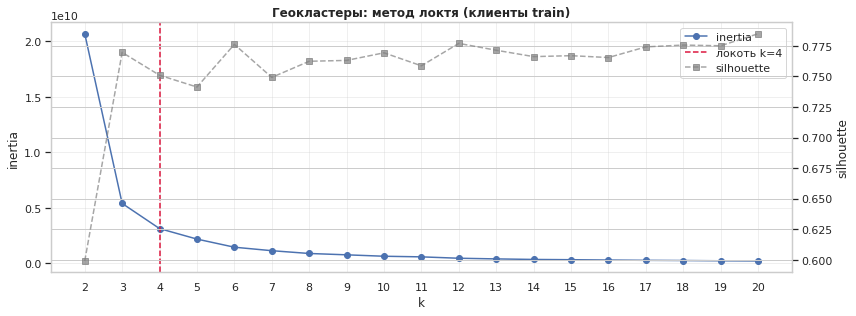

k,inertia,silhouette
2,20694918080.896999,0.599000
3,5394230354.604000,0.770000
4,3125874462.512000,0.751000
5,2179529167.051000,0.741000
6,1447718560.204000,0.776000
7,1132984538.819000,0.749000
8,881812330.943000,0.762000
9,760330241.628000,0.763000
10,632454360.171000,0.769000
11,576915964.373000,0.759000


GEO_K (локоть) = 4


In [80]:
GEO_KS = list(range(2, 21))
geo_scan = elbow_scan(cust_train[GEO_COLS], make_geo_model, GEO_KS)
GEO_K = find_elbow(geo_scan.k.tolist(), geo_scan.inertia.tolist())

plot_elbow(geo_scan, GEO_K, 'Геокластеры: метод локтя (клиенты train)')
display(geo_scan.round(3).style.hide(axis='index')
        .background_gradient(subset=['silhouette'], cmap='Greens'))
print(f'GEO_K (локоть) = {GEO_K}')

#### Кластеризация по геолокации

In [81]:
# Возмём 6 кластеров.
# k = 6 — первый пик silhouette после локтя, а инерция падает ещё на 54% относительно k = 4.
GEO_K = 6

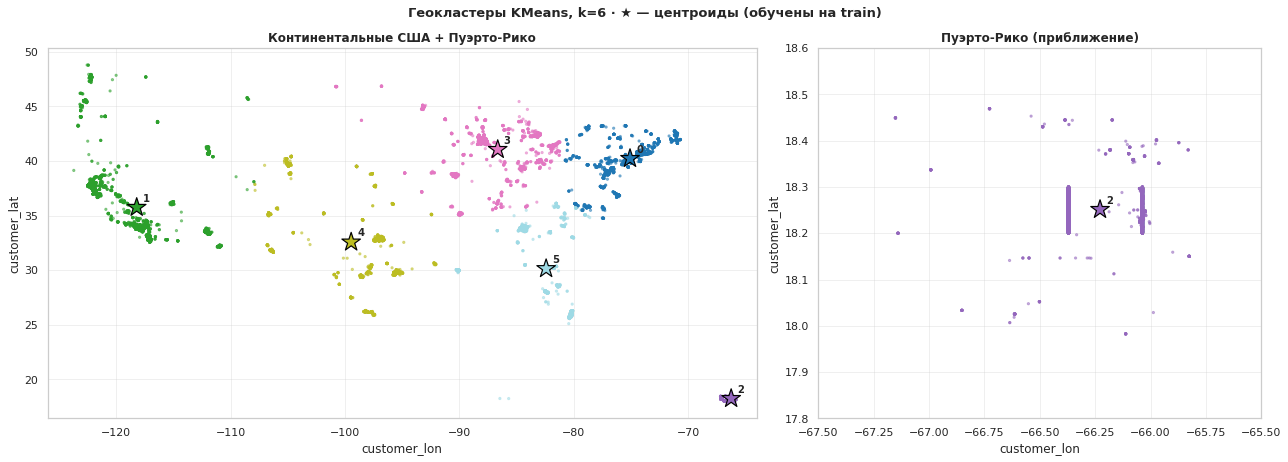

,orders,late_rate,clients,lat,lon,lift
geo_cluster,,,,,,
4,8466,0.554,970,32.570000,-99.460000,1.01
3,12513,0.552,1432,41.050000,-86.640000,1.01
1,22825,0.549,2611,35.750000,-118.220000,1.00
0,15825,0.548,1856,40.220000,-75.070000,1.00
5,6222,0.547,671,30.140000,-82.410000,1.00
2,41870,0.545,4757,18.250000,-66.230000,0.99


кластеры, которых нет среди train-клиентов: нет


In [82]:
geo_model = make_geo_model(GEO_K).fit(cust_train[GEO_COLS])     # fit ТОЛЬКО на train

# метки для всех клиентов: train — fit, val/test — predict по центроидам train
customers['geo_cluster'] = geo_model.predict(customers[GEO_COLS])
c_lat, c_lon = geo_model['proj'].inverse(geo_model['km'].cluster_centers_)


def plot_geo_clusters(cust: pd.DataFrame, c_lat, c_lon, k: int):
    """Карта кластеров: вся зона + приближение континентальных США; ★ — центроиды."""
    cmap = plt.get_cmap('tab20', k)
    fig, axes = plt.subplots(1, 2, figsize=(18, 6.5),
                             gridspec_kw={'width_ratios': [1.6, 1]})
    for ax, (lon_lim, title) in zip(axes, [((-126, -64), 'Континентальные США + Пуэрто-Рико'),
                                           ((-67.5, -65.5), 'Пуэрто-Рико (приближение)')]):
        ax.scatter(cust.customer_lon, cust.customer_lat, c=cust.geo_cluster,
                   cmap=cmap, vmin=-.5, vmax=k - .5, s=5, alpha=.5)
        ax.scatter(c_lon, c_lat, marker='*', s=380, c=range(k), cmap=cmap,
                   vmin=-.5, vmax=k - .5, edgecolor='black', linewidth=1.2, zorder=3)
        for i, (la, lo) in enumerate(zip(c_lat, c_lon)):
            if lon_lim[0] <= lo <= lon_lim[1]:
                ax.annotate(str(i), (lo, la), xytext=(6, 6), textcoords='offset points',
                            fontweight='bold', fontsize=10)
        ax.set_xlim(lon_lim)
        ax.set_xlabel('customer_lon'); ax.set_ylabel('customer_lat')
        ax.set_title(title, fontweight='bold'); ax.grid(alpha=.3)
    axes[1].set_ylim(17.8, 18.6)
    fig.suptitle(f'Геокластеры KMeans, k={k} · ★ — центроиды (обучены на train)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()


plot_geo_clusters(customers, c_lat, c_lon, GEO_K)

# --- профиль зон: объём и доля опозданий (только train!) ---
geo_profile = (df_train[[GROUP_COL, TARGET]]
               .join(customers['geo_cluster'], on=GROUP_COL)
               .groupby('geo_cluster')[TARGET].agg(orders='size', late_rate='mean')
               .join(customers.loc[ids_train].groupby('geo_cluster').size().rename('clients'))
               .assign(lat=np.round(c_lat, 2), lon=np.round(c_lon, 2),
                       lift=lambda d: d.late_rate / BASE_LATE)
               .sort_values('late_rate', ascending=False))
display(geo_profile.style.format({'late_rate': '{:.3f}', 'lift': '{:.2f}'})
        .background_gradient(subset=['late_rate'], cmap='RdYlGn_r'))

# --- контроль утечки и покрытия ---
assert customers['geo_cluster'].notna().all()
print('кластеры, которых нет среди train-клиентов:',
      set(customers.loc[ids_val, 'geo_cluster']) - set(customers.loc[ids_train, 'geo_cluster']) or 'нет')

In [83]:
geo_x_mode = (df_train[[GROUP_COL, 'shipping_mode', TARGET]]
              .join(customers['geo_cluster'], on=GROUP_COL)
              .pivot_table(index='geo_cluster', columns='shipping_mode',
                           values=TARGET, aggfunc='mean', observed=True))
display(geo_x_mode.style.format('{:.3f}').background_gradient(cmap='RdYlGn_r', axis=None))

shipping_mode,first class,same day,second class,standard class
geo_cluster,,,,
0,0.944,0.433,0.763,0.380
1,0.960,0.507,0.772,0.373
2,0.951,0.441,0.767,0.382
3,0.961,0.456,0.772,0.387
4,0.948,0.463,0.764,0.386
5,0.930,0.445,0.756,0.391


#### Промежуточный вывод

Координаты переведены в километры (проекция с центром по train), потому что StandardScaler исказил бы расстояния. Проекция и KMeans обучены только на клиентах train, клиенты val и test получают метку ближайшего центроида. Утечки нет.

Формальный локоть — k = 4. Выбрано k = 6: это первый пик silhouette после локтя (0.776 против 0.751 при k = 4),
а инерция ниже на 54% по сравнению с k = 4. Пуэрто-Рико выделяется в отдельную зону, и это
крупнейший рынок: 39% заказов train. На Пуэрто-Рико видны вертикальные «столбики» координат —
вероятно, артефакт геокодирования. Это ограничение данных.

**Гипотеза о труднодоступных районах не подтвердилась.** Доля опозданий по зонам 0.545–0.554 (lift 0.99–1.01). Внутри тарифов разброс небольшой: standard class, 3 п.п. в first class (0.930–0.961), 7 п.п. в same day (0.433–0.507, мало заказов).
География на опоздания почти не влияет — ни сама по себе, ни во взаимодействии с тарифом.

geo_cluster всё равно добавляем в модели, как требует задание, и проверяем его вклад на val.
Если прироста не будет, это честный результат: опоздания определяет тариф, а не местоположение клиента.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

* используются только клиенты train
* проекция обучается по train
* KMeans обучается только по train

##  Кластеризация по признакам профилей клиентов





1. Подготовьте векторы признаков — используйте пять ключевых показателей из датасета `df_customers.csv`: `recency`, `total_orders`, `total_sales`, `return_rate` и `avg_discount`.
2. Выполните предобработку данных и обеспечьте защиту от утечек.
3. Используйте метод локтя, чтобы найти математически обоснованную границу количества групп.
4. Проанализируйте полученные кластеры: дайте статистическую характеристику и опишите самые яркие группы.
5. Визуализируйте положение кластеров с помощью t-SNE.



### Подготовка и проверка признаков

In [84]:
RFM_SRC_COLS = ['recency', 'total_orders', 'total_sales', 'return_rate', 'avg_discount']
RFM_FEATS    = ['recency_sqrt', 'orders_log', 'avg_check_log', 'return_rate', 'avg_discount']
RFM_VERSION  = 'v1'


class CustomerProfileEncoder(BaseEstimator, TransformerMixin):
    """
    Пять исходных показателей → пять признаков для KMeans.
    Без обучаемых параметров, поэтому утечки здесь быть не может.
      recency      → sqrt          (skew 1.49 → 0.49)
      total_orders → log1p         (skew 0.92 → 0.30)
      total_sales  → log1p(total_sales / total_orders) — средний чек,
                     убирает дубль с total_orders (Spearman 0.92)
      return_rate, avg_discount → как есть (доли, хвостов нет)
    """
    def __init__(self, version=RFM_VERSION):
        self.version = version

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X[RFM_SRC_COLS].astype('float64')
        return pd.DataFrame({
            'recency_sqrt':  np.sqrt(X['recency']),
            'orders_log':    np.log1p(X['total_orders']),
            'avg_check_log': np.log1p(X['total_sales'] / X['total_orders']),
            'return_rate':   X['return_rate'],
            'avg_discount':  X['avg_discount'],
        }, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array(RFM_FEATS)


def make_rfm_model(k: int) -> Pipeline:
    """Encoder (stateless) → StandardScaler (fit на train) → KMeans (fit на train)."""
    return Pipeline([('enc',   CustomerProfileEncoder()),
                     ('scale', StandardScaler()),
                     ('km',    KMeans(n_clusters=k, n_init=10, random_state=SEED))])


# --- контроль: после кодирования перекос и дубли ушли ---
enc_train = CustomerProfileEncoder().transform(cust_train)
display(pd.DataFrame({'skew': enc_train.apply(skew)}).T.style.format('{:+.2f}'))
display(enc_train.corr(method='spearman').round(2)
        .style.background_gradient(cmap='RdBu_r', vmin=-1, vmax=1))

,recency_sqrt,orders_log,avg_check_log,return_rate,avg_discount
skew,+0.49,+0.30,-1.68,+4.82,+0.47


,recency_sqrt,orders_log,avg_check_log,return_rate,avg_discount
recency_sqrt,1.000000,0.620000,0.580000,0.140000,0.020000
orders_log,0.620000,1.000000,0.570000,0.250000,0.030000
avg_check_log,0.580000,0.570000,1.000000,0.130000,-0.050000
return_rate,0.140000,0.250000,0.130000,1.000000,0.010000
avg_discount,0.020000,0.030000,-0.050000,0.010000,1.000000


### Подбор числа кластеров

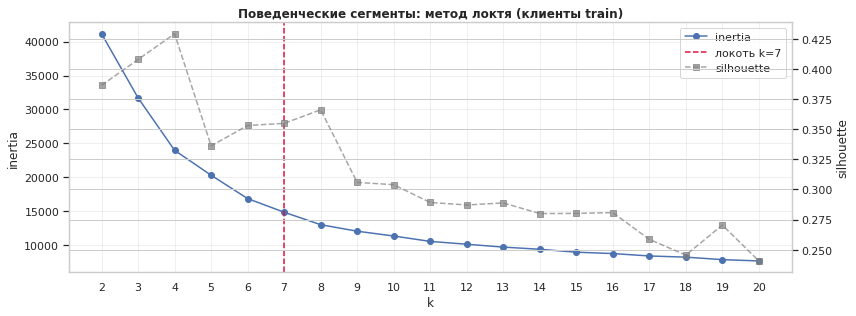

k,inertia,silhouette
2,41170.633000,0.386000
3,31698.524000,0.408000
4,23954.026000,0.429000
5,20273.677000,0.336000
6,16823.013000,0.353000
7,14809.663000,0.355000
8,12967.690000,0.366000
9,12005.172000,0.306000
10,11295.201000,0.304000
11,10499.942000,0.289000


RFM_K (локоть) = 7


In [85]:
RFM_KS = list(range(2, 21))
rfm_scan = elbow_scan(cust_train[RFM_SRC_COLS], make_rfm_model, RFM_KS)
RFM_K_ELBOW = find_elbow(rfm_scan.k.tolist(), rfm_scan.inertia.tolist())

plot_elbow(rfm_scan, RFM_K_ELBOW, 'Поведенческие сегменты: метод локтя (клиенты train)')
display(rfm_scan.round(3).style.hide(axis='index')
        .background_gradient(subset=['silhouette'], cmap='Greens'))
print(f'RFM_K (локоть) = {RFM_K_ELBOW}')

### Кластеризация

In [86]:
RFM_K = RFM_K_ELBOW            
rfm_model = make_rfm_model(RFM_K).fit(cust_train[RFM_SRC_COLS])
customers['behavior_segment'] = rfm_model.predict(customers[RFM_SRC_COLS])

seg_tr = customers.loc[ids_train, 'behavior_segment']

# 1) медианы в исходных единицах + доля опозданий по train-заказам
seg_late = (df_train[[GROUP_COL, TARGET]]
            .join(customers['behavior_segment'], on=GROUP_COL)
            .groupby('behavior_segment')[TARGET].agg(orders='size', late_rate='mean'))

rfm_profile = (cust_train.assign(avg_check=cust_train.total_sales / cust_train.total_orders,
                                 has_returns=(cust_train.return_rate > 0).astype(int))
               .groupby(seg_tr)[RFM_SRC_COLS + ['avg_check', 'has_returns']]
               .agg({**{c: 'median' for c in RFM_SRC_COLS + ['avg_check']},
                     'has_returns': 'mean'})
               .join(seg_tr.value_counts().rename('clients'))
               .join(seg_late)
               .assign(clients_share=lambda d: d.clients / d.clients.sum(),
                       lift=lambda d: d.late_rate / BASE_LATE)
               .sort_values('late_rate', ascending=False))

display(rfm_profile.style
        .format({'recency': '{:.0f}', 'total_orders': '{:.0f}', 'total_sales': '{:,.0f}',
                 'avg_check': '{:,.0f}', 'return_rate': '{:.3f}', 'avg_discount': '{:.3f}',
                 'has_returns': '{:.1%}', 'clients_share': '{:.1%}',
                 'late_rate': '{:.3f}', 'lift': '{:.2f}'})
        .background_gradient(subset=['late_rate'], cmap='RdYlGn_r')
        .set_caption('Медианы по сегментам (train), has_returns — доля клиентов с возвратами'))

# 2) центроиды 
z_profile = pd.DataFrame(rfm_model['km'].cluster_centers_, columns=RFM_FEATS)
z_profile.index.name = 'behavior_segment'
display(z_profile.style.format('{:+.2f}')
        .background_gradient(cmap='RdBu_r', vmin=-2, vmax=2)
        .set_caption('Центроиды KMeans в std от среднего train'))

# 3) значимость сегмента для TARGET — так же, как у остальных признаков
d = df_train[[GROUP_COL, TARGET]].join(customers['behavior_segment'], on=GROUP_COL)
s = d['behavior_segment'].astype('category')
print(f'IV={compute_iv(s, d[TARGET]):.4f} · p_chi2={chi2_pvalue(s, d[TARGET]):.1e} · '
      f'Cramér V={cramers_v(s, d[TARGET]):.4f}')

,recency,total_orders,total_sales,return_rate,avg_discount,avg_check,has_returns,clients,orders,late_rate,clients_share,lift
behavior_segment,,,,,,,,,,,,
2,75,1,321,0.000,0.050,321,0.0%,1839,2241,0.579,15.0%,1.06
1,46,1,30,0.000,0.170,30,0.0%,730,731,0.573,5.9%,1.05
5,76,1,279,0.000,0.170,274,0.1%,1474,1696,0.571,12.0%,1.04
6,46,1,36,0.000,0.050,36,0.0%,873,874,0.551,7.1%,1.01
0,213,5,"2,829",0.000,0.102,538,22.4%,4861,81118,0.550,39.5%,1.00
4,519,3,"1,517",0.000,0.101,531,9.3%,2236,20483,0.546,18.2%,1.00
3,78,1,273,1.000,0.100,263,100.0%,284,578,0.097,2.3%,0.18


,recency_sqrt,orders_log,avg_check_log,return_rate,avg_discount
behavior_segment,,,,,
0,+0.24,+1.01,+0.51,+0.00,-0.01
1,-1.05,-1.02,-2.30,-0.28,+1.41
2,-0.82,-0.99,+0.11,-0.28,-1.10
3,-0.48,-0.87,-0.43,+5.72,+0.07
4,+1.51,+0.12,+0.46,-0.12,-0.02
5,-0.82,-0.99,-0.04,-0.27,+1.41
6,-1.06,-1.02,-2.14,-0.28,-1.14


IV=0.0243 · p_chi2=1.2e-102 · Cramér V=0.0674


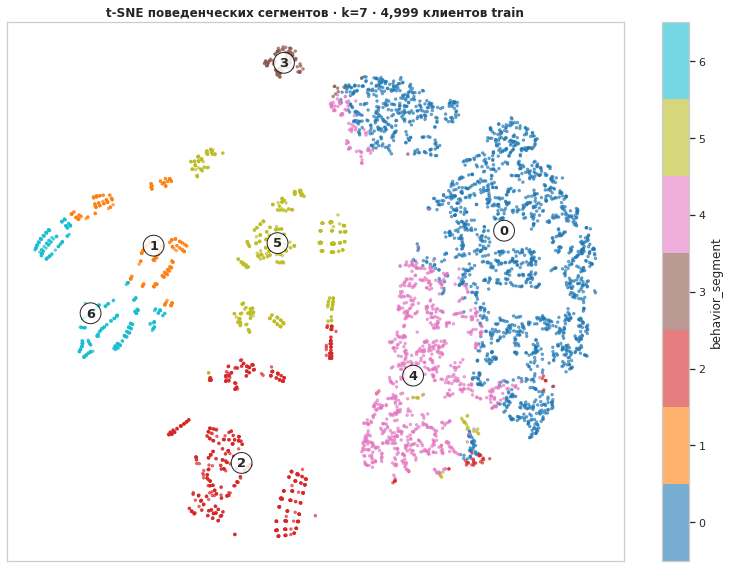

In [87]:
N_TSNE = 5000
sample = (cust_train.assign(seg=seg_tr)
          .groupby('seg', group_keys=False)
          .sample(frac=min(1, N_TSNE / len(cust_train)), random_state=SEED))  # стратифицированно

Z   = rfm_model[:-1].transform(sample[RFM_SRC_COLS])        # то же пространство, что видел KMeans
emb = TSNE(n_components=2, perplexity=40, init='pca', random_state=SEED).fit_transform(Z)
seg = sample['seg'].to_numpy()

fig, ax = plt.subplots(figsize=(11, 8))
cmap = plt.get_cmap('tab10' if RFM_K <= 10 else 'tab20', RFM_K)
sc = ax.scatter(emb[:, 0], emb[:, 1], c=seg, cmap=cmap,
                vmin=-.5, vmax=RFM_K - .5, s=6, alpha=.6)
for k in range(RFM_K):
    cx, cy = np.median(emb[seg == k], axis=0)
    ax.annotate(str(k), (cx, cy), fontsize=13, fontweight='bold', ha='center', va='center',
                bbox=dict(boxstyle='circle', fc='white', ec='black', alpha=.85))
plt.colorbar(sc, ticks=range(RFM_K), label='behavior_segment')
ax.set_title(f't-SNE поведенческих сегментов · k={RFM_K} · {len(sample):,} клиентов train',
             fontweight='bold')
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### Промежуточный вывод

| № | Название | Яркая черта (z) | Клиенты / заказы | `late_rate` |
|---:|---|---|---|---:|
| 0 | Лояльное ядро | Заказов `+1.01`: 5 заказов, выручка 2.8 тыс. | 39.5% / 75.3% | 0.550 |
| 4 | Уходящие | `recency +1.51`: 519 дней без заказов, 3 заказа | 18.2% / 19.0% | 0.546 |
| 2 | Разовые, обычный чек, без акций | Скидка `−1.10` | 15.0% / 2.1% | 0.579 |
| 5 | Охотники за скидкой | Скидка `+1.41`, обычный чек | 12.0% / 1.6% | 0.571 |
| 1 | Разовые, дешёвый товар по акции | Чек `−2.30`, скидка `+1.41` | 5.9% / 0.7% | 0.573 |
| 6 | Разовые, дешёвый товар без акции | Чек `−2.14`, скидка `−1.14` | 7.1% / 0.8% | 0.551 |
| 3 | Возвратчики | `return_rate +5.72`; у 100% клиентов есть возвраты | 2.3% / 0.5% | 0.097 |


1. Опоздания отличаются только у сегмента `3`: `late_rate = 0.101` против базового уровня `0.548`, `lift = 0.18`. Все остальные сегменты находятся в коридоре `±3 п.п.` от базового уровня.

2. У клиентов сегмента `3` значение `return_rate = 1`, то есть отменены все их заказы. Отменённый заказ не доставляется и не может опоздать. Это подтверждает подозрение на утечку через `return_rate`, а не бизнес-гипотезу о «проблемных» клиентах.

3. Сегмент покрывает лишь `0.6%` заказов, поэтому его ожидаемый вклад в ROC-AUC составляет около `+0.002–0.005`.

4. `IV` сегмента составляет `0.024` — это примерно вдвое ниже, чем у исходного return_rate `(0.048)`. Клиенты с частичными возвратами не вошли в отдельный сегмент: возвраты есть у `22.4%` клиентов сегмента `0` и у `9.3%` клиентов сегмента `4`. Следовательно, сегмент является огрублённой версией `return_rate`, а исходный признак нужно подавать в модель вместе с сегментом.

**t-SNE**

- Возвратчики, сегмент `3`, образуют изолированный остров.
- Лояльное ядро, сегмент `0`, и уходящие клиенты, сегмент `4`, плавно переходят друг в друга по оси давности последнего заказа (`recency`).
- Разовые сегменты выглядят как «полосатые» островки, потому что скидка и число заказов имеют дискретную структуру.

**Итог:** ни география, ни поведение клиента опоздания не объясняют.
Опоздание определяется тарифом доставки (и в меньшей степени временем оформления заказа).
Ожидаемый вклад кластеров в ROC-AUC — единицы тысячных; потолок ≈ 0.76 задаёт shipping_mode × order_hour.

### Итоговое кодирование признаков для моделей


| Признак | Источник | CatBoost | Logistic Regression | Комментарий |
|---|---|---|---|---|
| `shipping_mode` | `orders` | Нативная категориальная переменная (`cat_features`) | Отдельно не подаётся: входит в `mode_pm` | Главный сигнал, `IV = 1.152` |
| `is_pm` (`order_hour >= 12`) | `orders` | Не нужен: подаём исходный `order_hour` | Отдельно не подаётся: входит в `mode_pm` | Ступенька в 12:00 |
| `order_hour` | `orders` | Нативный числовой признак | Заменён на `is_pm` | CatBoost найдёт порог самостоятельно |
| `mode_pm` | `shipping_mode × is_pm` | Не нужен | OHE, 8 уровней, без `drop` (дамми-ловушку снимает L2) | Значимое взаимодействие, `+0.034` ROC-AUC |
| `geo_cluster` (на этом этапе `k = 6`, финально `k = 12`) | `customers → KMeans` | Нативная категориальная переменная (`cat_features`) | OHE | Добавлен по заданию; сигнал примерно равен `0` |
| `behavior_segment` (на этом этапе `k = 7`, финально `k = 6`) | `customers → KMeans` | Нативная категориальная переменная (`cat_features`) | OHE | Сигнал есть только у сегмента возвратчиков (на этом этапе сегмент `3`) |
| `category_name`, `order_month`, `order_weekday` | `orders` | Только для ablation | Только для ablation: OHE (`category_name` с объединением редких категорий), `sin/cos` для месяца | Шумовые признаки, по итогам ablation удалены |
| `item_price` | `orders` | Удалён | Удалён | Дубль `category_name`, `phik = 0.973` |
| `order_id`, `customer_id` | `orders` | Удалены | Удалены | Ключи; `customer_id` нужен только для `GroupKFold` и подстановки кластеров |
| `order_date` | `orders` | Вход пайплайна, в модель не идёт | Вход пайплайна, в модель не идёт | `OrderCleaner` раскладывает на месяц, день недели и час |

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Хорошо, что ты сам заметил потенциальную временную утечку через клиентские агрегаты и не интерпретируешь их бесконтрольно

##  Обучение модели на новых признаках

1. Добавьте результаты кластеризаций в данные для обучения моделей.
2. Обучите финальные версии логистической регрессии и `CatBoostClassifier` на расширенном наборе данных.
3. Рассчитайте итоговые значения метрики ROC−AUC на валидационной выборке.
   

### Обучение с кластерами

In [88]:
CLUSTER_COLS      = ('geo_cluster', 'behavior_segment')   # признаки из unsupervised-этапа

def add_clusters(X_raw: pd.DataFrame, df_src: pd.DataFrame) -> pd.DataFrame:
    """Сырой вход заказа + метки кластеров клиента (KMeans обучен на train-клиентах)."""
    ids = df_src.loc[X_raw.index, GROUP_COL]
    X = X_raw.assign(**{c: ids.map(customers[c]).to_numpy() for c in CLUSTER_COLS})
    assert X[list(CLUSTER_COLS)].notna().all().all(), 'есть заказы без кластера'
    return X


X_train_cl = add_clusters(X_train, df_train)
X_val_cl   = add_clusters(X_val,   df_val)
X_test_cl  = add_clusters(X_test,  df_test)      # test не трогаем до финала

# y, groups — те же, что в baseline (берутся по умолчанию) → фолды CV совпадают
CL_DATA = dict(X=X_train_cl, X_val_=X_val_cl)

RUNS = {
    'LogReg + geo':            (build_lr, ('geo_cluster',)),
    'LogReg + geo + behavior': (build_lr, CLUSTER_COLS),
    'CatBoost + geo':            (build_cb, ('geo_cluster',)),
    'CatBoost + geo + behavior': (build_cb, CLUSTER_COLS),
}

for name, (builder, cl) in RUNS.items():
    base = LR_PARAMS if builder is build_lr else CB_PARAMS
    remember(evaluate(name, 'clusters',
                      lambda builder=builder, cl=cl: builder(clusters=cl),
                      params=base | {'clusters': ', '.join(cl)}, **CL_DATA))

show_results('Baseline + кластеры · метрики на val · порог 0.7')

,этап,Ранг,ТЗ,ROC_AUC_val,ROC_AUC_cv,ROC_AUC_std,PR_AUC,Precision,Recall,F1,Accuracy,flag_share,gap,fit_сек,параметры
модель,,,,,,,,,,,,,,,
LogReg + geo + behavior,clusters,2,✓,0.7688,0.7607,0.0043,0.8199,0.8636,0.5897,0.7008,0.7230,37.6%,-0.0031,15.0,"C=1clusters=geo_cluster, behavior_segmentmax_iter=1000random_state=42"
CatBoost + geo + behavior,clusters,4,✓,0.7681,0.7602,0.0049,0.8283,0.8634,0.5886,0.7000,0.7224,37.5%,0.0075,186.3,"clusters=geo_cluster, behavior_segmentdepth=4eval_metric=AUCiterations=500learning_rate=0.05random_seed=42thread_count=-1verbose=0"
LogReg + geo,clusters,9,✓,0.7662,0.7574,0.0046,0.8131,0.8596,0.5907,0.7002,0.7217,37.8%,-0.0055,27.7,C=1clusters=geo_clustermax_iter=1000random_state=42
Rule: тариф×час,baseline,9,✓,0.7620,0.7581,0.0055,0.7898,0.8596,0.5907,0.7002,0.7217,37.8%,-0.0022,3.7,—
CatBoost,baseline,9,✓,0.7619,0.7583,0.0057,0.8177,0.8596,0.5907,0.7002,0.7217,37.8%,0.0037,146.3,depth=4eval_metric=AUCiterations=500learning_rate=0.05random_seed=42thread_count=-1verbose=0
CatBoost + geo,clusters,11,✓,0.7622,0.7561,0.0036,0.8208,0.8595,0.5899,0.6996,0.7213,37.8%,0.0082,165.6,clusters=geo_clusterdepth=4eval_metric=AUCiterations=500learning_rate=0.05random_seed=42thread_count=-1verbose=0
LogReg,baseline,11,✓,0.7618,0.7581,0.0055,0.7892,0.8596,0.5907,0.7002,0.7217,37.8%,-0.0021,22.7,C=1max_iter=1000random_state=42
Rule: тариф,baseline,16,"✗ AUC≤0.75, AUC_cv≤порога",0.7329,0.7274,0.0034,0.7565,0.8538,0.5462,0.6662,0.6989,35.2%,-0.0056,3.5,—
Dummy,baseline,—,"✗ AUC≤0.75, AUC_cv≤порога, нет p≥0.7",0.5000,0.5000,0.0000,0.5502,0.0000,0.0000,0.0000,0.4498,0.0%,0.0000,3.3,—


#### Промежуточный вывод

Кластеры дают прирост: LogReg + geo + behavior 0.7688 на val против 0.7618 у LogReg
(+0.0070), CV 0.7607 против 0.7581 (+0.0026). Один geo_cluster почти ничего не добавляет:
val +0.0044, CV −0.0007. CatBoost с кластерами не лучше LogReg (0.7681 против 0.7688),
но в 14 раз медленнее. Требование ROC-AUC > 0.75 выполнено во всех моделях с кластерами.

### Ablation test

In [89]:
# ============================== Конфигурация ablation ==============================
SOFT_ALL = ('order_month', 'order_weekday', 'category_name')

ABLATION_STEPS = {
    '+ order_month':   ('order_month',),
    '+ order_weekday': ('order_weekday',),
    '+ category_name': ('category_name',),
    '+ все шумовые':   SOFT_ALL,
}

# --- проверка, что всё нужное для ablation уже есть в окружении ---
required = ['_soft_set', 'make_lr_preprocessor', 'cb_feature_spec', 'build_lr', 'build_cb',
            'X_train_cl', 'X_val_cl', 'y_train', 'y_val', 'groups_train', 'CV', 'CLUSTER_COLS']
missing = [n for n in required if n not in globals()]
assert not missing, f'не определены: {missing}'

# --- проверка, что препроцессор LogReg действительно добавляет признаки по одному ---
for step, soft in ABLATION_STEPS.items():
    cols = make_lr_preprocessor(use_soft=soft, clusters=CLUSTER_COLS) \
               .fit(X_train_cl.head(2000), y_train.head(2000)).get_feature_names_out()
    extra = [c for c in cols if not c.startswith(('mode_pm', 'geo_cluster', 'behavior_segment'))]
    print(f'{step:<16} → {len(extra):>2} доп. колонок: {extra[:6]}{" …" if len(extra) > 6 else ""}')

+ order_month    →  2 доп. колонок: ['month_sin', 'month_cos']
+ order_weekday  →  7 доп. колонок: ['order_weekday_0', 'order_weekday_1', 'order_weekday_2', 'order_weekday_3', 'order_weekday_4', 'order_weekday_5'] …
+ category_name  → 12 доп. колонок: ['category_name_accessories', 'category_name_camping & hiking', 'category_name_cardio equipment', 'category_name_cleats', 'category_name_electronics', 'category_name_fishing'] …
+ все шумовые    → 21 доп. колонок: ['month_sin', 'month_cos', 'order_weekday_0', 'order_weekday_1', 'order_weekday_2', 'order_weekday_3'] …


In [90]:
CV_FAST = GroupKFold(n_splits=3)
CB_FAST = dict(iterations=200)


def fold_aucs(builder, X, y=y_train, groups=groups_train,
              X_val_=None, y_val_=y_val, cv=CV):                                   # ← cv
    aucs = np.array([
        roc_auc_score(y.iloc[te],
                      builder().fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1])
        for tr, te in cv.split(X, y, groups)
    ])
    auc_val = roc_auc_score(y_val_, builder().fit(X, y).predict_proba(X_val_)[:, 1])
    return aucs, auc_val


def run_ablation(model_name, build, steps, cv=CV, clusters=CLUSTER_COLS, **fit_kw):
    """Парное сравнение с базой: одинаковые фолды, одинаковые гиперпараметры."""
    X, Xv = X_train_cl, X_val_cl
    base_cv, base_val = fold_aucs(lambda: build(clusters=clusters, **fit_kw),
                                  X, X_val_=Xv, cv=cv)
    rows = [dict(модель=model_name, шаг='база (+ geo + behavior)',
                 AUC_cv=base_cv.mean(), AUC_val=base_val,
                 Δ_cv=0.0, Δ_std=0.0, Δ_val=0.0, фолдов_лучше='—', решение='—')]

    for step, soft in steps.items():
        cv_, val = fold_aucs(lambda soft=soft: build(use_soft=soft, clusters=clusters, **fit_kw),
                             X, X_val_=Xv, cv=cv)
        d = cv_ - base_cv
        keep = (d.mean() > 0) and (d.mean() > d.std()) and (val > base_val)
        rows.append(dict(модель=model_name, шаг=step,
                         AUC_cv=cv_.mean(), AUC_val=val,
                         Δ_cv=d.mean(), Δ_std=d.std(), Δ_val=val - base_val,
                         фолдов_лучше=f'{int((d > 0).sum())}/{len(d)}',
                         решение='✓ оставить' if keep else '✗ удалить'))
    return pd.DataFrame(rows)


# 1) LogReg: все шаги, рабочие 5 фолдов
abl_lr = run_ablation('LogReg', build_lr, ABLATION_STEPS)

# 2) CatBoost: один контрольный шаг на взаимодействия, облегчённо
abl_cb = run_ablation('CatBoost (3 фолда, 200 итер.)', build_cb,
                      {'+ все шумовые': SOFT_ALL}, cv=CV_FAST, **CB_FAST)

ablation = pd.concat([abl_lr, abl_cb], ignore_index=True)
display(ablation.style.hide(axis='index')
        .format({'AUC_cv': '{:.4f}', 'AUC_val': '{:.4f}',
                 'Δ_cv': '{:+.4f}', 'Δ_std': '{:.4f}', 'Δ_val': '{:+.4f}'})
        .background_gradient(subset=['Δ_cv', 'Δ_val'], cmap='RdYlGn', vmin=-.005, vmax=.005)
        .map(lambda v: 'color: green; font-weight: bold' if v == '✓ оставить'
             else ('color: crimson' if v == '✗ удалить' else ''), subset=['решение'])
        .set_caption('Ablation шумовых признаков · LogReg — главные эффекты, '
                     'CatBoost — контроль взаимодействий'))

модель,шаг,AUC_cv,AUC_val,Δ_cv,Δ_std,Δ_val,фолдов_лучше,решение
LogReg,база (+ geo + behavior),0.7607,0.7688,+0.0000,0.0000,+0.0000,—,—
LogReg,+ order_month,0.7590,0.7688,-0.0017,0.0013,+0.0000,0/5,✗ удалить
LogReg,+ order_weekday,0.7612,0.7691,+0.0005,0.0008,+0.0002,4/5,✗ удалить
LogReg,+ category_name,0.7608,0.7665,+0.0001,0.0009,-0.0023,3/5,✗ удалить
LogReg,+ все шумовые,0.7601,0.7671,-0.0006,0.0011,-0.0018,2/5,✗ удалить
"CatBoost (3 фолда, 200 итер.)",база (+ geo + behavior),0.7612,0.7696,+0.0000,0.0000,+0.0000,—,—
"CatBoost (3 фолда, 200 итер.)",+ все шумовые,0.7600,0.7697,-0.0012,0.0025,+0.0000,1/3,✗ удалить


#### Промежуточный вывод

Проверили три признака, которые на EDA оказались слабыми (IV < 0.02): order_month,
order_weekday и category_name. Сравнивали парно с базой (+ geo + behavior) на одних
и тех же фолдах GroupKFold.

**Главные эффекты (LogReg, 5 фолдов).** Ни один признак не даёт прироста больше
разброса между фолдами. order_month стабильно ухудшает модель (−0.0017, хуже на 5 фолдах из 5).
order_weekday даёт +0.0005 при std 0.0008 (лучше на 4 фолдах из 5, но меньше разброса), category_name +0.0001 при std 0.0009. Все три вместе дают −0.0006.

**Взаимодействия (CatBoost, контрольный прогон).** Добавление всех шумовых признаков
даёт Δ_cv = −0.0012 (улучшение на 1 фолде из 3). Значит, скрытого сигнала во
взаимодействиях с тарифом и кластерами нет. На val разницы нет (+0.0000), CV ухудшение.

**Решение:** order_month, order_weekday и category_name удаляем из обеих моделей.
Результаты EDA подтвердились: сезонность, день недели и категория товара на опоздание
не влияют. Плюс для продакшена: модели нужны только тариф, время заказа
и метки кластеров клиента.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

На текущей выборке Логрег с обоими кластерами получает validation ROC-AUC 0.7693 против 0.7619 у текущего baseline

## Дополнительное задание — подбор лучшего количества кластеров

Рассмотрите количество кластеров как гиперпараметр всей системы и найти ту «степень детализации», которая даст максимальный прирост ROC-AUC.

Вы можете взять значения из списка или выбрать свои:

```python
geo_k_range = [4, 8, 12, 20]
rfm_k_range = [6, 12, 20, 30]
```



In [91]:
path_grid = Path('grid_k.pkl')
path_safe = Path('grid_k_safe.pkl')

# это, чтобы при перезапуске ядра не пересчитывать модель с разным числом кластеров
grid = pd.read_pickle(path_grid) if path_grid.is_file() else None
grid_safe = pd.read_pickle(path_safe) if path_safe.is_file() else None
# grid, grid_safe = None, None

In [92]:
GEO_COLS      = ['customer_lat', 'customer_lon']
RFM_COLS      = ['recency', 'total_orders', 'total_sales', 'avg_discount', 'return_rate']
RFM_COLS_SAFE = [c for c in RFM_COLS if c != 'return_rate']        # контроль утечки
LOG_COLS      = ['recency', 'total_orders', 'total_sales']         # скошенные признаки

geo_k_range = [0, 4, 6, 8, 12, 20]
rfm_k_range = [0, 6, 7, 12, 20, 30]

cust_idx  = data.customers.df.set_index('customer_id')
train_ids = df_train['customer_id'].unique()       # KMeans видит только клиентов из train


def cluster_labels(cols: list, k: int) -> pd.Series:
    """KMeans, обученный только на клиентах из train → метка для каждого клиента."""
    X = cust_idx[cols].astype('float64')
    X = X.assign(**{c: np.log1p(X[c]) for c in cols if c in LOG_COLS})
    km = Pipeline([
        ('scale',  StandardScaler()),
        ('kmeans', KMeans(n_clusters=k, n_init=10, random_state=SEED)),
    ])
    km.fit(X.loc[train_ids])
    return pd.Series(km.predict(X), index=cust_idx.index)


# метки считаем один раз для каждого k (кэш)
GEO_LABELS  = {k: cluster_labels(GEO_COLS, k) for k in geo_k_range if k}
RFM_LABELS  = {k: cluster_labels(RFM_COLS, k) for k in rfm_k_range if k}
SAFE_LABELS = {k: cluster_labels(RFM_COLS_SAFE, k) for k in rfm_k_range if k}


def with_clusters(X_raw, df_src, geo_k, rfm_k, rfm_labels=RFM_LABELS):
    """Сырой вход заказа + метки кластеров с заданной детализацией."""
    ids = df_src.loc[X_raw.index, 'customer_id']
    X, used = X_raw.copy(), []
    if geo_k:
        X['geo_cluster'] = ids.map(GEO_LABELS[geo_k]).to_numpy();      used.append('geo_cluster')
    if rfm_k:
        X['behavior_segment'] = ids.map(rfm_labels[rfm_k]).to_numpy(); used.append('behavior_segment')
    return X, tuple(used)

In [93]:
def eval_grid(rfm_labels, tag):
    rows = []
    for g in geo_k_range:
        for r in rfm_k_range:
            Xtr, cl = with_clusters(X_train, df_train, g, r, rfm_labels)
            Xva, _  = with_clusters(X_val,   df_val,   g, r, rfm_labels)
            cv, val = fold_aucs(lambda cl=cl: build_lr(clusters=cl), Xtr, X_val_=Xva)
            rows.append(dict(сегменты=tag, geo_k=g, rfm_k=r, folds=cv,
                             AUC_cv=cv.mean(), AUC_std=cv.std(), AUC_val=val))
    grid = pd.DataFrame(rows)
    base = grid.query('geo_k == 0 and rfm_k == 0')['folds'].iat[0]
    grid['Δ_cv']         = grid['folds'].map(lambda f: (f - base).mean())
    grid['фолдов_лучше'] = grid['folds'].map(lambda f: f'{int((f > base).sum())}/{len(f)}')
    return grid.drop(columns='folds')

if grid is None:
    grid      = eval_grid(RFM_LABELS,  'RFM + return_rate')
    grid_safe = eval_grid(SAFE_LABELS, 'RFM без return_rate')

In [94]:
# сохраняем данные для подбора числа кластеров на диск, чтобы не перевычислять при перезапуске ядра
grid.to_pickle(path_grid); grid_safe.to_pickle(path_safe)

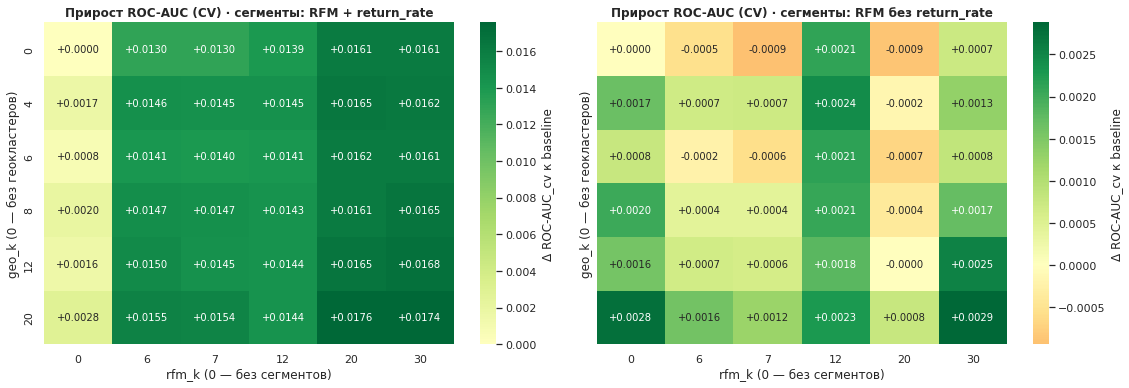

[RFM + return_rate] максимум: geo_k=20, rfm_k=20, AUC_cv=0.7757 | выбор по 1-SE: geo_k=0, rfm_k=6, AUC_cv=0.7711


сегменты,geo_k,rfm_k,AUC_cv,AUC_std,AUC_val,Δ_cv,фолдов_лучше
RFM + return_rate,20,20,0.7757,0.0049,0.7753,+0.0176,5/5
RFM + return_rate,20,30,0.7755,0.0040,0.7769,+0.0174,5/5
RFM + return_rate,12,30,0.7749,0.0033,0.7774,+0.0168,5/5
RFM + return_rate,8,30,0.7747,0.0034,0.7776,+0.0165,5/5
RFM + return_rate,12,20,0.7746,0.0043,0.7768,+0.0165,5/5
RFM + return_rate,4,20,0.7746,0.0044,0.7764,+0.0165,5/5
RFM + return_rate,4,30,0.7743,0.0041,0.7763,+0.0162,5/5
RFM + return_rate,6,20,0.7743,0.0044,0.7767,+0.0162,5/5


[RFM без return_rate] максимум: geo_k=20, rfm_k=30, AUC_cv=0.7610 | выбор по 1-SE: geo_k=0, rfm_k=0, AUC_cv=0.7581


сегменты,geo_k,rfm_k,AUC_cv,AUC_std,AUC_val,Δ_cv,фолдов_лучше
RFM без return_rate,20,30,0.7610,0.0048,0.7660,+0.0029,3/5
RFM без return_rate,20,0,0.7609,0.0050,0.7625,+0.0028,3/5
RFM без return_rate,12,30,0.7607,0.0041,0.7670,+0.0025,2/5
RFM без return_rate,4,12,0.7606,0.0061,0.7626,+0.0024,5/5
RFM без return_rate,20,12,0.7604,0.0054,0.7626,+0.0023,4/5
RFM без return_rate,6,12,0.7603,0.0056,0.7637,+0.0021,4/5
RFM без return_rate,0,12,0.7602,0.0066,0.7619,+0.0021,4/5
RFM без return_rate,8,12,0.7602,0.0056,0.7641,+0.0021,4/5


In [95]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for a, g, title in [(ax[0], grid, 'RFM + return_rate'), (ax[1], grid_safe, 'RFM без return_rate')]:
    hm = g.pivot(index='geo_k', columns='rfm_k', values='Δ_cv')
    sns.heatmap(hm, annot=True, fmt='+.4f', cmap='RdYlGn', center=0, ax=a,
                cbar_kws={'label': 'Δ ROC-AUC_cv к baseline'})
    a.set_title(f'Прирост ROC-AUC (CV) · сегменты: {title}', fontweight='bold')
    a.set_xlabel('rfm_k (0 — без сегментов)'); a.set_ylabel('geo_k (0 — без геокластеров)')
plt.tight_layout(); plt.show()


def pick_1se(g: pd.DataFrame) -> pd.Series:
    """Наименьшая детализация среди вариантов, не хуже лучшего более чем на 1 std."""
    best = g.loc[g['AUC_cv'].idxmax()]
    ok   = g[g['AUC_cv'] >= best['AUC_cv'] - best['AUC_std']]
    return ok.sort_values(['rfm_k', 'geo_k']).iloc[0], best


fmt = {'AUC_cv': '{:.4f}', 'AUC_std': '{:.4f}', 'AUC_val': '{:.4f}', 'Δ_cv': '{:+.4f}'}
for g in (grid, grid_safe):
    choice, best = pick_1se(g)
    tag = g['сегменты'].iat[0]
    print(f'[{tag}] максимум: geo_k={best.geo_k}, rfm_k={best.rfm_k}, AUC_cv={best.AUC_cv:.4f} | '
          f'выбор по 1-SE: geo_k={choice.geo_k}, rfm_k={choice.rfm_k}, AUC_cv={choice.AUC_cv:.4f}')
    display(g.sort_values('AUC_cv', ascending=False).head(8)
             .style.hide(axis='index').format(fmt)
             .background_gradient(subset=['Δ_cv'], cmap='RdYlGn', vmin=-.005, vmax=.005))

### Промежуточный вывод

Перебрали geo_k ∈ {0, 4, 6, 8, 12, 20} × rfm_k ∈ {0, 6, 7, 12, 20, 30} по ROC-AUC
итоговой LogReg на одних и тех же фолдах GroupKFold. KMeans обучался только на клиентах train.

Поведенческие сегменты с return_rate дают основной прирост: +0.0130 уже при rfm_k = 6
(без геокластеров), при rfm_k = 30 — +0.0161. Переход от 6 к 30 сегментам добавляет
всего +0.003, это пологое плато. Без return_rate сегменты дают от −0.0009 до +0.0021:
сигнал сегментов почти целиком идёт от доли возвратов и отмен.

Геокластеры без сегментов дают от +0.0008 до +0.0028 (geo_k = 20 — максимум, +0.0028),
то есть на уровне шума: std между фолдами 0.005. Эффект примерно в 6–8 раз слабее поведенческого.

| Вариант | geo_k × rfm_k | AUC_cv |
|---|---:|---:|
| Максимум | 20 × 20 | 0.7757 |
| Правило 1-SE (порог 0.7708) | 0 × 6 | 0.7711 |
| Выбрано | 12 × 6 | 0.7731 |

По правилу 1-SE выигрывает конфигурация без геокластеров. Мы оставляем geo_k = 12,
так как задание требует использовать оба вида кластеров. Среди конфигураций с обоими признаками
12 × 6 в пределах 1 std от максимума (разница 0.0026 при std 0.0049), а сегментов всего 6,
их можно интерпретировать. Все варианты с запасом проходят требование ROC-AUC > 0.75.

### Фиксация числа кластеров

In [96]:
GEO_K, RFM_K = 12, 6

X_train_cl, CLUSTER_COLS = with_clusters(X_train, df_train, GEO_K, RFM_K)
X_val_cl,  _             = with_clusters(X_val,   df_val,   GEO_K, RFM_K)
X_test_cl, _             = with_clusters(X_test,  df_test,  GEO_K, RFM_K)

for m, build, base in [('LogReg', build_lr, LR_PARAMS), ('CatBoost', build_cb, CB_PARAMS)]:
    remember(evaluate(f'{m} + geo{GEO_K} + rfm{RFM_K}', 'k-tuning',
                      lambda build=build: build(clusters=CLUSTER_COLS),
                      params=base | {'geo_k': GEO_K, 'rfm_k': RFM_K},
                      X=X_train_cl, X_val_=X_val_cl))
show_results('После подбора k · метрики на val · порог 0.7')

,этап,Ранг,ТЗ,ROC_AUC_val,ROC_AUC_cv,ROC_AUC_std,PR_AUC,Precision,Recall,F1,Accuracy,flag_share,gap,fit_сек,параметры
модель,,,,,,,,,,,,,,,
LogReg + geo12 + rfm6,k-tuning,2,✓,0.7776,0.7731,0.0047,0.8356,0.8771,0.5676,0.6892,0.7183,35.6%,-0.0015,34.9,C=1geo_k=12max_iter=1000random_state=42rfm_k=6
CatBoost + geo12 + rfm6,k-tuning,4,✓,0.7767,0.7705,0.0039,0.8397,0.8778,0.5640,0.6867,0.7169,35.4%,0.0086,184.6,depth=4eval_metric=AUCgeo_k=12iterations=500learning_rate=0.05random_seed=42rfm_k=6thread_count=-1verbose=0
LogReg + geo + behavior,clusters,6,✓,0.7688,0.7607,0.0043,0.8199,0.8636,0.5897,0.7008,0.7230,37.6%,-0.0031,15.0,"C=1clusters=geo_cluster, behavior_segmentmax_iter=1000random_state=42"
CatBoost + geo + behavior,clusters,8,✓,0.7681,0.7602,0.0049,0.8283,0.8634,0.5886,0.7000,0.7224,37.5%,0.0075,186.3,"clusters=geo_cluster, behavior_segmentdepth=4eval_metric=AUCiterations=500learning_rate=0.05random_seed=42thread_count=-1verbose=0"
LogReg + geo,clusters,13,✓,0.7662,0.7574,0.0046,0.8131,0.8596,0.5907,0.7002,0.7217,37.8%,-0.0055,27.7,C=1clusters=geo_clustermax_iter=1000random_state=42
Rule: тариф×час,baseline,13,✓,0.7620,0.7581,0.0055,0.7898,0.8596,0.5907,0.7002,0.7217,37.8%,-0.0022,3.7,—
CatBoost,baseline,13,✓,0.7619,0.7583,0.0057,0.8177,0.8596,0.5907,0.7002,0.7217,37.8%,0.0037,146.3,depth=4eval_metric=AUCiterations=500learning_rate=0.05random_seed=42thread_count=-1verbose=0
CatBoost + geo,clusters,15,✓,0.7622,0.7561,0.0036,0.8208,0.8595,0.5899,0.6996,0.7213,37.8%,0.0082,165.6,clusters=geo_clusterdepth=4eval_metric=AUCiterations=500learning_rate=0.05random_seed=42thread_count=-1verbose=0
LogReg,baseline,15,✓,0.7618,0.7581,0.0055,0.7892,0.8596,0.5907,0.7002,0.7217,37.8%,-0.0021,22.7,C=1max_iter=1000random_state=42


<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__

Для полностью честного внутреннего CV scaler и KMeans нужно переобучать отдельно внутри каждого train-фолда. Сейчас клиент из validation-фолда GroupKFold участвует в построении центроидов KMeans

#### Промежуточный вывод

LogReg + geo12 + rfm6: ROC-AUC val 0.7776.
Относительно LogReg без кластеров: +0.0158 на val (0.7618 → 0.7776) и +0.0150 на CV.
Precision при пороге 0.7 выросла с 0.860 до 0.877, recall снизился с 0.591 до 0.568
(предупреждений 35.6% вместо 37.8%). CatBoost не лучше (0.7767) и в 5 раз медленнее.

## Тестирование лучшей модели

На этом этапе вы должны убедиться, что выбранная модель сохраняет высокое качество на данных, которые она никогда не видела, и понять, какие факторы стали решающими для прогноза.

1. Выполните предсказание на тестовой выборке для лучшей модели. Рассчитайте итоговый ROC-AUC и сравните его с целевым показателем 0.75.
2. Постройте матрицу ошибок. Определите, какой тип ошибок совершает модель чаще: пропускает ли она реальные задержки или слишком часто выдаёт ложную тревогу?
3. Визуализируйте важность признаков вашей лучшей модели.
4. Проанализируйте позиции созданных вами признаков `geo_cluster` и `beh_cluster` в общем рейтинге. Стали ли они ключевыми факторами для предсказаний модели для модели или базовые параметры заказа (цена, время) остались приоритетными?

### Оценка лучшей модели на тесте

По рангу выигрывает LogReg, но следом идёт CatBoost. Поскольку данные простые, категориальные и применяется OHE, а сигналов мало, то сложных закономерностей нет и деревья не могу раскрыть свои преимущества. LogReg выучивает сочетание **тариф x час**. А с пилообразными зависимостями справляется за счёт OHE и правильного выделения сигнала в новые признаки, как, например, is_pm. И ещё LogReg выигрывает по ROC-AUC (val 0.7776 против 0.7767, CV 0.7731 против 0.7705) и по переобучению (gap −0.0015 против +0.0086) и в 5 раз быстрее обучается.

✅ Поэтому, как более точную, стабильтную и простую модель выбираем **LogReg** с новыми кластерами.

✅ Сначала, KMeans и лучшую модель обучаем на полной выборке Train + Val.

LogReg + geo12 + rfm6 · KMeans и LogReg обучены на train + val
ROC-AUC test = 0.7701  ·  требование > 0.75  ·  ✓ выполнено
ROC-AUC cv   = 0.7731  ·  разница test − cv = -0.0031


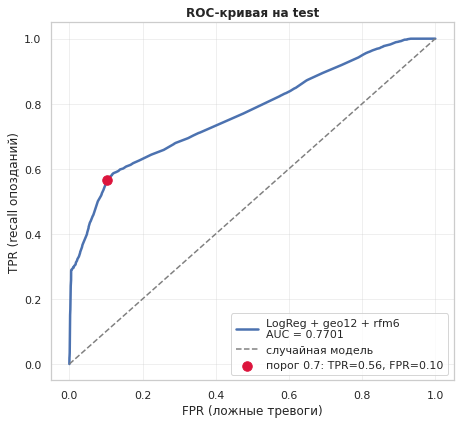

In [97]:
BEST_NAME = f'LogReg + geo{GEO_K} + rfm{RFM_K}'

# ============ 1. KMeans переобучаем на клиентах train + val ============
df_full  = pd.concat([df_train, df_val])
full_ids = df_full['customer_id'].unique()           # клиенты test в fit не входят


def cluster_labels_on(cols: list, k: int, fit_ids) -> pd.Series:
    """Та же схема, что в cluster_labels (log1p → StandardScaler → KMeans), но fit на fit_ids."""
    X = cust_idx[cols].astype('float64')
    X = X.assign(**{c: np.log1p(X[c]) for c in cols if c in LOG_COLS})
    km = Pipeline([('scale',  StandardScaler()),
                   ('kmeans', KMeans(n_clusters=k, n_init=10, random_state=SEED))])
    km.fit(X.loc[fit_ids])
    return pd.Series(km.predict(X), index=cust_idx.index)


GEO_FINAL = cluster_labels_on(GEO_COLS, GEO_K, full_ids).rename('geo_cluster')
RFM_FINAL = cluster_labels_on(RFM_COLS, RFM_K, full_ids).rename('behavior_segment')


def add_final_clusters(X_raw: pd.DataFrame, df_src: pd.DataFrame) -> pd.DataFrame:
    ids = df_src.loc[X_raw.index, 'customer_id']
    return X_raw.assign(geo_cluster=ids.map(GEO_FINAL).to_numpy(),
                        behavior_segment=ids.map(RFM_FINAL).to_numpy())


# ============ 2. Финальное обучение на train + val ============
X_full    = add_final_clusters(pd.concat([X_train, X_val]), df_full)
y_full    = pd.concat([y_train, y_val])
X_test_cl = add_final_clusters(X_test, df_test)      # перезаписываем: ниже его используют матрица ошибок и permutation
assert X_full[list(CLUSTER_COLS)].notna().all().all() and X_test_cl[list(CLUSTER_COLS)].notna().all().all()

final_model = build_lr(clusters=CLUSTER_COLS).fit(X_full, y_full)
proba_test  = final_model.predict_proba(X_test_cl)[:, 1]

# ============ 3. Метрики ============
y_test   = df_test.loc[X_test_cl.index, TARGET]
auc_test = roc_auc_score(y_test, proba_test)
auc_cv   = grid.query('geo_k == @GEO_K and rfm_k == @RFM_K')['AUC_cv'].iat[0]   # без хардкода

print(BEST_NAME, '· KMeans и LogReg обучены на train + val')
print(f'ROC-AUC test = {auc_test:.4f}  ·  требование > {ROC_AUC}  ·  '
      f'{"✓ выполнено" if auc_test > ROC_AUC else "✗ не выполнено"}')
print(f'ROC-AUC cv   = {auc_cv:.4f}  ·  разница test − cv = {auc_test - auc_cv:+.4f}')

# ROC-кривая с отметкой рабочего порога
fpr, tpr, thr = roc_curve(y_test, proba_test)
i07 = np.argmin(np.abs(thr - THRESHOLD))

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr, lw=2.5, label=f'{BEST_NAME}\nAUC = {auc_test:.4f}')
ax.plot([0, 1], [0, 1], ls='--', c='gray', label='случайная модель')
ax.scatter(fpr[i07], tpr[i07], s=90, c='crimson', zorder=3,
           label=f'порог {THRESHOLD}: TPR={tpr[i07]:.2f}, FPR={fpr[i07]:.2f}')
ax.set_xlabel('FPR (ложные тревоги)'); ax.set_ylabel('TPR (recall опозданий)')
ax.set_title('ROC-кривая на test', fontweight='bold'); ax.legend(loc='lower right'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

✅ Модель выполняет требование по ROC-AUC и на тесте с запасом 0.02. Модель не переобучена: разница AUC между тестом и CV -0.0031, что по модулю гораздо меньше порога 0.02.

### Матрица ошибок

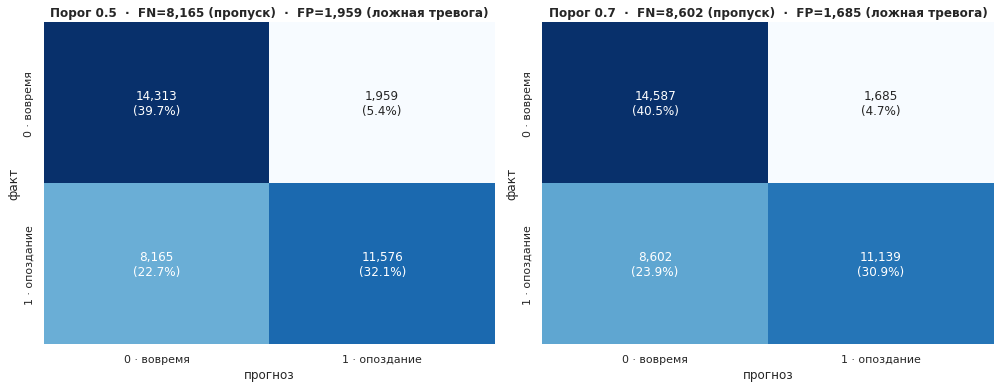

порог,TP,FP,FN,TN,Accuracy,Precision,Recall,F1,доля_предупреждений
0.500000,11576,1959,8165,14313,0.7189,0.8553,0.5864,0.6958,37.6%
0.700000,11139,1685,8602,14587,0.7144,0.8686,0.5643,0.6841,35.6%



При пороге 0.7:
  пропущено опозданий (FN): 8,602.0  = 43.6% всех опозданий
  ложных тревог (FP):       1,685.0  = 10.4% заказов, доставленных вовремя
  преобладает: ПРОПУСК задержек (FN)  (FN/FP = 5.1)


In [98]:
def test_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return pred, dict(порог=thr, TP=tp, FP=fp, FN=fn, TN=tn,
                      Accuracy=accuracy_score(y, pred), Precision=precision_score(y, pred),
                      Recall=recall_score(y, pred), F1=f1_score(y, pred),
                      доля_предупреждений=pred.mean())

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
rows = []
for a, t in zip(ax, [0.5, THRESHOLD]):
    pred, m = test_metrics(y_test, proba_test, t)
    rows.append(m)
    cm = confusion_matrix(y_test, pred)
    annot = np.array([[f'{v:,}\n({v / cm.sum():.1%})' for v in r] for r in cm])
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=a,
                xticklabels=['0 · вовремя', '1 · опоздание'],
                yticklabels=['0 · вовремя', '1 · опоздание'], annot_kws={'fontsize': 12})
    a.set_xlabel('прогноз'); a.set_ylabel('факт')
    a.set_title(f'Порог {t}  ·  FN={m["FN"]:,} (пропуск)  ·  FP={m["FP"]:,} (ложная тревога)',
                fontweight='bold')
plt.tight_layout(); plt.show()

cm_tab = pd.DataFrame(rows)
display(cm_tab.style.hide(axis='index')
        .format({c: '{:.4f}' for c in ['Accuracy', 'Precision', 'Recall', 'F1']}
                | {'доля_предупреждений': '{:.1%}'}))

m07 = cm_tab.set_index('порог').loc[THRESHOLD]
print(f'\nПри пороге {THRESHOLD}:')
print(f'  пропущено опозданий (FN): {m07.FN:,}  = {m07.FN / (m07.FN + m07.TP):.1%} всех опозданий')
print(f'  ложных тревог (FP):       {m07.FP:,}  = {m07.FP / (m07.FP + m07.TN):.1%} заказов, доставленных вовремя')
print(f'  преобладает: {"ПРОПУСК задержек (FN)" if m07.FN > m07.FP else "ЛОЖНАЯ ТРЕВОГА (FP)"}  '
      f'(FN/FP = {m07.FN / max(m07.FP, 1):.1f})')

### Нормализованная матрица ошибок

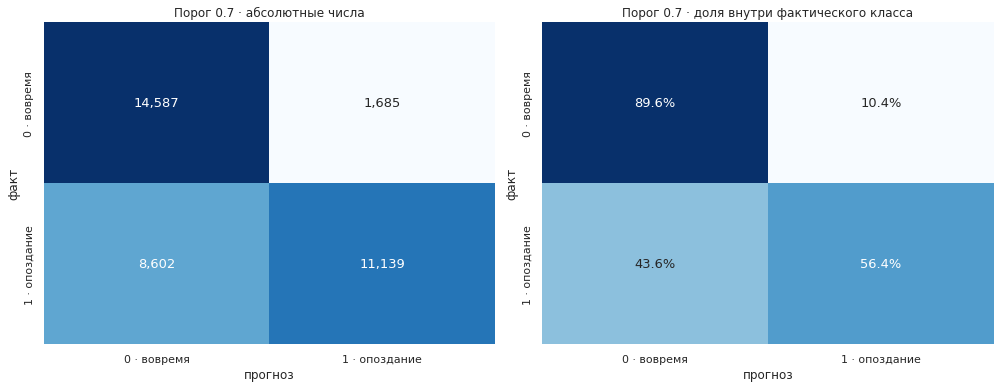

пропущено опозданий: 8,602 из 19,741 = 43.6% (1 − recall)
ложные тревоги:      1,685 из 16,272 = 10.4% (FPR)


In [99]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, norm, title in [(ax[0], None, 'абсолютные числа'),
                       (ax[1], 'true', 'доля внутри фактического класса')]:
    pred = (proba_test >= THRESHOLD).astype(int)
    cm = confusion_matrix(y_test, pred, normalize=norm)
    sns.heatmap(cm, annot=True, fmt=',.0f' if norm is None else '.1%', cmap='Blues',
                cbar=False, ax=a, annot_kws={'fontsize': 13},
                xticklabels=['0 · вовремя', '1 · опоздание'],
                yticklabels=['0 · вовремя', '1 · опоздание'])
    a.set(xlabel='прогноз', ylabel='факт', title=f'Порог {THRESHOLD} · {title}')
plt.tight_layout(); plt.show()

tn, fp, fn, tp = map(int, confusion_matrix(y_test, pred).ravel())
print(f'пропущено опозданий: {fn:,} из {fn + tp:,} = {fn / (fn + tp):.1%} (1 − recall)')
print(f'ложные тревоги:      {fp:,} из {fp + tn:,} = {fp / (fp + tn):.1%} (FPR)')

### Пропуски опозданий по классам shipping_mode

In [100]:
err = df_test.loc[X_test_cl.index, ['shipping_mode']].assign(
    y=y_test.values, pred=(proba_test >= THRESHOLD).astype(int),
    geo_cluster=X_test_cl['geo_cluster'].values,
    behavior_segment=X_test_cl['behavior_segment'].values)

by_mode = (err.groupby('shipping_mode', observed=True)
              .apply(lambda d: pd.Series({
                  'заказов': len(d),
                  'опозданий': d.y.sum(),
                  'recall': d.loc[d.y == 1, 'pred'].mean(),
                  'FN': ((d.y == 1) & (d.pred == 0)).sum(),
                  'FP': ((d.y == 0) & (d.pred == 1)).sum()}))
              .assign(доля_всех_FN=lambda t: t.FN / t.FN.sum()))
display(by_mode.style.format({'recall': '{:.3f}', 'доля_всех_FN': '{:.1%}',
                              'заказов': '{:,.0f}', 'опозданий': '{:,.0f}',
                              'FN': '{:,.0f}', 'FP': '{:,.0f}'})
        .set_caption(f'Ошибки по тарифу на test · порог {THRESHOLD}'))

,заказов,опозданий,recall,FN,FP,доля_всех_FN
shipping_mode,,,,,,
first class,"5,498","5,229",1.000,0,248,0.0%
same day,"1,952",872,1.000,0,36,0.0%
second class,"7,176","5,477",0.920,439,"1,401",5.1%
standard class,"21,387","8,163",0.000,"8,163",0,94.9%


#### Промежуточный вывод

Модель не поднимает флаг ни на одном заказе standard class (recall = 0): все 8 163 опоздания
этого тарифа пропущены, и это 94.9% всех FN. Остальные 439 пропусков (5.1%) приходятся на second class
(recall 0.920); first class и same day пойманы полностью (recall 1.000).
Ложные тревоги тоже в основном в second class: 1 401 из 1 685 (83%).
Пороги 0.5 и 0.7 дают близкие матрицы (recall 0.586 и 0.564): standard class не получает флага
ни при одном из них. На практике модель работает так: «предупреждать по first, second class и
same day после полудня, никогда по standard». Порогом это не изменить. Нужны новые признаки
о заказе: склад, перевозчик, загрузка.

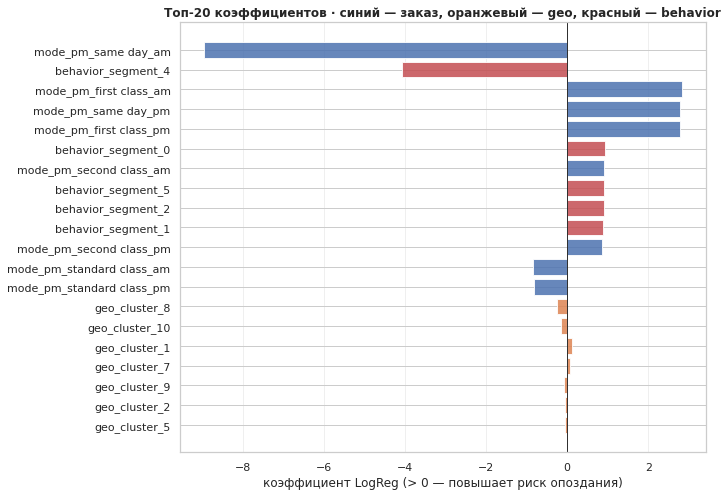

In [101]:
# --- коэффициенты LogReg: направление и сила по уровням ---
prep, clf = final_model[:-1], final_model[-1]
coef = (pd.DataFrame({'колонка': prep.get_feature_names_out(), 'coef': clf.coef_[0]})
          .assign(abs=lambda d: d.coef.abs())
          .sort_values('abs', ascending=False))
coef['группа'] = np.select(
    [coef.колонка.str.contains('geo_cluster'), coef.колонка.str.contains('behavior_segment')],
    ['geo_cluster', 'behavior_segment'], default='заказ')

top = coef.head(20).iloc[::-1]
cmap = {'geo_cluster': '#dd8452', 'behavior_segment': '#c44e52', 'заказ': '#4c72b0'}
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.колонка, top.coef, color=top.группа.map(cmap), alpha=.85)
ax.axvline(0, c='black', lw=.8)
ax.set_xlabel('коэффициент LogReg (> 0 — повышает риск опоздания)')
ax.set_title('Топ-20 коэффициентов · синий — заказ, оранжевый — geo, красный — behavior',
             fontweight='bold')
ax.grid(alpha=.3, axis='x'); plt.tight_layout(); plt.show()

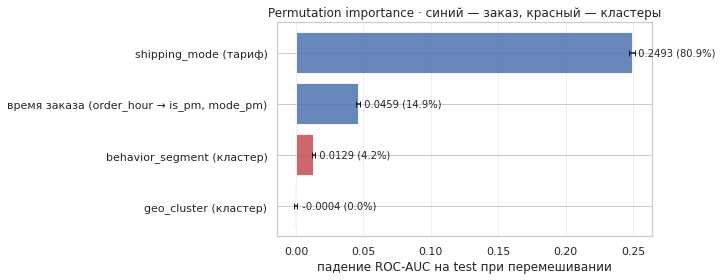

In [102]:
USED_INPUTS = {                      # сырой столбец → что он означает для модели
    'shipping_mode':    'shipping_mode (тариф)',
    'order_date':       'время заказа (order_hour → is_pm, mode_pm)',
    'behavior_segment': 'behavior_segment (кластер)',
    'geo_cluster':      'geo_cluster (кластер)',
}
assert set(USED_INPUTS) <= set(X_test_cl.columns)

perm = permutation_importance(final_model, X_test_cl, y_test, scoring='roc_auc',
                              n_repeats=10, random_state=SEED, n_jobs=-1)
imp = (pd.DataFrame({'вход': X_test_cl.columns,
                     'ΔAUC': perm.importances_mean, 'std': perm.importances_std})
         .query('вход in @USED_INPUTS')
         .assign(признак=lambda d: d['вход'].map(USED_INPUTS),
                 тип=lambda d: np.where(d['вход'].isin(CLUSTER_COLS), 'кластер', 'заказ'))
         .sort_values('ΔAUC', ascending=False).reset_index(drop=True))
imp['ранг'] = np.arange(1, len(imp) + 1)
imp['доля_%'] = (imp['ΔAUC'].clip(lower=0) / imp['ΔAUC'].clip(lower=0).sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(imp['признак'], imp['ΔAUC'], xerr=imp['std'], capsize=3, alpha=.85,
        color=np.where(imp['тип'] == 'кластер', '#c44e52', '#4c72b0'))
ax.invert_yaxis(); ax.grid(alpha=.3, axis='x')
for i, r in imp.iterrows():
    ax.text(max(r['ΔAUC'], 0), i, f'  {r["ΔAUC"]:.4f} ({r["доля_%"]}%)', va='center')
ax.set(xlabel='падение ROC-AUC на test при перемешивании',
       title='Permutation importance · синий — заказ, красный — кластеры')
plt.tight_layout(); plt.show()

#### Промежуточный вывод

Кластерные признаки заняли малую долю. Гипотеза о «чёрных дырах» среди географических районов
не подтвердилась: важность geo_cluster отрицательная (−0.0004, 0.0%), то есть перемешивание
не ухудшает, а в пределах шума даже слегка улучшает прогноз. Поведенческий кластер даёт
небольшую, но заметную долю: 0.0129 (4.2%). По коэффициентам LogReg видно, что этот вклад
почти целиком даёт сегмент 4 (полные возвратчики): коэффициент около −4, у остальных сегментов
(0, 1, 2, 5) около +0.9. Частичные возвратчики (сегмент 3) в топ-20 не попали.
Решающее влияние оказывает тариф доставки (0.2493, 80.9%) и время заказа в сочетании
с тарифом (0.0459, 14.9%). Время заказа важно из-за same day: коэффициент `same day_am`
около −9 (утренние заказы не опаздывают никогда), у `same day_pm` около +2.8.
Наибольший вклад в снижение риска дают утренние заказы same day и полные возвратчики.

### Анализ опозданий по финальным кластерам

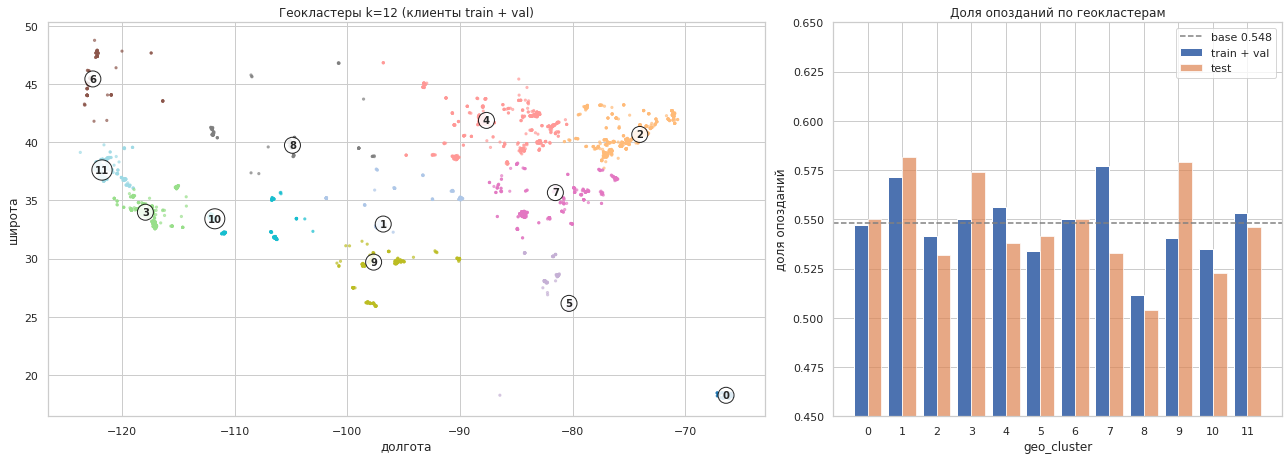

,orders,late_rate,orders_test,late_rate_test
c,,,,
0,55253,0.547,13522,0.550
1,3817,0.572,978,0.582
2,19121,0.541,5186,0.532
3,18342,0.550,4484,0.574
4,15022,0.556,4054,0.538
5,4248,0.534,1202,0.542
6,2156,0.550,518,0.550
7,6345,0.577,1411,0.533
8,2796,0.512,764,0.504


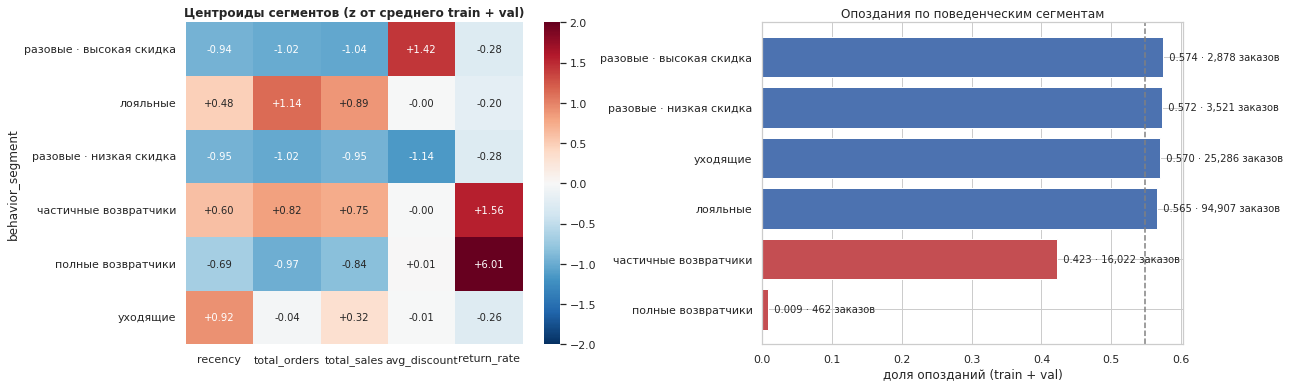

,recency,total_orders,total_sales,avg_discount,return_rate,клиентов_%,orders,late_rate,late_rate_test,название,lift
behavior_segment,,,,,,,,,,,
0,61.000,1.000,189.660,0.170,0.000,17.4%,"2,878",0.574,0.587,разовые · высокая скидка,1.047
1,226.000,6.000,3035.490,0.102,0.000,32.3%,"94,907",0.565,0.561,лояльные,1.030
2,61.000,1.000,230.120,0.040,0.000,21.3%,"3,521",0.572,0.587,разовые · низкая скидка,1.043
3,256.000,5.000,2534.210,0.102,0.250,6.6%,"16,022",0.423,0.418,частичные возвратчики,0.771
4,70.000,1.000,243.220,0.100,1.000,2.0%,462,0.009,0.034,полные возвратчики,0.016
5,410.000,3.000,1350.000,0.100,0.000,20.4%,"25,286",0.570,0.573,уходящие,1.040


In [103]:
geo = GEO_FINAL
seg = RFM_FINAL
cust = cust_idx.join([geo, seg])
cust_tr = cust.loc[full_ids]

def late_by(labels, df_src):
    return (df_src.assign(c=df_src['customer_id'].map(labels))
                  .groupby('c')[TARGET].agg(orders='size', late_rate='mean'))

base = df_full[TARGET].mean()

# ===================== GEO: карта и доля опозданий =====================
g_tr, g_te = late_by(geo, df_full), late_by(geo, df_test)
fig, ax = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={'width_ratios': [1.6, 1]})
smp = cust_tr.sample(min(8000, len(cust_tr)), random_state=SEED)
ax[0].scatter(smp[GEO_COLS[1]], smp[GEO_COLS[0]], c=smp['geo_cluster'],
              cmap='tab20', s=5, alpha=.6)
for k, (la, lo) in cust_tr.groupby('geo_cluster')[GEO_COLS].median().iterrows():
    ax[0].annotate(str(k), (lo, la), ha='center', va='center', fontweight='bold',
                   bbox=dict(boxstyle='circle', fc='white', ec='black', alpha=.85))
ax[0].set(xlabel='долгота', ylabel='широта', title=f'Геокластеры k={GEO_K} (клиенты train + val)')

x = np.arange(GEO_K)
ax[1].bar(x - .2, g_tr.reindex(x).late_rate, .4, label='train + val')
ax[1].bar(x + .2, g_te.reindex(range(GEO_K)).late_rate, .4, label='test', alpha=.7)
ax[1].axhline(base, ls='--', c='gray', label=f'base {base:.3f}')
ax[1].set(xticks=x, ylim=(.45, .65), xlabel='geo_cluster', ylabel='доля опозданий',
          title='Доля опозданий по геокластерам')
ax[1].legend(); plt.tight_layout(); plt.show()
display(g_tr.join(g_te, rsuffix='_test').style.format(
        {'late_rate': '{:.3f}', 'late_rate_test': '{:.3f}'}))

# ===================== RFM: профили (z), размеры, доля опозданий =====================
# номера после переобучения KMeans на train + val
SEG_NAMES = {0: 'разовые · высокая скидка', 1: 'лояльные', 2: 'разовые · низкая скидка',
             3: 'частичные возвратчики', 4: 'полные возвратчики', 5: 'уходящие'}

X_rfm = cust_idx[RFM_COLS].astype('float64')
X_rfm = X_rfm.assign(**{c: np.log1p(X_rfm[c]) for c in RFM_COLS if c in LOG_COLS})
sc = StandardScaler().fit(X_rfm.loc[full_ids])
Z = pd.DataFrame(sc.transform(X_rfm), index=X_rfm.index, columns=RFM_COLS)

z_prof = Z.loc[full_ids].groupby(seg.loc[full_ids]).mean()
s_tr, s_te = late_by(seg, df_full), late_by(seg, df_test)
summary = (cust_tr.groupby('behavior_segment')[RFM_COLS].median()
           .join(cust_tr['behavior_segment'].value_counts(normalize=True).rename('клиентов_%'))
           .join(s_tr).join(s_te['late_rate'].rename('late_rate_test'))
           .assign(название=lambda d: d.index.map(SEG_NAMES), lift=lambda d: d.late_rate / base))

fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))
sns.heatmap(z_prof.rename(index=SEG_NAMES), annot=True, fmt='+.2f', cmap='RdBu_r',
            vmin=-2, vmax=2, ax=ax[0])
ax[0].set_title('Центроиды сегментов (z от среднего train + val)', fontweight='bold')
order = summary.sort_values('late_rate').index
ax[1].barh([SEG_NAMES[i] for i in order], summary.loc[order, 'late_rate'],
           color=['#c44e52' if summary.loc[i, 'lift'] < .9 else '#4c72b0' for i in order])
ax[1].axvline(base, ls='--', c='gray')
for j, i in enumerate(order):
    r = summary.loc[i]
    ax[1].text(r.late_rate, j, f'  {r.late_rate:.3f} · {r.orders:,.0f} заказов', va='center')
ax[1].set(xlabel='доля опозданий (train + val)', title='Опоздания по поведенческим сегментам')
plt.tight_layout(); plt.show()
display(summary.style.format({c: '{:.3f}' for c in RFM_COLS + ['late_rate', 'late_rate_test', 'lift']}
                             | {'клиентов_%': '{:.1%}', 'orders': '{:,.0f}'}))

# ===================== t-SNE в пространстве KMeans =====================
smp_ids = (seg.loc[full_ids].to_frame().groupby('behavior_segment', group_keys=False)
              .sample(frac=min(1, 5000 / len(full_ids)), random_state=SEED).index)
emb = TSNE(n_components=2, perplexity=40, init='pca', random_state=SEED) \
          .fit_transform(Z.loc[smp_ids])
lab = seg.loc[smp_ids].to_numpy()

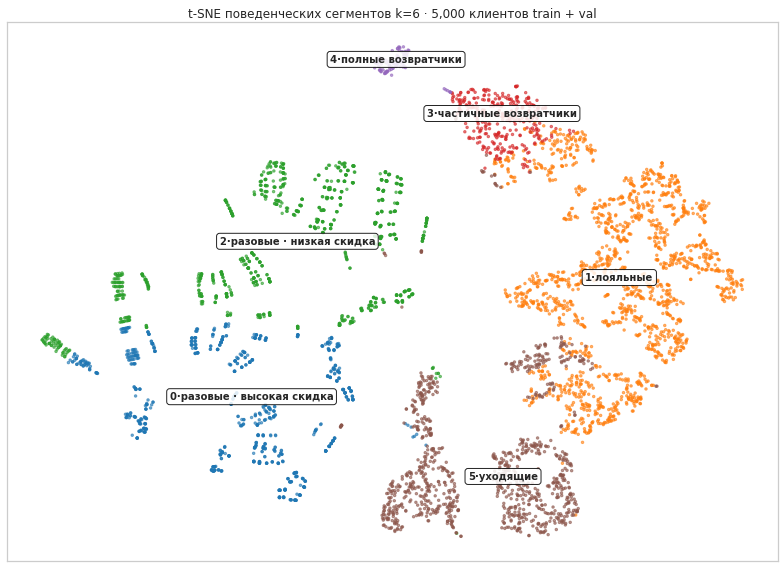

In [104]:
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(emb[:, 0], emb[:, 1], c=lab, cmap='tab10', vmin=-.5, vmax=9.5, s=6, alpha=.6)
for k in range(RFM_K):
    cx, cy = np.median(emb[lab == k], axis=0)
    ax.annotate(f'{k}·{SEG_NAMES[k]}', (cx, cy), ha='center', fontsize=10, fontweight='bold',
                bbox=dict(boxstyle='round', fc='white', ec='black', alpha=.85))
ax.set(xticks=[], yticks=[], title=f't-SNE поведенческих сегментов k={RFM_K} · {len(smp_ids):,} клиентов train + val')
plt.tight_layout(); plt.show()

#### Промежуточный вывод

При переходе на 6 RFM-сегментов частичные возвратчики выделились в отдельный сегмент behavior_segment_4, у которого доля опозданий ниже, и это добавило немного сигнала для модели.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

После перехода к train + validation можно переобучить на объединенных клиентах не только Логрег, но и scaler/KMeans

<div class="alert alert-info"> <b>Комментарии студента:</b> Переобучил и KMeans на train + val.</div>

##  Выводы и рекомендации

Что нужно зафиксировать:

* **Результаты моделирования.** Укажите итоговое значение ROC-AUC на тестовой выборке. Удалось ли вам достичь целевого показателя? Насколько эффективно итоговая модель справляется с выявлением задержек по сравнению с базовыми?
* **Эффективность сегментации.** Сформулируйте вывод о полезности кластеризации. Подтвердилась ли гипотеза о том, что профиль клиента и его географическое положение влияют на риск задержки? Какие именно кластеры — географические или поведенческие — оказались более информативными для модели? Добавьте в раздел визуализации, которые вы получили, работая над проектом.
* **Технический инсайт.** Если вы экспериментировали с разным количеством  кластеров как с гиперпараметром, то укажите, какое количество кластеров K оказалось оптимальным. Кратко поясните, почему слишком большое K может вредить качеству прогноза.
* **Бизнес-рекомендации.** Предложите, как CargaPronto может использовать вашу модель в реальных операциях.

### Результаты моделирования

Лучшая модель — **LogReg + geo_cluster (k=12) + behavior_segment (k=6)**. KMeans и LogReg обучены на train + val.

| Модель | ROC-AUC |
|---|---|
| Dummy | 0.500 |
| LogReg без кластеров (≈ правило «тариф × час») | 0.7581 (CV) · 0.7618 (val) |
| **Итоговая модель** | **0.7731 (CV) · 0.7776 (val) · 0.7701 (test)** |

**Целевой показатель ROC-AUC > 0.75 достигнут** (запас на test 0.020). Std по фолдам 0.0047,
разница test − CV −0.0031: модель стабильна и не переобучена.

При рабочем пороге 0.7 предупреждение получают 35.6% заказов, **precision 0.87**
(9 из 10 предупреждений обоснованы), recall 0.56. Основной тип ошибок — **пропуск задержек**:
не замечено 43.6% опозданий, ложные тревоги приходятся на 10.4% своевременных заказов.
94.9% пропусков — это standard class, где модель не выдаёт ни одного предупреждения:
на имеющихся признаках опоздания внутри этого тарифа неотличимы от своевременных доставок.

По сравнению с базовой моделью без кластеров ROC-AUC вырос на +0.015 (val 0.7618 → 0.7776),
precision — с 0.860 до 0.877. Recall при этом снизился с 0.591 до 0.568.

Линейная модель не уступает CatBoost (val 0.7776 против 0.7767): признаки категориальные,
а единственная значимая нелинейность (ступенька в 12:00 × тариф) задана явно через `mode_pm`.

###  Эффективность сегментации

Рейтинг важности (permutation importance на test): тариф — **81%**, время заказа — **15%**,
behavior_segment — **4%**, geo_cluster — **≈ 0%** (−0.0004). Базовые параметры заказа остались главными.

- **Поведенческие сегменты информативны:** +0.013…+0.017 ROC-AUC на CV. Сигнал даёт `return_rate`:
  у полных возвратчиков (сегмент 4) доля опозданий 0.009, у частичных (сегмент 3) — 0.423
  при base 0.548. Без `return_rate` сегменты дают не более +0.002. Гипотеза подтверждается
  **с оговоркой**: механизм технический (отменённый заказ не может опоздать), а `return_rate`
  посчитан за весь период, включая будущие заказы. Это частичная утечка.
- **Геокластеры неинформативны:** +0.0016 на CV при k = 12 (в пределах шума, std 0.005),
  важность на test отрицательная, порядок зон на test не сохраняется. Гипотеза о «труднодоступных
  районах» не подтвердилась ни при одной детализации.

**Визуализации:** метод локтя и silhouette (гео и поведение); карта геокластеров и доля опозданий по зонам;
центроиды и доля опозданий по поведенческим сегментам; t-SNE сегментов; тепловая карта ΔROC-AUC
по geo_k × rfm_k; матрица ошибок; коэффициенты LogReg; permutation importance.

###  Технический инсайт: число кластеров

Перебор geo_k ∈ {0, 4, 6, 8, 12, 20} × rfm_k ∈ {0, 6, 7, 12, 20, 30} по ROC-AUC (CV). Максимум — 20 × 20 (0.7757).
Правило одной стандартной ошибки выбирает 0 × 6 (0.7711): геокластеры отбор не проходят. Мы оставили
**geo_k = 12, rfm_k = 6** (0.7731): задание требует оба вида кластеров, отставание от максимума
0.0026 меньше std (0.0049), а 6 сегментов можно интерпретировать. Рост rfm_k с 6 до 30 даёт лишь +0.003.

Почему большое K вредит:
- кластеры мельчают, оценка доли опозданий в каждом шумная: модель запоминает шум train;
- после OHE появляются десятки колонок, растёт дисперсия модели;
- границы мелких кластеров нестабильны, новые клиенты распределяются по ним случайнее;
- мелкие сегменты точнее копируют `return_rate`, то есть усиливают утечку, а не полезный сигнал.

### Бизнес-рекомендации для CargaPronto

1. **Внедрить модель как систему предупреждений** при оформлении заказа: p ≥ 0.7 → повысить
   приоритет. Фактически флаг получают first class, second class и same day после полудня.
   Precision 0.87 почти исключает лишнюю работу логистов.
2. **Пересмотреть SLA тарифов.** First class опаздывает в 95% случаев, second class — в 77%:
   обещанный срок недостижим системно. Это проблема норматива, прогнозом её не решить.
3. **Для same day ввести отсечку.** До 12:00 same day не опаздывает никогда (0.000), после — в 96% случаев.
   У остальных тарифов час заказа ничего не меняет. Нужен перенос на следующий день или предупреждение клиенту
   при заказе после полудня.
4. **Собрать данные для standard class** (склад, перевозчик, загрузка, расстояние).
   Без них 94.9% пропусков модели не устранить.

<div class="alert alert-block alert-danger">✍
    

__Комментарий от ревьюера №1__

    
Алексей, по структуре ОК, просьба скорректировать после правок

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №2__

Да, тут согласен

# Финальная очистка кэша

In [105]:
memory.clear(warn=False)
print("✅ Кэш препроцессинга очищен.")

✅ Кэш препроцессинга очищен.


<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №2__

В базовой модели ты отклонился от предложенного в задании набора из шести признаков: item_price был исключен заранее, а category_name, order_month и order_weekday проверялись через ablation. Для более прямого соответствия заданию можно было сначала зафиксировать baseline на всех шести признаках, а уже затем проводить отбор и ablation

<div style="border:solid blue 3px; padding: 20px">
<div class="alert alert-block alert-success">✔️
    

__Коментарий от ревьюера №2__
    

В остальном всё чудно😊. Твой проект так и просится на github =)   
    
Поздравляю с успешным завершением проекта 😊👍
И желаю успехов в новых работах 😊
    


</div>